In [1]:
# NB-04: Búsqueda en Espacios de Estados
# Generado para: Andrés Hormazábal — UDP
# Parte del sistema de 25 notebooks de estudio ML/IA
# Fecha de generación: 2026-10-29

# NB-04: Búsqueda en Espacios de Estados
**Bloque:** 2 — IA Clásica (curso CIT-2013, AIMA)
**Base bibliográfica:** AIMA 4.ª ed., cap. 3 (*Solving Problems by Searching*) y cap. 4 (*Search in Complex Environments*) · CLRS, cap. 22 y 24 (grafos y caminos mínimos) como referencia de complejidad
**Prerequisitos:** NB-03 (normas y distancias como heurísticas; descenso de gradiente como búsqueda local continua, sec. 7.1; probabilidad y `exp` estable, sec. 6). Python básico con clases.

> 🎯 **Por qué este notebook importa en tu carrera:** la búsqueda es la base de la IA clásica y concentra buena parte de la **Solemne 1** de IA (≈ 30–40 %). Además es el "esqueleto" de muchísimo más: planificación, CSP (NB-06), juegos (NB-05), enrutamiento de redes, decodificación de Viterbi (NB-08) y optimización de hiperparámetros.

## Objetivos de Aprendizaje
Al completar este notebook serás capaz de:
1. **Formular** un problema como búsqueda (estado inicial, acciones, modelo de transición, test de meta, costo) y **implementarlo** en un marco de código reutilizable.
2. **Ejecutar a mano y en código** BFS, DFS, costo uniforme, profundización iterativa, *greedy* y A\*, y **justificar** cuándo cada uno es completo y óptimo.
3. **Diseñar y comparar heurísticas** (admisibles y consistentes) para el 8-puzzle, midiendo su efecto con el factor de ramificación efectivo.
4. **Aplicar búsqueda local** (*hill climbing*, *simulated annealing*, algoritmos genéticos) a problemas de optimización como N-reinas y el viajante (TSP), y explicar por qué se atascan.
5. **Elegir** el algoritmo adecuado según el problema, y rellenar de memoria la tabla comparativa de completitud, optimalidad y complejidad.

## Mapa de Conexiones
| Curso / Área | Relevancia |
|---|---|
| **IA (CIT-2013)** | AIMA cap. 3–4: tema central de la Solemne 1. Todo el notebook está pensado para estudiarlo. |
| Big Data (CIT-2309) | Búsqueda en grafos enormes (rutas, redes sociales): Dijkstra/A\* con *landmarks*; el costo de memoria de A\* motiva IDA\* y métodos aproximados. |
| Comunicaciones Digitales | **Dijkstra = costo uniforme** (enrutamiento OSPF); **Viterbi = camino más corto en un *trellis*** (decodificación, NB-08). |
| Sistemas Distribuidos | Enrutamiento y descubrimiento de rutas en redes; búsqueda paralela y su sobrecarga de coordinación. |
| Tesis SNN/Ojo | **Búsqueda local para ajustar hiperparámetros** del ecualizador (nº de coeficientes, retardo, regularización): Ejercicio 3. |
| Notebooks relacionados | NB-03 (base), NB-05 (juegos: búsqueda con adversario), NB-06 (CSP: backtracking = DFS), NB-08 (HMM/Viterbi), NB-11 (gradiente) |

## Tabla de contenidos
1. Marco teórico: agentes, problemas y árboles de búsqueda
2. Configuración
3. Un marco de búsqueda reutilizable (`Problem`, `Node`, `best_first_search`)
4. Búsqueda no informada e informada en el mapa de Rumania
5. Búsqueda en una grilla (laberinto)
6. El 8-puzzle: heurísticas y factor de ramificación efectivo
7. Búsqueda local: *hill climbing*, *simulated annealing*, algoritmos genéticos
8. Entornos complejos (AIMA 4.3–4.5): panorama
9. Tabla comparativa
10. 📋 Cheat Sheet
11. Conexiones con el mundo real
12. Ejercicios progresivos
13. Resumen y siguiente paso

## 1. Marco teórico

### La intuición: un GPS que piensa
Cuando le pides una ruta a tu GPS, ocurre algo así: el mapa es un conjunto de **estados** (intersecciones), cada **acción** (tomar una calle) te lleva a otro estado con un **costo** (distancia o tiempo), y quieres llegar al estado **meta** con costo mínimo. Un agente que resuelve problemas "mira hacia adelante" simulando mentalmente secuencias de acciones antes de actuar. Eso es **búsqueda**.

### Formulación de un problema (AIMA 3.1)
Un problema de búsqueda queda definido por cinco componentes:

| Componente | Notación | Ejemplo (rutas en Rumania) | Ejemplo (8-puzzle) |
|---|---|---|---|
| Espacio de estados | $S$ | las 20 ciudades | las 9!/2 = 181 440 configuraciones alcanzables |
| Estado inicial | $s_0$ | `Arad` | un tablero revuelto |
| Acciones | $\text{ACTIONS}(s)$ | carreteras que salen de $s$ | mover el hueco ↑ ↓ ← → |
| Modelo de transición | $\text{RESULT}(s,a)$ | la ciudad destino | el tablero tras el movimiento |
| Test de meta | $\text{IS-GOAL}(s)$ | ¿es `Bucharest`? | ¿está ordenado? |
| Costo de acción | $c(s,a,s')$ | distancia en km | 1 por movimiento |

Una **solución** es una secuencia de acciones del estado inicial a la meta; es **óptima** si su costo de camino es mínimo.

### El árbol de búsqueda y la frontera
Los algoritmos construyen un **árbol de búsqueda**: la raíz es $s_0$, y se **expande** un nodo generando a sus hijos. Mantienen una **frontera** (*frontier*) de nodos generados pero aún no expandidos. Toda la diferencia entre algoritmos está en **qué nodo de la frontera expandir primero**.

```
                 Arad (raíz)                    frontera inicial = {Arad}
              ┌──────┼──────┐                   expandir Arad → frontera = {Sibiu, Timisoara, Zerind}
           Sibiu  Timisoara  Zerind             ¿cuál expandir ahora?  ← aquí se distinguen BFS, DFS, UCS, A*…
        ┌───┬───┬───┐
   Arad Fagaras Oradea R.Vilcea
    ↑
  ¡Cuidado! Arad vuelve a aparecer: un estado repetido (ciclo). Sin control, DFS puede recorrerlo infinitamente.
```

**Búsqueda en grafo vs en árbol:** si recuerdas los estados ya alcanzados (`reached`), evitas repetir trabajo y ciclos; cuesta memoria. AIMA usa por defecto la versión de grafo.

### Una sola idea para todos los algoritmos: *best-first search*
Elige siempre el nodo de la frontera con menor valor de una **función de evaluación** $f(n)$. Cambiando $f$ obtienes los algoritmos clásicos:

| Algoritmo | $f(n)$ | Idea |
|---|---|---|
| Amplitud (BFS) | profundidad $(n)$ | expandir lo más superficial |
| Costo uniforme (UCS / Dijkstra) | $g(n)$ | expandir lo más barato desde el origen |
| *Greedy* | $h(n)$ | expandir lo que *parece* más cercano a la meta |
| **A\*** | $g(n)+h(n)$ | costo ya pagado + costo estimado restante |
| A\* ponderado | $g(n)+W\cdot h(n)$ | sacrifica optimalidad por velocidad ($W>1$) |

Donde $g(n)$ es el costo real desde la raíz y $h(n)$ es una **heurística**: una estimación del costo restante hasta la meta. DFS e IDS no encajan en este molde (usan pila / profundidad) pero se estudian junto a ellos.

### Heurísticas: admisible y consistente (AIMA 3.5)
- **Admisible:** *nunca sobreestima* el costo real: $h(n)\le h^*(n)$. Ejemplo: la distancia en línea recta nunca supera la distancia por carretera.
- **Consistente** (monótona): $h(n)\le c(n,a,n')+h(n')$, la **desigualdad triangular**. Toda heurística consistente es admisible.
- **Teorema:** A\* con búsqueda en **árbol** es óptimo si $h$ es admisible; con búsqueda en **grafo**, si $h$ es consistente (así, el primer camino que llega a un estado ya es el mejor).
- **Dominancia:** si $h_2(n)\ge h_1(n)$ para todo $n$ (ambas admisibles), $h_2$ domina a $h_1$ y A\* con $h_2$ expande **menos** nodos.
- **Cómo se inventan heurísticas:** resolviendo una **versión relajada** del problema (quitar restricciones). Si en el 8-puzzle las fichas pudieran "saltar" a su lugar, obtienes *fichas fuera de lugar*; si pudieran deslizarse sobre otras, la **distancia Manhattan**.

### Métricas: cómo se comparan los algoritmos (AIMA 3.3.2)
Con $b$ = factor de ramificación, $d$ = profundidad de la solución menos profunda, $m$ = profundidad máxima del árbol, $C^*$ = costo óptimo y $\epsilon$ = costo mínimo de una acción:
- **Completitud:** ¿siempre encuentra una solución si existe?
- **Optimalidad:** ¿la solución es de costo mínimo?
- **Complejidad temporal y espacial:** nodos generados / máximo nodos en memoria. Se expresan en $b$, $d$, $m$.
- **Factor de ramificación efectivo** $b^*$: el $b$ que tendría un árbol uniforme de profundidad $d$ con $N+1$ nodos, es decir $N+1=1+b^*+(b^*)^2+\dots+(b^*)^d$. Mide la "calidad" de una heurística: más cerca de 1 es mejor.

### Búsqueda local (AIMA cap. 4)
A veces **no importa el camino**, solo el estado final (colocar 8 reinas, diseñar un chip, ajustar hiperparámetros). La búsqueda local mantiene **un solo estado** (o una población) y lo mejora moviéndose a vecinos, usando memoria constante. Piensa en un caminante con niebla que solo ve su entorno inmediato y trata de subir (o bajar) la montaña:

```
 valor
   │            ╱╲   ← máximo global
   │    ╱╲     ╱  ╲
   │   ╱  ╲___╱    ╲      Hill climbing se detiene en el primer pico que alcanza (máximo local),
   │  ╱ máx. local   ╲     o se queda quieto en una meseta (plateau). Simulated annealing y los
   │ ╱               ╲    algoritmos genéticos añaden aleatoriedad para escapar.
   └──────────────────────► estado
```
Pierden **completitud y optimalidad**, pero resuelven problemas enormes donde la búsqueda sistemática es imposible. (Y el descenso de gradiente que viste en NB-03 sec. 7.1 es exactamente *hill climbing* en un espacio continuo.)

## 2. Configuración
Importamos solo lo necesario. `networkx` nos ayudará a dibujar el mapa de Rumania; el resto de los algoritmos los implementamos nosotros, desde cero, para entenderlos.

In [2]:
# === Imports ===
# Estándar
import os, sys, time, math, heapq, itertools, warnings
from collections import deque, defaultdict
from dataclasses import dataclass, field
from typing import Any, Callable, Iterable
warnings.filterwarnings("ignore")

# Datos y cómputo
import numpy as np
import pandas as pd
from scipy.optimize import brentq              # para el factor de ramificación efectivo
from scipy.spatial.distance import cdist        # matriz de distancias entre ciudades (ver NB-03)
from numpy.lib.stride_tricks import sliding_window_view

# Grafos y visualización
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import display

# === Configuración ===
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)          # generador moderno, se pasa explícitamente (ver NB-03 sec. 6)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 11
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"      # trae los símbolos matemáticos que usamos en las figuras
pd.set_option("display.precision", 2)

print("✅ Entorno listo")

✅ Entorno listo


## 3. Un marco de búsqueda reutilizable

**Por qué construir un marco:** si implementas BFS para Rumania, otro para el 8-puzzle y otro para el laberinto, repites el 80 % del código. AIMA propone separar **el problema** (qué es un estado, qué acciones hay) de **el algoritmo** (cómo se explora). Así, cada algoritmo se escribe una vez y funciona para cualquier problema: es el patrón de diseño que usarás también en NB-05 y NB-06.

Tres piezas:
- `Problem`: la formulación (cinco componentes de la teoría). Cada problema concreto **hereda** de esta clase.
- `Node`: un nodo del árbol de búsqueda (estado + padre + acción + costo acumulado $g$).
- `SearchResult`: la solución más **estadísticas** (nodos expandidos, generados, memoria máxima), que usaremos para comparar algoritmos con números y no solo con teoría.

In [3]:
class Problem:
    # Formulación abstracta (AIMA 3.1). Los estados deben ser HASHEABLES (tuplas, strings, ints) para poder guardarlos en `reached`
    def __init__(self, initial, goal=None):
        self.initial, self.goal = initial, goal

    def actions(self, state) -> Iterable:               # qué puedo hacer en `state`
        raise NotImplementedError

    def result(self, state, action):                    # a qué estado llego
        raise NotImplementedError

    def is_goal(self, state) -> bool:
        return state == self.goal

    def action_cost(self, state, action, next_state) -> float:
        return 1.0                                      # por defecto, todas las acciones cuestan lo mismo

    def h(self, node) -> float:                         # heurística: 0 = "no sé nada" (equivale a no usar información)
        return 0.0


@dataclass(eq=False)
class Node:
    state: Any
    parent: "Node | None" = None
    action: Any = None
    path_cost: float = 0.0                              # g(n): costo real desde la raíz
    depth: int = 0

    def path_states(self):
        node, out = self, []
        while node:
            out.append(node.state); node = node.parent
        return out[::-1]

    def path_actions(self):
        node, out = self, []
        while node.parent:
            out.append(node.action); node = node.parent
        return out[::-1]


def expand(problem: Problem, node: Node):
    # Genera los hijos de `node`: aquí se "consulta" el problema; el algoritmo nunca mira dentro del estado
    s = node.state
    for a in problem.actions(s):
        s2 = problem.result(s, a)
        yield Node(s2, node, a, node.path_cost + problem.action_cost(s, a, s2), node.depth + 1)


@dataclass
class SearchResult:
    node: "Node | None"                                  # None = no se encontró solución
    expanded: list = field(default_factory=list)         # estados en el orden en que se expandieron
    generated: int = 0
    max_frontier: int = 0
    time_ms: float = 0.0
    cutoff: bool = False                                 # True = se agotó el límite (de profundidad o de nodos), no es "no hay solución"

    @property
    def found(self): return self.node is not None
    @property
    def cost(self): return self.node.path_cost if self.found else math.inf
    @property
    def length(self): return self.node.depth if self.found else None

Ahora el algoritmo central, **best-first search** (AIMA Fig. 3.7). Tres detalles de implementación que importan:

1. La frontera es una **cola de prioridad** (`heapq`) ordenada por $f(n)$. Añadimos un **contador** como segundo criterio de orden: así, ante empates de $f$, gana el nodo más antiguo (FIFO) y, de paso, Python nunca intenta comparar dos objetos `Node` (lo que lanzaría un `TypeError`).
2. `reached` guarda el **mejor nodo conocido** para cada estado. Si encontramos un camino **más barato** a un estado ya visto, lo reemplazamos (esto es lo que permite que A\* sea óptimo con heurísticas consistentes).
3. Si un nodo antiguo ya fue superado por uno mejor, lo descartamos al sacarlo de la frontera (*lazy deletion*): más eficiente que buscarlo y borrarlo.

In [4]:
def best_first_search(problem: Problem, f: Callable[[Node], float]) -> SearchResult:
    t0 = time.perf_counter()
    root = Node(problem.initial)
    frontier, counter = [(f(root), 0, root)], 1
    reached = {problem.initial: root}
    res = SearchResult(None, generated=1, max_frontier=1)
    while frontier:
        _, _, node = heapq.heappop(frontier)
        if reached[node.state] is not node:             # nodo "viejo": ya hay uno mejor para este estado
            continue
        if problem.is_goal(node.state):                 # test de meta al EXPANDIR (necesario para la optimalidad de UCS/A*)
            res.node = node; break
        res.expanded.append(node.state)
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (f(child), counter, child)); counter += 1; res.generated += 1
        res.max_frontier = max(res.max_frontier, len(frontier))
    res.time_ms = (time.perf_counter() - t0) * 1e3
    return res

# Cada algoritmo clásico es solo una elección de f(n):
def uniform_cost_search(p):          return best_first_search(p, lambda n: n.path_cost)
def greedy_search(p):                return best_first_search(p, lambda n: p.h(n))
def astar_search(p, W=1.0):          return best_first_search(p, lambda n: n.path_cost + W * p.h(n))

> **NOTA (test de meta al generar vs al expandir):** el test de meta puede hacerse cuando el nodo **se genera** (más rápido: ahorra expansiones) o cuando **se expande**. Para **BFS** con costos iguales, hacerlo al generar sigue siendo óptimo y ahorra un nivel de nodos. Para **UCS y A\*** *debe* hacerse al expandir: el primer camino que *genera* la meta no tiene por qué ser el más barato.

Los otros algoritmos usan estructuras más simples: BFS una **cola FIFO**, DFS una **pila LIFO**. En DFS controlamos cómo evitar los ciclos con el parámetro `check`:
- `"none"`: búsqueda en **árbol** pura (¡puede ciclar para siempre!, por eso añadimos un tope de nodos);
- `"cycle"`: descarta hijos que repiten un estado **de su propio camino** (memoria $O(bm)$);
- `"graph"`: recuerda **todos** los estados alcanzados (memoria $O(\text{estados})$).

In [5]:
def is_cycle(node: Node) -> bool:
    s, anc = node.state, node.parent
    while anc:
        if anc.state == s: return True
        anc = anc.parent
    return False


def breadth_first_search(problem: Problem) -> SearchResult:
    t0 = time.perf_counter()
    root = Node(problem.initial); res = SearchResult(None, generated=1, max_frontier=1)
    if problem.is_goal(root.state):
        res.node = root; return res
    frontier, reached = deque([root]), {problem.initial}      # FIFO: lo más superficial primero
    while frontier:
        node = frontier.popleft(); res.expanded.append(node.state)
        for child in expand(problem, node):
            if problem.is_goal(child.state):                  # test al GENERAR (válido en BFS con costos iguales)
                res.node = child; res.generated += 1; res.time_ms = (time.perf_counter() - t0) * 1e3; return res
            if child.state not in reached:
                reached.add(child.state); frontier.append(child); res.generated += 1
        res.max_frontier = max(res.max_frontier, len(frontier))
    res.time_ms = (time.perf_counter() - t0) * 1e3
    return res


def depth_first_search(problem: Problem, check="graph", limit=None, max_nodes=200_000) -> SearchResult:
    t0 = time.perf_counter()
    root = Node(problem.initial); res = SearchResult(None, generated=1, max_frontier=1)
    stack, reached = [root], {problem.initial}                 # LIFO: lo más profundo primero
    while stack:
        node = stack.pop()
        if problem.is_goal(node.state):
            res.node = node; break
        if limit is not None and node.depth >= limit:           # depth-limited: no pasamos del límite
            res.cutoff = True; continue
        res.expanded.append(node.state)
        if len(res.expanded) >= max_nodes:                      # red de seguridad contra bucles infinitos
            res.cutoff = True; break
        for child in reversed(list(expand(problem, node))):     # reversed → se explora primero la 1.ª acción
            if check == "graph":
                if child.state in reached: continue
                reached.add(child.state)
            elif check == "cycle" and is_cycle(child):
                continue
            stack.append(child); res.generated += 1
        res.max_frontier = max(res.max_frontier, len(stack))
    res.time_ms = (time.perf_counter() - t0) * 1e3
    return res


def iterative_deepening_search(problem: Problem, max_depth=60) -> SearchResult:
    # Repite DFS con límite 0, 1, 2, ...: memoria de DFS + completitud y optimalidad (costos iguales) de BFS
    total = SearchResult(None); t0 = time.perf_counter()
    for limit in range(max_depth + 1):
        r = depth_first_search(problem, check="cycle", limit=limit)
        total.expanded += r.expanded; total.generated += r.generated; total.max_frontier = max(total.max_frontier, r.max_frontier)
        if r.found:
            total.node = r.node; break
        if not r.cutoff:                                        # se agotó el árbol sin cortes: no hay solución
            break
    total.time_ms = (time.perf_counter() - t0) * 1e3
    return total

**Qué hicimos:** definimos todo el "motor". Nota que ningún algoritmo conoce nada sobre ciudades o puzzles: solo llaman a `actions`, `result`, `is_goal`, `action_cost` y `h`. Para resolver un problema nuevo bastará con **heredar de `Problem`**.

### ⚠️ Troubleshooting

**Error:** `TypeError: '<' not supported between instances of 'Node' and 'Node'`
**Por qué:** pusiste tuplas `(f, nodo)` en `heapq` y, ante un empate de `f`, Python intenta comparar los nodos.
**Solución:** incluye un contador único como segundo elemento `(f, contador, nodo)`, como hacemos arriba.

**Error:** `TypeError: unhashable type: 'list'` (o `'numpy.ndarray'`)
**Por qué:** guardaste el estado como lista o array; `reached` necesita estados **hasheables**.
**Solución:** representa los estados como **tuplas** (`tuple(lista)`), strings o enteros.

**Síntoma:** la búsqueda "no termina nunca".
**Por qué:** búsqueda en **árbol** (sin `reached` ni chequeo de ciclos) sobre un grafo con ciclos, o un problema sin solución con espacio infinito.
**Solución:** usa búsqueda en grafo (`check="graph"`) y/o un límite de nodos/profundidad.

## 4. Búsqueda en el mapa de Rumania

Es el ejemplo canónico de AIMA (Fig. 3.1): ir de **Arad a Bucarest**. El grafo tiene 20 ciudades y las carreteras tienen distancias en km. Para los algoritmos informados usaremos como heurística la **distancia en línea recta** a Bucarest ($h_{SLD}$), que es admisible (por carretera nunca se llega más rápido que en línea recta).

In [6]:
ROADS = [("Arad", "Zerind", 75), ("Arad", "Sibiu", 140), ("Arad", "Timisoara", 118), ("Zerind", "Oradea", 71),
         ("Oradea", "Sibiu", 151), ("Timisoara", "Lugoj", 111), ("Lugoj", "Mehadia", 70), ("Mehadia", "Drobeta", 75),
         ("Drobeta", "Craiova", 120), ("Craiova", "Rimnicu Vilcea", 146), ("Craiova", "Pitesti", 138),
         ("Sibiu", "Fagaras", 99), ("Sibiu", "Rimnicu Vilcea", 80), ("Rimnicu Vilcea", "Pitesti", 97),
         ("Fagaras", "Bucharest", 211), ("Pitesti", "Bucharest", 101), ("Bucharest", "Giurgiu", 90),
         ("Bucharest", "Urziceni", 85), ("Urziceni", "Hirsova", 98), ("Hirsova", "Eforie", 86),
         ("Urziceni", "Vaslui", 142), ("Vaslui", "Iasi", 92), ("Iasi", "Neamt", 87)]
H_SLD = {"Arad": 366, "Bucharest": 0, "Craiova": 160, "Drobeta": 242, "Eforie": 161, "Fagaras": 176, "Giurgiu": 77,
         "Hirsova": 151, "Iasi": 226, "Lugoj": 244, "Mehadia": 241, "Neamt": 234, "Oradea": 380, "Pitesti": 100,
         "Rimnicu Vilcea": 193, "Sibiu": 253, "Timisoara": 329, "Urziceni": 80, "Vaslui": 199, "Zerind": 374}
# Posiciones esquemáticas (solo para dibujar el mapa; no son coordenadas geográficas reales)
POS = {"Arad": (91, 492), "Bucharest": (400, 327), "Craiova": (253, 288), "Drobeta": (165, 299), "Eforie": (562, 293),
       "Fagaras": (305, 449), "Giurgiu": (375, 270), "Hirsova": (534, 350), "Iasi": (473, 506), "Lugoj": (165, 379),
       "Mehadia": (168, 339), "Neamt": (406, 537), "Oradea": (131, 571), "Pitesti": (320, 368), "Rimnicu Vilcea": (233, 410),
       "Sibiu": (207, 457), "Timisoara": (94, 410), "Urziceni": (456, 350), "Vaslui": (509, 444), "Zerind": (108, 531)}

ROMANIA = defaultdict(dict)
for a_, b_, d_ in ROADS:
    ROMANIA[a_][b_] = d_; ROMANIA[b_][a_] = d_              # carreteras bidireccionales

class RouteProblem(Problem):
    def actions(self, s):              return list(ROMANIA[s])             # la "acción" es ir a una ciudad vecina
    def result(self, s, a):            return a
    def action_cost(self, s, a, s2):   return ROMANIA[s][s2]
    def h(self, node):                 return H_SLD[node.state] if self.goal == "Bucharest" else 0.0   # H_SLD es hacia Bucarest

print(f"{len(ROMANIA)} ciudades, {len(ROADS)} carreteras")

20 ciudades, 23 carreteras


### 4.1 Primer experimento: ¿qué encuentra cada algoritmo?
Ejecutamos todos sobre `Arad → Bucharest` y comparamos **costo** de la solución, **nodos expandidos**, **generados** y **memoria** (tamaño máximo de la frontera). Antes de mirar los números, haz tu predicción: ¿cuál dará la ruta más corta en km? ¿cuál expandirá menos nodos?

In [7]:
def run_all(problem, include=("BFS", "DFS", "IDS", "UCS", "Greedy", "A*"), optimal_cost=None):
    algos = {"BFS": breadth_first_search, "DFS": depth_first_search, "IDS": iterative_deepening_search,
             "UCS": uniform_cost_search, "Greedy": greedy_search, "A*": astar_search}
    rows = []
    for name in include:
        r = algos[name](problem)
        rows.append({"algoritmo": name, "costo": r.cost, "pasos": r.length, "expandidos": len(r.expanded),
                     "generados": r.generated, "frontera_máx": r.max_frontier, "ms": round(r.time_ms, 2),
                     "óptimo": (None if optimal_cost is None else bool(r.found and abs(r.cost - optimal_cost) < 1e-9))})
    return pd.DataFrame(rows).set_index("algoritmo")

route = RouteProblem("Arad", "Bucharest")
opt_cost = uniform_cost_search(route).cost
table_ro = run_all(route, optimal_cost=opt_cost)
display(table_ro)
for name, algo in [("UCS", uniform_cost_search), ("Greedy", greedy_search), ("BFS", breadth_first_search)]:
    print(f"{name:7s}: {' → '.join(algo(route).node.path_states())}")

,costo,pasos,expandidos,generados,frontera_máx,ms,óptimo
algoritmo,,,,,,,
BFS,450.0,3,6,9,4,0.08,False
DFS,450.0,3,5,8,3,0.05,False
IDS,450.0,3,11,25,4,0.25,False
UCS,418.0,4,12,14,4,0.14,True
Greedy,450.0,3,3,8,5,0.04,False
A*,418.0,4,5,11,6,0.05,True


UCS    : Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest
Greedy : Arad → Sibiu → Fagaras → Bucharest
BFS    : Arad → Sibiu → Fagaras → Bucharest


**Qué deberías ver:**
- **UCS y A\*** encuentran la ruta **óptima** `Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest` con costo **418 km**; A\* expande **menos nodos** porque la heurística lo "orienta" hacia Bucarest.
- **Greedy** y **BFS** llegan por `Arad → Sibiu → Fagaras → Bucharest` (**450 km**): *greedy* se deja engañar porque Fagaras *parece* más cerca de la meta (176 vs 193 en línea recta) pero el último tramo es largo (211 km); BFS minimiza el **número de pasos** (3), no los km.
- **DFS** no tiene garantía alguna: encuentra *una* ruta, la que le dicte su orden de exploración (aquí coincide con la de BFS por casualidad; en el laberinto de la sección 5 verás una ruta enormemente más larga).
- **IDS** encuentra la ruta de menos pasos, igual que BFS, con memoria mínima (frontera pequeña) a costa de repetir expansiones.

> Esta es la lección más importante del capítulo: **"óptimo" siempre significa "óptimo según algún criterio"**. BFS es óptimo en *número de pasos*, UCS y A\* en *costo de camino*. Define bien tu criterio antes de elegir.

Veamos *cómo se ve* cada exploración en el mapa: los nodos se colorean por **orden de expansión** (claro = primero, oscuro = último) y la ruta final va en azul.

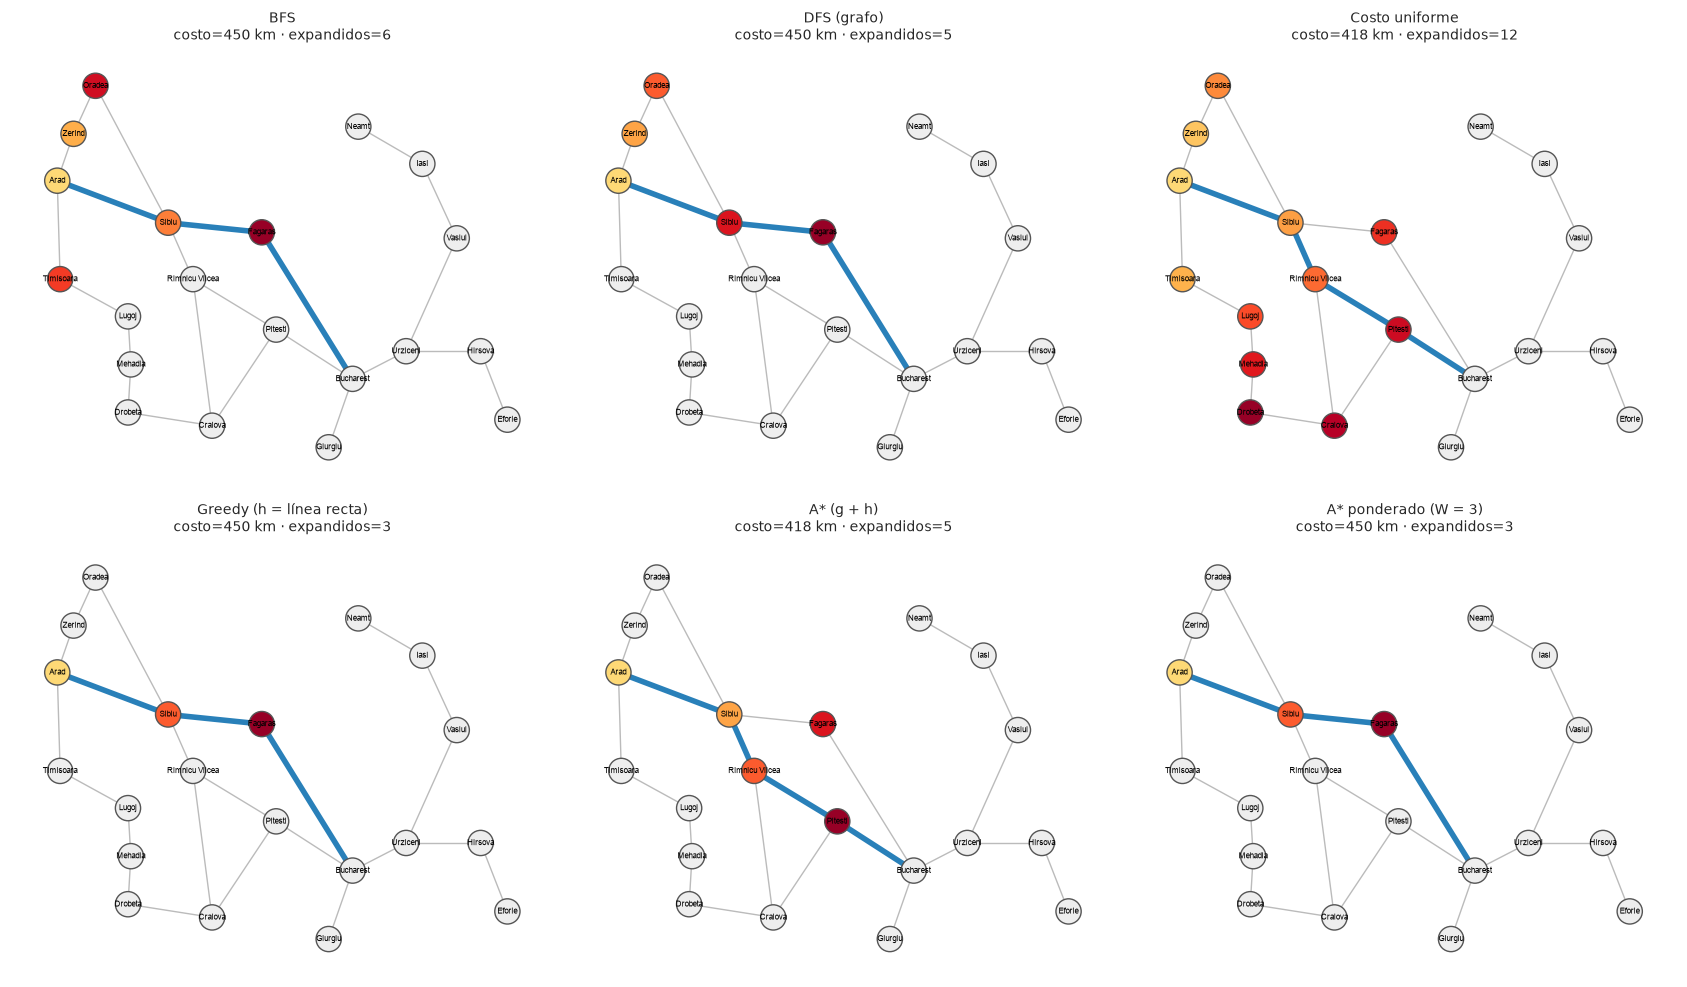

In [8]:
def draw_search(ax, problem_graph, pos, res, title):
    G = nx.Graph()
    for a_, b_, d_ in ROADS: G.add_edge(a_, b_, w=d_)
    order = {s: i for i, s in enumerate(res.expanded)}
    colors = [plt.cm.YlOrRd(0.25 + 0.7 * order[n] / max(len(order) - 1, 1)) if n in order else "#eeeeee" for n in G.nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#bbbbbb", width=1)
    if res.found:
        path = res.node.path_states()
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=list(zip(path[:-1], path[1:])), edge_color="#2980b9", width=4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=330, edgecolors="#555555")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
    ax.set_title(f"{title}\ncosto={res.cost:.0f} km · expandidos={len(res.expanded)}", fontsize=10); ax.axis("off")

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
runs = [("BFS", breadth_first_search(route)), ("DFS (grafo)", depth_first_search(route)), ("Costo uniforme", uniform_cost_search(route)),
        ("Greedy (h = línea recta)", greedy_search(route)), ("A* (g + h)", astar_search(route)), ("A* ponderado (W = 3)", astar_search(route, W=3))]
for ax, (name, r) in zip(axes.ravel(), runs):
    draw_search(ax, ROMANIA, POS, r, name)
plt.tight_layout(); plt.show()

**Qué deberías ver:** seis mapas. En **BFS** y **UCS** el color se expande como una onda circular desde Arad (exploran por "capas" de pasos o de costo, respectivamente); **DFS** se adentra por un lado (a veces recorriendo ciudades lejanas); **Greedy** y **A\*** concentran la exploración en el corredor Arad–Sibiu–Bucarest, con muchos nodos sin colorear (nunca expandidos); y **A\* ponderado** con $W=3$ se parece más a *greedy*: menos nodos pero ruta peor o igual.

### 4.2 Verificando la teoría con código
Dos propiedades que AIMA demuestra, aquí las **comprobamos numéricamente**:

1. $h_{SLD}$ es **consistente**: $h(u)\le c(u,v)+h(v)$ para *toda* carretera, en ambos sentidos.
2. Con una heurística **consistente**, A\* **nunca expande dos veces el mismo estado** y los valores $f$ de los nodos expandidos son **no decrecientes**.

In [9]:
violations = [(u, v) for u in ROMANIA for v in ROMANIA[u] if H_SLD[u] > ROMANIA[u][v] + H_SLD[v]]
print(f"Violaciones de consistencia en las {2*len(ROADS)} aristas dirigidas: {len(violations)}")

res_a = astar_search(route)
# g(n) de cada estado expandido = su costo óptimo desde Arad (lo obtenemos con UCS hacia cada estado)
ucs_cost = {s: uniform_cost_search(RouteProblem("Arad", s)).cost for s in res_a.expanded}
f_values = [ucs_cost[s] + H_SLD[s] for s in res_a.expanded]
print("Orden de expansión de A*:", res_a.expanded)
print("f = g + h en ese orden   :", [int(v) for v in f_values])
print("¿f no decreciente?       :", all(b >= a - 1e-9 for a, b in zip(f_values, f_values[1:])))
print("¿algún estado expandido 2 veces?:", len(res_a.expanded) != len(set(res_a.expanded)))

Violaciones de consistencia en las 46 aristas dirigidas: 0
Orden de expansión de A*: ['Arad', 'Sibiu', 'Rimnicu Vilcea', 'Fagaras', 'Pitesti']
f = g + h en ese orden   : [366, 393, 413, 415, 417]
¿f no decreciente?       : True
¿algún estado expandido 2 veces?: False


**Qué deberías ver:** 0 violaciones, los valores $f$ **crecientes** (A\* avanza "por contornos" de costo estimado, igual que UCS lo hace por contornos de costo real) y ningún estado repetido. Si cambias a una heurística no consistente, estas propiedades pueden romperse (lo harás en el 🔧 4-3).

### 🔧 Pruébalo tú mismo

### 🔧 Pruébalo tú mismo

**4-1. Otro trayecto:** corre `run_all` para `RouteProblem("Oradea", "Bucharest")` y también `RouteProblem("Timisoara", "Bucharest")`. ¿En cuál se nota más la ventaja de A\* sobre UCS en nodos expandidos? ¿Por qué?

**4-2. El dial W:** ejecuta `astar_search(route, W=w)` para `w ∈ {0, 0.5, 1, 2, 5, 100}` y grafica costo y nodos expandidos vs `w`. Identifica a qué algoritmo equivale `W=0` y a cuál se parece `W=100`.

**4-3. Heurística inadmisible:** crea una subclase con `h = 2·H_SLD`. ¿Sigue A\* encontrando 418 km? Si no, encuentra el origen donde falla, y explica qué parte de la teoría se rompió.

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 4-1, 4-2 y 4-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

Oradea → expandidos UCS vs A*: {'UCS': 10, 'A*': 5} | costos: {'UCS': 429.0, 'A*': 429.0}
Timisoara → expandidos UCS vs A*: {'UCS': 12, 'A*': 10} | costos: {'UCS': 536.0, 'A*': 536.0}


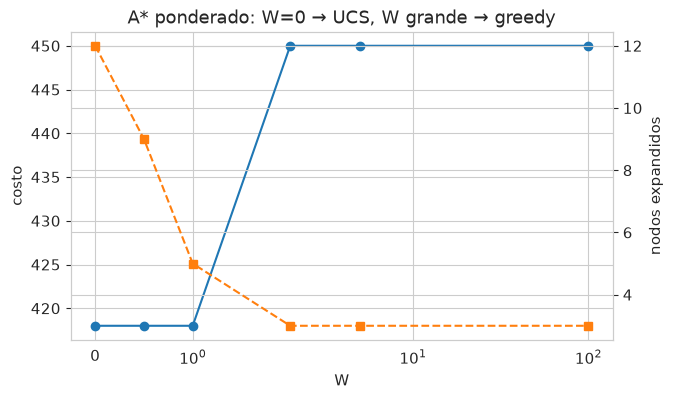

[(0, 418.0, 12), (0.5, 418.0, 9), (1, 418.0, 5), (2, 450.0, 3), (5, 450.0, 3), (100, 450.0, 3)]
origen, costo A* con h inadmisible, costo óptimo, (solo los casos subóptimos):
[('Arad', 450.0, 418.0), ('Zerind', 525.0, 493.0), ('Sibiu', 310.0, 278.0), ('Timisoara', 615.0, 536.0), ('Oradea', 461.0, 429.0)]


In [10]:
for src in ("Oradea", "Timisoara"):                                                         # 4-1
    t_ = run_all(RouteProblem(src, "Bucharest"), include=("UCS", "A*"))
    print(src, "→ expandidos UCS vs A*:", t_["expandidos"].to_dict(), "| costos:", t_["costo"].to_dict())
ws = [0, 0.5, 1, 2, 5, 100]                                                                  # 4-2
rows = [(w, astar_search(route, W=w).cost, len(astar_search(route, W=w).expanded)) for w in ws]
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(ws, [r[1] for r in rows], "o-", label="costo (km)"); ax.set(xscale="symlog", xlabel="W", ylabel="costo")
ax2 = ax.twinx(); ax2.plot(ws, [r[2] for r in rows], "s--", color="C1", label="expandidos"); ax2.set_ylabel("nodos expandidos")
ax.set_title("A* ponderado: W=0 → UCS, W grande → greedy"); ax.grid(True); plt.show(); print(rows)
class OverRoute(RouteProblem):                                                               # 4-3
    def h(self, node): return 2 * super().h(node)
bad = [(s, astar_search(OverRoute(s, "Bucharest")).cost, uniform_cost_search(RouteProblem(s, "Bucharest")).cost) for s in ROMANIA]
print("origen, costo A* con h inadmisible, costo óptimo, (solo los casos subóptimos):")
print([b for b in bad if b[1] > b[2] + 1e-9] or "ninguno: con h=2·h_SLD no se rompió en ninguna ciudad (la violación es posible, no garantizada)")
# Teoría: con h inadmisible A* puede dejar de ser óptimo, pero no siempre sucede; solo la admisibilidad lo GARANTIZA.

### 📊 Resumen visual — Rumania
```
        ALGORITMO      f(n)        ¿ÓPTIMO PARA…            RUTA EN ARAD→BUCAREST     EXPANSIONES
        ─────────────────────────────────────────────────────────────────────────────────────────
        BFS            profund.    nº de pasos              450 km (3 pasos)          muchas
        UCS            g           km (costo)               418 km                    muchas
        Greedy         h           — (ninguno)              450 km                    pocas
        A*  (h adm.)   g + h       km (costo)               418 km                    pocas ✔
        IDS            profund.    nº de pasos              450 km (3 pasos)          repetidas, memoria mínima
        A* W=3         g + 3h      — (≤ 3× el óptimo)       ≥ 418 km                  muy pocas
```

## 5. Búsqueda en una grilla (laberinto)

El problema más visual para ver las diferencias entre algoritmos: un robot en una cuadrícula con obstáculos que debe ir de la esquina superior izquierda a la inferior derecha moviéndose en 4 direcciones. Aquí el estado es una tupla `(fila, columna)`, las acciones son los 4 movimientos que no chocan con un muro, y la heurística natural es la **distancia Manhattan** (admisible y consistente en una grilla de 4 vecinos con costos ≥ 1, porque es el costo exacto del problema relajado "sin muros").

Soportamos también **costos de terreno** (entrar a una celda de barro cuesta más): la usaremos en el Ejercicio 1.

In [11]:
class GridProblem(Problem):
    MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]                      # arriba, abajo, izquierda, derecha

    def __init__(self, grid, start, goal, costs=None):
        super().__init__(start, goal)
        self.grid = grid                                              # 1 = muro, 0 = libre
        self.costs = costs                                            # matriz de costo de ENTRAR a cada celda (None → todos 1)
        self.min_cost = 1.0 if costs is None else float(costs[grid == 0].min())

    def actions(self, s):
        r, c = s
        return [(dr, dc) for dr, dc in self.MOVES
                if 0 <= r + dr < self.grid.shape[0] and 0 <= c + dc < self.grid.shape[1] and self.grid[r + dr, c + dc] == 0]

    def result(self, s, a):            return (s[0] + a[0], s[1] + a[1])
    def action_cost(self, s, a, s2):   return 1.0 if self.costs is None else float(self.costs[s2])
    def h(self, node):                 # Manhattan × costo mínimo de celda: sigue siendo admisible con terrenos de distinto costo
        return self.min_cost * (abs(node.state[0] - self.goal[0]) + abs(node.state[1] - self.goal[1]))


def make_grid(n, p_wall, rng, max_tries=200):
    # Genera un laberinto aleatorio y exige que SEA RESOLUBLE (si no, un experimento comparativo no tiene sentido)
    for _ in range(max_tries):
        grid = (rng.random((n, n)) < p_wall).astype(int)
        grid[0, 0] = grid[-1, -1] = 0
        if breadth_first_search(GridProblem(grid, (0, 0), (n - 1, n - 1))).found:
            return grid
    raise RuntimeError("no se pudo generar un laberinto resoluble; baja p_wall")

grid = make_grid(30, 0.28, np.random.default_rng(3))
gp = GridProblem(grid, (0, 0), (29, 29))
print(f"Grilla {grid.shape}, {grid.mean():.0%} de muros. Resoluble: {breadth_first_search(gp).found}")

Grilla (30, 30), 29% de muros. Resoluble: True


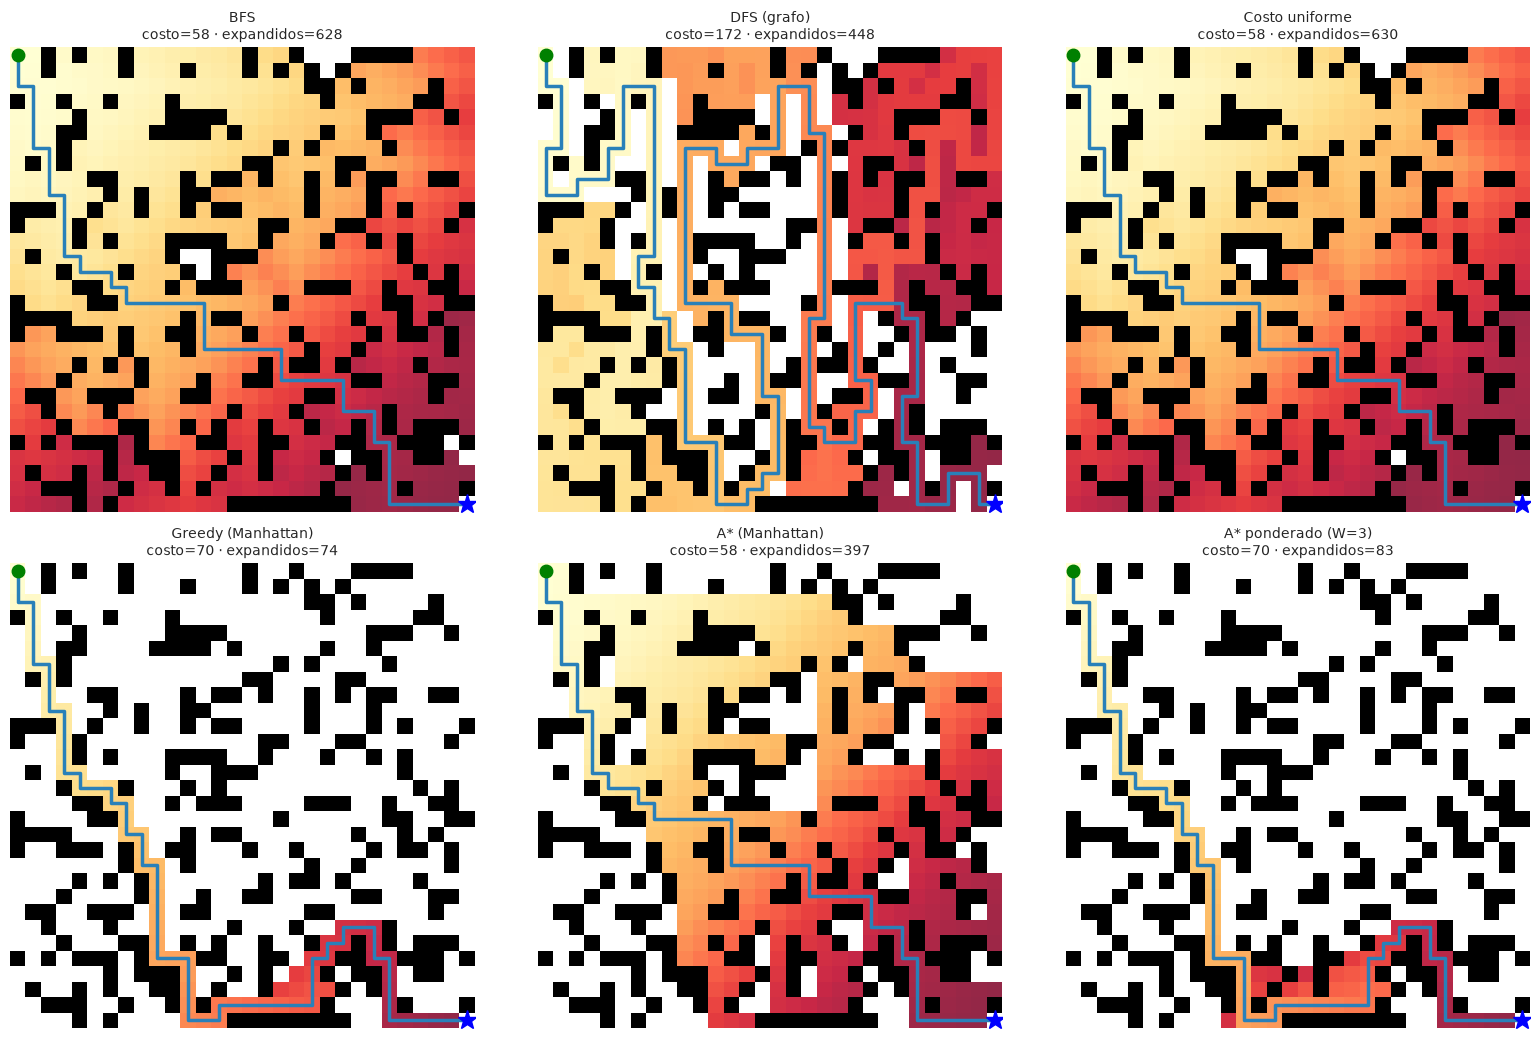

In [12]:
def draw_grid(ax, grid, res, title):
    img = np.full(grid.shape, np.nan)
    for i, s in enumerate(res.expanded):
        img[s] = i / max(len(res.expanded) - 1, 1)                    # color = orden de expansión (0 = primero, 1 = último)
    ax.imshow(np.where(grid == 1, 0.0, 1.0), cmap="gray", vmin=0, vmax=1)            # muros negros, libres blancos
    ax.imshow(img, cmap="YlOrRd", alpha=0.85, vmin=0, vmax=1)
    if res.found:
        path = np.array(res.node.path_states()); ax.plot(path[:, 1], path[:, 0], color="#2980b9", lw=2.5)
    ax.plot(0, 0, "go", ms=9); ax.plot(grid.shape[1] - 1, grid.shape[0] - 1, "b*", ms=14)
    ax.set_title(f"{title}\ncosto={res.cost:.0f} · expandidos={len(res.expanded)}", fontsize=10); ax.axis("off")

fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
runs = [("BFS", breadth_first_search(gp)), ("DFS (grafo)", depth_first_search(gp)), ("Costo uniforme", uniform_cost_search(gp)),
        ("Greedy (Manhattan)", greedy_search(gp)), ("A* (Manhattan)", astar_search(gp)), ("A* ponderado (W=3)", astar_search(gp, W=3))]
for ax, (name, r) in zip(axes.ravel(), runs):
    draw_grid(ax, grid, r, name)
plt.tight_layout(); plt.show()

**Qué deberías ver:** en cada panel, los muros en negro, las celdas **expandidas** coloreadas (amarillo = primeras, rojo = últimas) y la ruta final en azul.
- **BFS y UCS:** una **onda** que inunda casi todo el laberinto accesible (UCS = BFS cuando los costos son iguales).
- **DFS:** una exploración serpenteante y una ruta **larguísima**, nada óptima.
- **Greedy:** muy pocas celdas, directo a la meta, pero la ruta puede ser peor que la óptima.
- **A\*:** explora un **corredor** diagonal entre inicio y meta y encuentra la ruta **óptima** con bastantes menos celdas que BFS (≈ 1.6× menos en este laberinto; la ganancia depende de cuánto "engañen" los muros a la heurística, como verás en 🔧 5-1).
- **A\* ponderado:** intermedio entre A\* y *greedy*.

Cuantifiquemos lo que vemos:

In [13]:
table_grid = run_all(gp, include=("BFS", "DFS", "UCS", "Greedy", "A*"), optimal_cost=uniform_cost_search(gp).cost)
table_grid.loc["A* (W=3)"] = [astar_search(gp, 3).cost, astar_search(gp, 3).length, len(astar_search(gp, 3).expanded),
                              astar_search(gp, 3).generated, astar_search(gp, 3).max_frontier, round(astar_search(gp, 3).time_ms, 2),
                              astar_search(gp, 3).cost == table_grid.loc["UCS", "costo"]]
display(table_grid)
ratio = table_grid.loc["UCS", "expandidos"] / table_grid.loc["A*", "expandidos"]
print(f"A* expande {ratio:.1f}× menos nodos que UCS con exactamente el mismo costo óptimo ({table_grid.loc['A*', 'costo']:.0f}).")

,costo,pasos,expandidos,generados,frontera_máx,ms,óptimo
algoritmo,,,,,,,
BFS,58.0,58,628,631,27,1.98,True
DFS,172.0,172,448,568,135,1.73,False
UCS,58.0,58,630,631,27,3.91,True
Greedy,70.0,70,74,125,51,0.41,False
A*,58.0,58,397,474,78,2.88,True
A* (W=3),70.0,70,83,130,47,1.06,False


A* expande 1.6× menos nodos que UCS con exactamente el mismo costo óptimo (58).


### ⚠️ Troubleshooting

**Síntoma:** A\* devuelve una ruta **más cara** que UCS en tu problema.
**Por qué:** tu heurística **sobreestima** (no es admisible). Es el error más común al diseñar $h$: por ejemplo, usar Manhattan en una grilla que permite **diagonales**, o multiplicar por un factor "para que sea más agresiva".
**Solución:** verifica $h(n)\le h^*(n)$ comparando con UCS en instancias pequeñas, o usa la versión relajada del problema para derivar $h$.

**Síntoma:** BFS se queda sin memoria en tu problema real.
**Por qué:** su memoria crece como $O(b^d)$; con $b=4$ y $d=25$ son $\approx10^{15}$ nodos si no hubiera `reached`.
**Solución:** cambia a IDS (memoria lineal), A\* con una buena heurística, o **IDA\***/**SMA\*** (AIMA 3.5.5) si A\* se queda sin memoria.

### 🔧 Pruébalo tú mismo

### 🔧 Pruébalo tú mismo

**5-1. Densidad de muros:** repite el experimento con `p_wall ∈ {0.15, 0.25, 0.35, 0.40}` (laberintos resolubles) y grafica los nodos expandidos de BFS y A\* vs densidad. ¿Qué pasa con la ventaja de A\* cuando casi no hay muros? ¿Y cuando hay muchos?

**5-2. Otra heurística:** compara A\* con la distancia **euclídea** y con Manhattan en una grilla de 4 vecinos. ¿Ambas son admisibles? ¿Cuál domina? Mide los expandidos.

**5-3. Diagonales:** permite movimientos en 8 direcciones (costo 1 cada uno). Con Manhattan, ¿A\* sigue siendo óptimo? Pruébalo contra UCS. ¿Qué heurística correcta usarías (distancia de Chebyshev)?

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 5-1, 5-2 y 5-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

In [14]:
rows = []                                                                                    # 5-1
for p in (0.15, 0.25, 0.35, 0.40):
    g_ = make_grid(30, p, np.random.default_rng(7)); pr = GridProblem(g_, (0, 0), (29, 29))
    rows.append((p, len(breadth_first_search(pr).expanded), len(astar_search(pr).expanded)))
print(pd.DataFrame(rows, columns=["p_muro", "BFS", "A*"]).set_index("p_muro"))
print("Con pocos muros hay muchísimos caminos óptimos empatados (todas las celdas del rectángulo inicio-meta tienen f = g + h = C*): A* debe expandirlas casi todas.")
print("Con más muros hay menos empates y la heurística discrimina mejor, pero a la vez BFS también explora menos porque el laberinto accesible se reduce.")
class GridEuclid(GridProblem):                                                               # 5-2
    def h(self, node): return math.hypot(node.state[0] - self.goal[0], node.state[1] - self.goal[1])
print("expandidos A* Manhattan:", len(astar_search(gp).expanded), "| A* euclídea:", len(astar_search(GridEuclid(grid, (0, 0), (29, 29))).expanded),
      "→ Manhattan domina (h_manh ≥ h_eucl) y expande menos")
class GridDiag(GridProblem):                                                                 # 5-3
    MOVES = GridProblem.MOVES + [(-1, -1), (-1, 1), (1, -1), (1, 1)]
class GridDiagCheb(GridDiag):
    def h(self, node): return max(abs(node.state[0] - self.goal[0]), abs(node.state[1] - self.goal[1]))
d_man, d_che, d_ucs = GridDiag(grid, (0, 0), (29, 29)), GridDiagCheb(grid, (0, 0), (29, 29)), None
print(f"costo UCS={uniform_cost_search(d_man).cost:.0f} | A* Manhattan={astar_search(d_man).cost:.0f} (¿inadmisible?) | A* Chebyshev={astar_search(d_che).cost:.0f}")

        BFS   A*
p_muro          
0.15    759  622
0.25    654  383
0.35    541  223
0.40    350  196
Con pocos muros hay muchísimos caminos óptimos empatados (todas las celdas del rectángulo inicio-meta tienen f = g + h = C*): A* debe expandirlas casi todas.
Con más muros hay menos empates y la heurística discrimina mejor, pero a la vez BFS también explora menos porque el laberinto accesible se reduce.
expandidos A* Manhattan: 397 | A* euclídea: 521 → Manhattan domina (h_manh ≥ h_eucl) y expande menos
costo UCS=34 | A* Manhattan=36 (¿inadmisible?) | A* Chebyshev=34


### 📊 Resumen visual — grilla
```
  ¿CASI SIN MUROS?                     ¿CON MUCHOS MUROS?                 ¿HEURÍSTICA INADMISIBLE?
  Hay MUCHOS caminos óptimos           Los muros reducen los caminos      puede dejar de ser óptimo
  empatados (f = C*): A* expande       óptimos y h discrimina mejor       Manhattan con diagonales → usar Chebyshev
  casi todo el rectángulo inicio-meta  (en nuestros datos A* ganó más)
```

## 6. El 8-puzzle: heurísticas y factor de ramificación efectivo

Es el banco de pruebas clásico de heurísticas: un tablero 3×3 con 8 fichas y un hueco; se mueve una ficha al hueco por vez hasta ordenar el tablero. Tiene un espacio de estados **pequeño pero no trivial**: 181 440 estados alcanzables (la mitad de los 9! = 362 880, porque la paridad de las permutaciones separa el espacio en dos mitades **desconectadas**). Esto nos permite hacer algo poderoso: calcular **por fuerza bruta** la distancia óptima real de *todos* los estados a la meta, y así verificar nuestras heurísticas **exhaustivamente** (no solo en ejemplos).

Estado = tupla de 9 enteros (0 = hueco), leída por filas.

In [15]:
GOAL8 = (1, 2, 3, 4, 5, 6, 7, 8, 0)
GOAL_POS = {t: divmod(i, 3) for i, t in enumerate(GOAL8)}               # posición (fila, col) de cada ficha en la meta

def h_misplaced(state):                                                  # h1: fichas fuera de lugar (relajación: las fichas "saltan")
    return sum(1 for i, t in enumerate(state) if t and t != GOAL8[i])

def h_manhattan(state):                                                  # h2: distancia Manhattan (relajación: pueden pasar sobre otras)
    return sum(abs(i // 3 - GOAL_POS[t][0]) + abs(i % 3 - GOAL_POS[t][1]) for i, t in enumerate(state) if t)

class EightPuzzle(Problem):
    DELTAS = {"Arriba": -3, "Abajo": 3, "Izquierda": -1, "Derecha": 1}   # movimiento del HUECO

    def __init__(self, initial, heuristic=h_manhattan):
        super().__init__(tuple(initial), GOAL8); self._h = heuristic

    def actions(self, s):
        i = s.index(0); r, c = divmod(i, 3); acts = []
        if r > 0: acts.append("Arriba")
        if r < 2: acts.append("Abajo")
        if c > 0: acts.append("Izquierda")
        if c < 2: acts.append("Derecha")
        return acts

    def result(self, s, a):
        i = s.index(0); j = i + self.DELTAS[a]; l = list(s)
        l[i], l[j] = l[j], l[i]
        return tuple(l)                                                   # tupla: hasheable

    def h(self, node):  return self._h(node.state)

def is_solvable(state):                                                  # criterio de paridad: nº de inversiones par (tablero 3x3)
    seq = [t for t in state if t]
    inv = sum(1 for i in range(8) for j in range(i + 1, 8) if seq[i] > seq[j])
    return inv % 2 == 0

example = (8, 1, 3, 4, 0, 2, 7, 6, 5)
print("¿resoluble?", is_solvable(example), "| h1 =", h_misplaced(example), "| h2 =", h_manhattan(example))
sol = astar_search(EightPuzzle(example))
print(f"A* (Manhattan): {sol.length} movimientos, {len(sol.expanded)} expandidos → {sol.node.path_actions()}")

¿resoluble? True | h1 = 5 | h2 = 10
A* (Manhattan): 14 movimientos, 76 expandidos → ['Derecha', 'Abajo', 'Izquierda', 'Izquierda', 'Arriba', 'Arriba', 'Derecha', 'Abajo', 'Izquierda', 'Abajo', 'Derecha', 'Arriba', 'Derecha', 'Abajo']


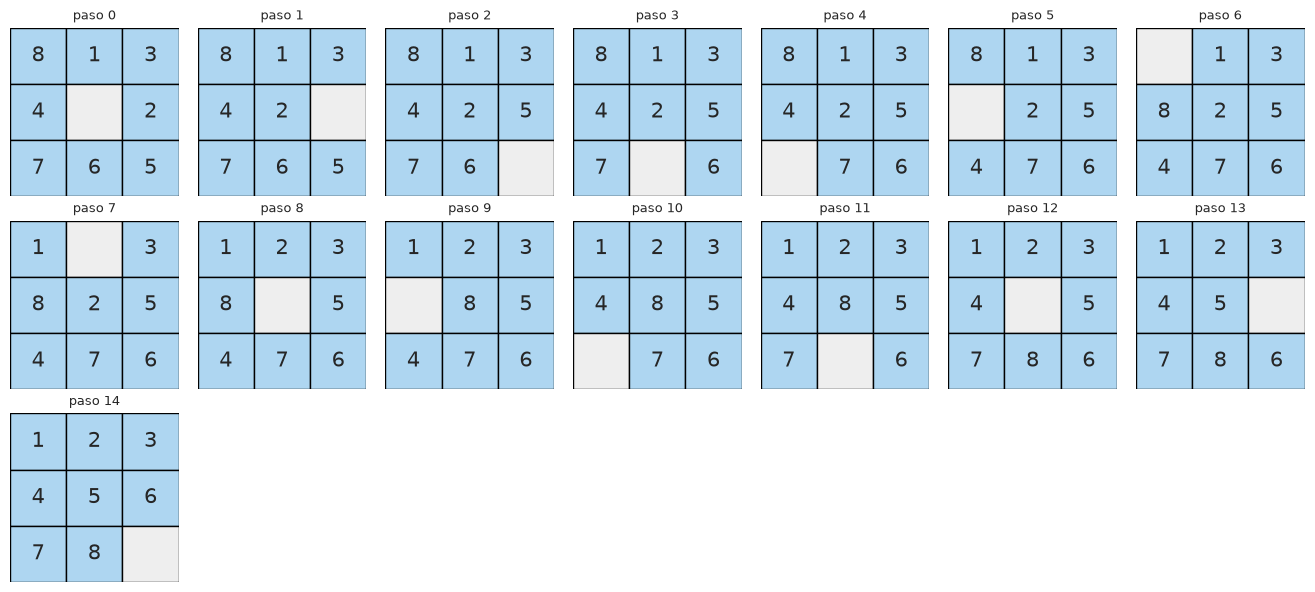

In [16]:
def show_boards(states, titles=None, ncols=7):
    n = len(states); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.9 * ncols, 2.0 * nrows)); axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, s, i in zip(axes, states, range(n)):
        for k, t in enumerate(s):
            r, c = divmod(k, 3)
            ax.add_patch(plt.Rectangle((c, 2 - r), 1, 1, facecolor="#eeeeee" if t == 0 else "#aed6f1", edgecolor="k"))
            if t: ax.text(c + .5, 2 - r + .5, str(t), ha="center", va="center", fontsize=15)
        ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.set_aspect("equal")
        ax.set_title(titles[i] if titles else f"paso {i}", fontsize=9)
    plt.tight_layout(); plt.show()

show_boards(sol.node.path_states())

**Qué deberías ver:** la secuencia de tableros de la solución óptima, desde el estado inicial (izquierda) hasta el tablero ordenado `1 2 3 / 4 5 6 / 7 8 _` (derecha), con el hueco (gris) moviéndose paso a paso.

### 6.1 Todo el espacio de estados por BFS inverso
Como los movimientos son **reversibles**, una BFS que parte de la **meta** nos da la distancia óptima $h^*(s)$ desde *cualquier* estado. Con esto podemos (a) comprobar que $h_1$ y $h_2$ son admisibles en los 181 440 estados, (b) comprobar la **dominancia** y la **consistencia**, y (c) fabricar instancias con una profundidad óptima **exacta**.

181,440 estados alcanzables | diámetro (peor caso) = 31 movimientos | 0.4 s


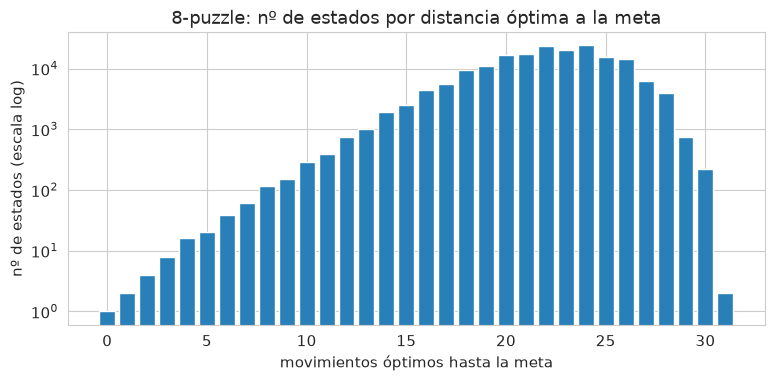

In [17]:
def all_distances(goal=GOAL8):
    dist = {goal: 0}; queue = deque([goal]); p = EightPuzzle(goal)
    while queue:
        s = queue.popleft()
        for a in p.actions(s):
            s2 = p.result(s, a)
            if s2 not in dist:
                dist[s2] = dist[s] + 1; queue.append(s2)
    return dist

t0 = time.perf_counter()
H_STAR = all_distances()
print(f"{len(H_STAR):,} estados alcanzables | diámetro (peor caso) = {max(H_STAR.values())} movimientos | {time.perf_counter() - t0:.1f} s")
depth_counts = pd.Series(H_STAR).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(depth_counts.index, depth_counts.values, color="#2980b9"); ax.set_yscale("log")
ax.set(title="8-puzzle: nº de estados por distancia óptima a la meta", xlabel="movimientos óptimos hasta la meta", ylabel="nº de estados (escala log)"); ax.grid(True, axis="y")
plt.show()

**Qué deberías ver:** 181 440 estados y un **diámetro de 31**: ningún tablero resoluble necesita más de 31 movimientos. El histograma crece rápido hasta un máximo alrededor de 22–24 movimientos y luego cae abruptamente (solo 2 estados necesitan los 31 movimientos). Ese crecimiento (casi exponencial al principio) es el factor de ramificación en acción.

Ahora la verificación **exhaustiva** de la teoría de heurísticas:

In [18]:
states = list(H_STAR)
h1_all = np.array([h_misplaced(s) for s in states]); h2_all = np.array([h_manhattan(s) for s in states]); hstar = np.array([H_STAR[s] for s in states])

print("¿h1 admisible en los 181.440 estados? ", bool(np.all(h1_all <= hstar)))
print("¿h2 admisible en los 181.440 estados? ", bool(np.all(h2_all <= hstar)))
print("¿h2 domina a h1 (h2 ≥ h1 siempre)?     ", bool(np.all(h2_all >= h1_all)))

p0 = EightPuzzle(GOAL8)
def consistent(hfun):                          # h(s) ≤ 1 + h(s') para toda arista (costo de acción = 1)
    return all(hfun(s) <= 1 + hfun(p0.result(s, a)) for s in states for a in p0.actions(s))
print("¿h1 consistente? ", consistent(h_misplaced), "| ¿h2 consistente? ", consistent(h_manhattan))
print(f"Promedio de h*: {hstar.mean():.2f} | promedio h1: {h1_all.mean():.2f} | promedio h2: {h2_all.mean():.2f}  (cuanto más cerca de h*, mejor guía)")

¿h1 admisible en los 181.440 estados?  True
¿h2 admisible en los 181.440 estados?  True
¿h2 domina a h1 (h2 ≥ h1 siempre)?      True
¿h1 consistente?  True | ¿h2 consistente?  True
Promedio de h*: 21.97 | promedio h1: 7.11 | promedio h2: 14.00  (cuanto más cerca de h*, mejor guía)


**Qué deberías ver:** cuatro `True` y que $h_2$ (Manhattan) está **mucho más cerca de $h^*$** en promedio que $h_1$. Es la demostración numérica de que ambas son admisibles y consistentes, y de que $h_2$ domina a $h_1$. Que sea **más cercana a $h^*$ sin sobrepasarla** es exactamente lo que hace buena a una heurística.

### 6.2 El factor de ramificación efectivo $b^*$
Para comparar algoritmos con *un solo número* independiente del tamaño del problema, AIMA define $b^*$ resolviendo $N+1=1+b^*+(b^*)^2+\dots+(b^*)^d$, donde $N$ es el total de nodos generados y $d$ la profundidad de la solución. Una búsqueda ciega tiene un $b^*$ cercano al factor de ramificación real; una buena heurística lo acerca a **1**. Lo calculamos por bisección (con `brentq`):

In [19]:
def effective_branching_factor(n_generated, depth):
    if depth == 0 or n_generated <= depth:
        return 1.0
    f = lambda b: (b ** (depth + 1) - 1) / (b - 1) - (n_generated + 1)     # 1 + b + ... + b^d = N + 1
    return brentq(f, 1.0 + 1e-9, 50.0)

# Ejemplo de AIMA: A* halla una solución a profundidad 5 generando 52 nodos → b* ≈ 1.92
print(f"b*(N=52, d=5) = {effective_branching_factor(52, 5):.2f}  (AIMA: 1.92)")

by_depth = defaultdict(list)
for s, d_ in H_STAR.items():
    by_depth[d_].append(s)
def sample_instances(depth, k, seed):                                       # instancias con profundidad óptima EXACTA
    r = np.random.default_rng(seed); idx = r.choice(len(by_depth[depth]), size=min(k, len(by_depth[depth])), replace=False)
    return [by_depth[depth][i] for i in idx]

b*(N=52, d=5) = 1.92  (AIMA: 1.92)


Ahora el experimento principal: para cada profundidad óptima $d$ tomamos 15 instancias y comparamos **A\* con $h=0$** (equivale a UCS: sin información), con $h_1$ y con $h_2$. Medimos nodos generados y $b^*$.

In [20]:
rows = []
for d_ in (4, 8, 12, 14, 16, 18, 20):
    inst = sample_instances(d_, 15, seed=d_)
    for name, hf in [("h=0 (UCS)", lambda s: 0), ("h1 (fuera de lugar)", h_misplaced), ("h2 (Manhattan)", h_manhattan)]:
        if name == "h=0 (UCS)" and d_ > 16:
            continue                                                         # sin heurística a d≥18 es muy lento: ya está claro el patrón
        gens = [astar_search(EightPuzzle(s, hf)).generated for s in inst]
        rows.append({"d": d_, "heurística": name, "generados": np.mean(gens), "b*": np.mean([effective_branching_factor(g, d_) for g in gens])})
exp8 = pd.DataFrame(rows)
display(exp8.pivot(index="d", columns="heurística", values="generados").round(0))
display(exp8.pivot(index="d", columns="heurística", values="b*").round(2))

heurística,h1 (fuera de lugar),h2 (Manhattan),h=0 (UCS)
d,,,
4,10.0,10.0,43.0
8,32.0,22.0,351.0
12,160.0,52.0,2486.0
14,417.0,133.0,6425.0
16,915.0,203.0,14771.0
18,2230.0,386.0,NaN
20,5332.0,725.0,NaN


heurística,h1 (fuera de lugar),h2 (Manhattan),h=0 (UCS)
d,,,
4,1.39,1.39,2.22
8,1.30,1.21,1.89
12,1.37,1.20,1.79
14,1.41,1.26,1.76
16,1.42,1.26,1.73
18,1.44,1.27,NaN
20,1.45,1.28,NaN


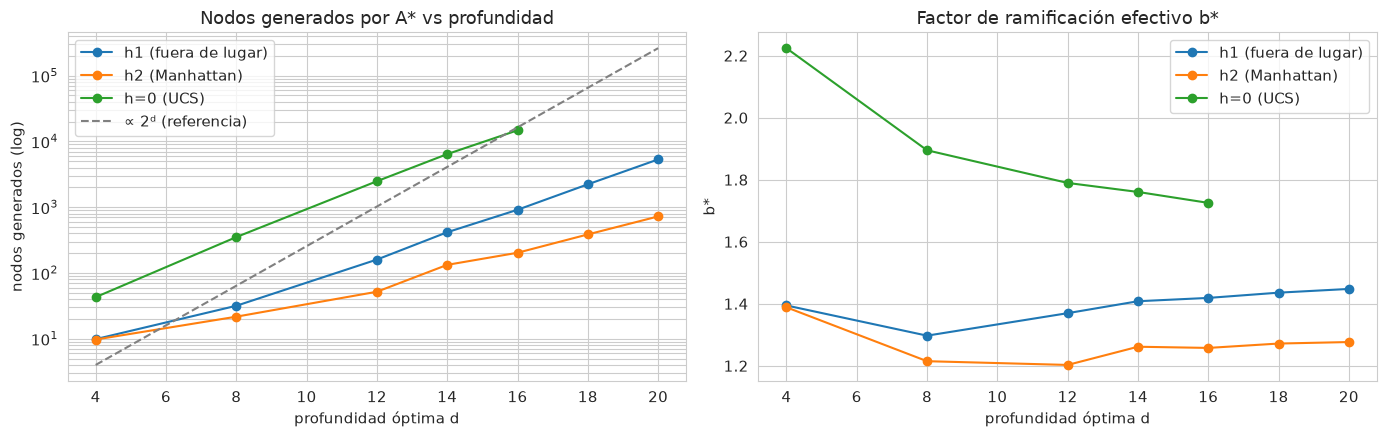

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, g in exp8.groupby("heurística"):
    axes[0].semilogy(g["d"], g["generados"], "o-", label=name); axes[1].plot(g["d"], g["b*"], "o-", label=name)
dd = np.arange(4, 21); axes[0].semilogy(dd, 2.0 ** dd / 4, "--", color="gray", label="∝ 2ᵈ (referencia)")
axes[0].set(title="Nodos generados por A* vs profundidad", xlabel="profundidad óptima d", ylabel="nodos generados (log)")
axes[1].set(title="Factor de ramificación efectivo b*", xlabel="profundidad óptima d", ylabel="b*")
for ax in axes: ax.grid(True, which="both"); ax.legend()
plt.tight_layout(); plt.show()

**Qué deberías ver:**
- Sin heurística (UCS) los nodos generados crecen **exponencialmente** con $d$ ($b^*\approx1.7$–$2$); con $h_1$ crece más despacio; con $h_2$ muchísimo más despacio. Con $d=16$, la diferencia entre $h=0$ y $h_2$ es de **uno o dos órdenes de magnitud**.
- $b^*$ baja de ≈ 1.8 (sin información) hacia ≈ 1.2–1.3 (con Manhattan): **una mejor heurística = menor factor de ramificación efectivo**. Es el resultado cuantitativo de la dominancia.
- Lo que **no** cambia: el costo de la solución. Las tres versiones son óptimas porque las tres $h$ son admisibles (y consistentes).

> **NOTA (el compromiso real):** una heurística más precisa suele costar más de **calcular** por nodo. Manhattan es barata. Heurísticas muy potentes como las **bases de datos de patrones** (*pattern databases*, precalculan el costo exacto de subproblemas) resuelven instancias del 15-puzzle y del cubo de Rubik que son imposibles con Manhattan, a cambio de memoria y precomputación. El mejor $h$ es el que minimiza el *tiempo total*, no solo el número de nodos.

### 6.3 Comparación de algoritmos en el 8-puzzle
Corremos todos sobre las mismas 10 instancias de profundidad 12:

In [22]:
inst12 = sample_instances(12, 10, seed=99)
algos8 = {
    "BFS": lambda s: breadth_first_search(EightPuzzle(s)),
    "IDS": lambda s: iterative_deepening_search(EightPuzzle(s)),
    "UCS (h=0)": lambda s: uniform_cost_search(EightPuzzle(s)),
    "A* (h1)": lambda s: astar_search(EightPuzzle(s, h_misplaced)),
    "A* (h2)": lambda s: astar_search(EightPuzzle(s, h_manhattan)),
    "A* ponderado (h2, W=2)": lambda s: astar_search(EightPuzzle(s, h_manhattan), W=2),
    "Greedy (h2)": lambda s: greedy_search(EightPuzzle(s, h_manhattan)),
}
rows = []
for name, fn in algos8.items():
    rs = [fn(s) for s in inst12]
    rows.append({"algoritmo": name, "longitud media": np.mean([r.length for r in rs]), "% óptimo": np.mean([r.length == 12 for r in rs]) * 100,
                 "expandidos": np.mean([len(r.expanded) for r in rs]), "frontera máx.": np.mean([r.max_frontier for r in rs]), "ms": np.mean([r.time_ms for r in rs])})
display(pd.DataFrame(rows).set_index("algoritmo").round(1))

,longitud media,% óptimo,expandidos,frontera máx.,ms
algoritmo,,,,,
BFS,12.0,100.0,1060.2,682.3,5.3
IDS,12.0,100.0,3279.1,12.4,17.2
UCS (h=0),12.0,100.0,1742.4,1026.7,14.7
A* (h1),12.0,100.0,107.5,74.8,0.5
A* (h2),12.0,100.0,42.2,31.8,0.2
"A* ponderado (h2, W=2)",12.0,100.0,37.6,30.8,0.2
Greedy (h2),25.0,20.0,171.6,115.1,0.9


**Qué deberías ver (lectura de la tabla):**
- **BFS, UCS, A\*(h1), A\*(h2), IDS** dan siempre longitud 12 (**100 % óptimo**). **Greedy** da soluciones de longitud ≈ 25, **el doble de largas**, y solo el 20 % son óptimas. **A\* ponderado (W=2)** salió 100 % óptimo en estas 10 instancias, pero eso es suerte: solo está *garantizado* a ≤ 2× el óptimo.
- **Expandidos:** BFS (≈1 060) y UCS (≈1 740) ≫ A\*(h1) (≈110) > A\*(h2) (≈40). Sorpresa instructiva: *greedy* con Manhattan expande **más** (≈170) que A\*(h2) y encima da peor solución: aquí es peor en todo, porque sin $g(n)$ se deja arrastrar por callejones.
- **Memoria (frontera máx.):** BFS y UCS guardan cientos a mil nodos; **IDS** guarda apenas ~12 (solo el camino actual y sus hermanos), a cambio de re-expandir los nodos superficiales (≈3× más expansiones que BFS). Ese es el trueque tiempo ↔ memoria que resume la Fig. 3.15 de AIMA.
- Como la mayor parte de los nodos de un árbol están en el **último nivel**, el sobrecosto de IDS es modesto: repite los niveles anteriores, que son una fracción pequeña del total.

### ⚠️ Troubleshooting

**Síntoma:** tu búsqueda sobre un 8-puzzle **nunca termina** (o recorre 181 440 estados y falla).
**Por qué:** el estado inicial **no es resoluble** (paridad impar de inversiones): pertenece a la otra mitad del espacio, desconectada de la meta.
**Solución:** comprueba `is_solvable(estado)` antes de buscar. Lo verificamos aquí:

In [23]:
unsolvable = (1, 2, 3, 4, 5, 6, 8, 7, 0)                    # solo se intercambian dos fichas respecto de la meta → paridad impar
print("¿resoluble?", is_solvable(unsolvable), "| ¿está en el espacio alcanzable desde la meta?", unsolvable in H_STAR)
t0 = time.perf_counter(); r = breadth_first_search(EightPuzzle(unsolvable))
print(f"BFS: encontrada={r.found} tras expandir {len(r.expanded):,} estados ({(time.perf_counter() - t0):.1f} s) → agotó la mitad del espacio, sin solución")

¿resoluble? False | ¿está en el espacio alcanzable desde la meta? False
BFS: encontrada=False tras expandir 181,440 estados (0.7 s) → agotó la mitad del espacio, sin solución


### 🔧 Pruébalo tú mismo

**6-1. Una heurística más:** define `h3 = max(h1, h2)`. ¿Es admisible? ¿Es consistente? ¿Domina a $h_2$? Compruébalo sobre los 181 440 estados y explica por qué `max` de admisibles es admisible.

**6-2. Linear conflict:** si dos fichas están en su fila correcta pero en orden invertido, hacen falta **al menos 2 movimientos extra** (una debe salir de la fila). Implementa `h4 = Manhattan + 2·(nº de pares en conflicto por fila)` (ignora columnas) y verifica que sigue siendo admisible exhaustivamente. ¿Cuántos nodos menos expande que Manhattan?

**6-3. Escalar:** ¿qué pasaría con IDS a profundidad 20? Estima cuántos nodos generaría (usa $b^*\approx 1.8$) y compara con A\*(h2) usando los datos de la tabla.

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 6-1, 6-2 y 6-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

In [24]:
h3_all = np.maximum(h1_all, h2_all)                                                          # 6-1
print("h3 admisible:", bool(np.all(h3_all <= hstar)), "| h3 == h2 en todo el espacio:", bool(np.all(h3_all == h2_all)),
      "→ max(h1,h2)=h2 porque h2 ≥ h1; el máximo de admisibles es admisible (si cada una ≤ h*, su máximo también)")
def h_lc(state):                                                                             # 6-2
    extra = 0
    for r in range(3):
        row = [(t, GOAL_POS[t][1]) for t in state[3 * r:3 * r + 3] if t and GOAL_POS[t][0] == r]   # fichas en su fila objetivo
        extra += 2 * sum(1 for i in range(len(row)) for j in range(i + 1, len(row)) if row[i][1] > row[j][1])
    return h_manhattan(state) + extra
h4_all = np.array([h_lc(s) for s in states])
print("h4 admisible:", bool(np.all(h4_all <= hstar)), "| h4 > h2 en", f"{(h4_all > h2_all).mean():.1%}", "de los estados")
inst = sample_instances(16, 15, seed=5)
print("expandidos A*: h2 =", np.mean([len(astar_search(EightPuzzle(s, h_manhattan)).expanded) for s in inst]),
      "| h4 =", np.mean([len(astar_search(EightPuzzle(s, h_lc)).expanded) for s in inst]))
print("IDS a d=20 ≈ 1.8^20 =", f"{1.8**20:,.0f} nodos (sumando iteraciones, el orden de magnitud es el mismo) vs A*(h2) del experimento (~miles)")   # 6-3

h3 admisible: True | h3 == h2 en todo el espacio: True → max(h1,h2)=h2 porque h2 ≥ h1; el máximo de admisibles es admisible (si cada una ≤ h*, su máximo también)
h4 admisible: True | h4 > h2 en 24.0% de los estados
expandidos A*: h2 = 119.26666666666667 | h4 = 92.93333333333334
IDS a d=20 ≈ 1.8^20 = 127,482 nodos (sumando iteraciones, el orden de magnitud es el mismo) vs A*(h2) del experimento (~miles)


### 📊 Resumen visual — 8-puzzle
```
 h* (óptimo real)   ───────────────────────────────  ← lo ideal, pero inalcanzable de calcular en general
 h2 Manhattan       ────────────────────────────     ← relajación: fichas se deslizan sobre otras
 h1 fuera de lugar  ────────────────                 ← relajación: fichas saltan
 h = 0              ─                                 ← búsqueda ciega (UCS)
                    h más alta (y admisible) ⇒ menos nodos y b* más cercano a 1
```

## 7. Búsqueda local

Hasta ahora buscamos **caminos**. Pero en muchos problemas el camino no importa, solo el **estado final**: ¿cómo colocar 8 reinas sin que se ataquen? ¿qué orden de visita minimiza la distancia del viajante? ¿qué hiperparámetros dan el mejor modelo? La **búsqueda local** parte de un estado completo (a menudo aleatorio, y quizá inválido) y lo va **mejorando** mediante pequeños cambios, guardando solo el estado actual: memoria $O(1)$, y puede resolver problemas con espacios inmensos.

Necesita tres ingredientes: una **representación** del estado, una **función objetivo** (a maximizar o minimizar) y una definición de **vecinos**.

### 7.1 El paisaje de estados y los máximos locales
Antes de los algoritmos, veamos el problema fundamental con un ejemplo 1D donde puedes *ver* todo el paisaje: una función con varios picos, y un caminante que solo mira a sus vecinos inmediatos.

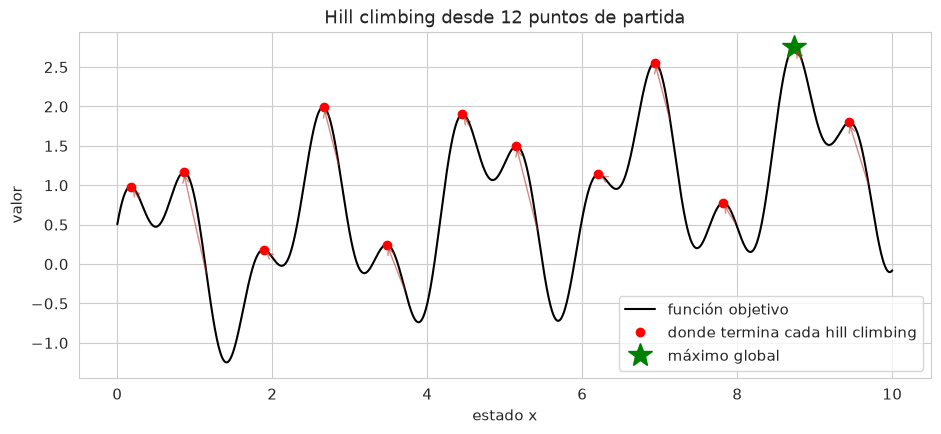

8% de las ejecuciones llegó al máximo global; el resto quedó atrapado en máximos locales.


In [25]:
def landscape(x):
    return np.sin(3 * x) + 0.6 * np.sin(7.3 * x + 1) + 0.15 * x          # varios máximos locales; el global está en la zona derecha

xs = np.linspace(0, 10, 2000); ys = landscape(xs)
x_best = xs[ys.argmax()]

def hill_climb_1d(x, step=0.02, lo=0, hi=10):
    while True:
        cand = [c for c in (x - step, x + step) if lo <= c <= hi]
        best = max(cand, key=landscape)
        if landscape(best) <= landscape(x):                               # ningún vecino mejora → pico (o meseta)
            return x
        x = best

starts = np.linspace(0.3, 9.7, 12)
ends = np.array([hill_climb_1d(s0) for s0 in starts])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(xs, ys, color="k", lw=1.5, label="función objetivo")
for s0, e0 in zip(starts, ends):
    ax.annotate("", xy=(e0, landscape(e0)), xytext=(s0, landscape(s0)), arrowprops=dict(arrowstyle="->", color="#c0392b", alpha=0.6))
ax.plot(ends, landscape(ends), "ro", label="donde termina cada hill climbing"); ax.plot(x_best, landscape(x_best), "g*", ms=18, label="máximo global")
ax.set(title="Hill climbing desde 12 puntos de partida", xlabel="estado x", ylabel="valor"); ax.grid(True); ax.legend(); plt.show()
print(f"{np.mean(np.abs(ends - x_best) < 0.1):.0%} de las ejecuciones llegó al máximo global; el resto quedó atrapado en máximos locales.")

**Qué deberías ver:** la función con varios picos y flechas rojas desde 12 puntos de partida; **cada flecha termina en el pico más cercano** (hacia arriba), no necesariamente en el mejor. Solo las ejecuciones que partieron en la "cuenca de atracción" del máximo global (estrella verde) lo alcanzan. Esa es **la** limitación de *hill climbing*, y todos los algoritmos siguientes son formas de mitigarla.

### 7.2 El problema de las N reinas con *hill climbing*
**Formulación:** una reina por columna; el estado es una tupla `s` donde `s[c]` es la fila de la reina en la columna `c`. Así nunca hay ataques por columna. El **costo** (a minimizar) es el número de **pares de reinas que se atacan** (misma fila o misma diagonal); costo 0 = solución. Los **vecinos** se obtienen moviendo **una** reina dentro de su columna: $n(n-1)=56$ vecinos para $n=8$.

Para que sea rápido, calculamos el costo de **muchos estados a la vez** con NumPy (broadcasting, como en NB-03).

In [26]:
def conflicts_batch(P):
    # P: (m, n) → nº de pares de reinas que se atacan, para cada fila de P (vectorizado por broadcasting)
    P = np.atleast_2d(P); n = P.shape[1]; cols = np.arange(n)
    same_row = P[:, :, None] == P[:, None, :]
    same_diag = np.abs(P[:, :, None] - P[:, None, :]) == np.abs(cols[:, None] - cols[None, :])
    upper = np.triu(np.ones((n, n), dtype=bool), 1)                      # cuenta cada par una sola vez
    return ((same_row | same_diag) & upper).sum(axis=(1, 2))

def neighbors_batch(s):
    n = len(s); moves = [(c, r) for c in range(n) for r in range(n) if r != s[c]]
    P = np.tile(np.asarray(s), (len(moves), 1))
    for k, (c, r) in enumerate(moves): P[k, c] = r
    return P

print("Una solución conocida:", conflicts_batch((0, 4, 7, 5, 2, 6, 1, 3))[0], "conflictos | estado aleatorio:", conflicts_batch(rng.integers(0, 8, 8))[0])
print("vecinos de un estado de 8 reinas:", neighbors_batch(tuple(range(8))).shape[0])

Una solución conocida: 0 conflictos | estado aleatorio: 9
vecinos de un estado de 8 reinas: 56


In [27]:
def hill_climbing_queens(n, rng, sideways=0, max_steps=1000, cost_fn=conflicts_batch):
    # Ascenso por la máxima pendiente (steepest-ascent). `sideways`: nº de movimientos laterales (a igual costo) permitidos en mesetas.
    # `cost_fn` permite cambiar la función objetivo (ver 🔧 7-3); debe valer 0 exactamente cuando el estado es solución
    s = rng.integers(0, n, n); cost = cost_fn(s)[0]; side = 0
    for step in range(max_steps):
        if cost == 0:
            return s, True, step
        nb_ = neighbors_batch(tuple(s)); costs = cost_fn(nb_)
        best = costs.min()
        if best > cost or (best == cost and side >= sideways):           # óptimo local (o meseta sin permiso) → atascado
            return s, False, step
        side = side + 1 if best == cost else 0
        s, cost = nb_[rng.choice(np.flatnonzero(costs == best))], best     # desempate aleatorio entre los mejores vecinos
    return s, False, max_steps

def success_stats(fn, runs, seed):
    r = np.random.default_rng(seed); out = [fn(r) for _ in range(runs)]
    ok = [o[2] for o in out if o[1]]; bad = [o[2] for o in out if not o[1]]
    return {"éxito": len(ok) / runs, "pasos (éxito)": np.mean(ok) if ok else np.nan, "pasos (fracaso)": np.mean(bad) if bad else np.nan}

res_q = pd.DataFrame({"hill climbing puro": success_stats(lambda r: hill_climbing_queens(8, r, 0), 1000, 1),
                      "con 100 mov. laterales": success_stats(lambda r: hill_climbing_queens(8, r, 100), 1000, 1)}).T
display(res_q.round(3))
print("AIMA 4.1.1 reporta ≈ 14 % de éxito (puro, ~4 pasos si resuelve, ~3 si se atasca) y ≈ 94 % con 100 laterales.")

,éxito,pasos (éxito),pasos (fracaso)
hill climbing puro,0.15,4.12,3.11
con 100 mov. laterales,0.94,18.87,64.00


AIMA 4.1.1 reporta ≈ 14 % de éxito (puro, ~4 pasos si resuelve, ~3 si se atasca) y ≈ 94 % con 100 laterales.


**Qué deberías ver:** *hill climbing* puro resuelve solo **≈ 14 %** de las instancias y se atasca en el resto en muy pocos pasos (3–4: el espacio de 8 reinas tiene muchos óptimos locales). Permitir hasta 100 **movimientos laterales** (cruzar mesetas) sube el éxito a **≈ 90–95 %**, a costa de más pasos. Estos números reproducen los que reporta AIMA, y son una buena demostración empírica de **por qué las mesetas importan**.

Una variante simplísima y muy potente: **reinicio aleatorio** (*random restart*). Si cada intento tiene probabilidad de éxito $p$, el número esperado de intentos es $1/p$, y como *hill climbing* es barato, "reintentar hasta que funcione" es **completo con probabilidad 1**:

In [28]:
def random_restart(n, rng, sideways=0):
    attempts, steps = 0, 0
    while True:
        attempts += 1; s, ok, st = hill_climbing_queens(n, rng, sideways); steps += st
        if ok:
            return s, attempts, steps

r_ = np.random.default_rng(5)
runs_rr = [random_restart(8, r_) for _ in range(200)]
p_est = res_q.loc["hill climbing puro", "éxito"]
print(f"Reinicio aleatorio (sin laterales): intentos medios = {np.mean([a for _, a, _ in runs_rr]):.1f}  (teoría 1/p ≈ {1 / p_est:.1f}) | pasos totales medios = {np.mean([s for *_, s in runs_rr]):.1f}")
print("Ejemplo de solución:", runs_rr[0][0], "→ conflictos =", conflicts_batch(runs_rr[0][0])[0])

Reinicio aleatorio (sin laterales): intentos medios = 7.0  (teoría 1/p ≈ 6.8) | pasos totales medios = 22.2
Ejemplo de solución: [6 4 2 0 5 7 1 3] → conflictos = 0


### 🔧 Pruébalo tú mismo

**7-1. Escalar N:** ejecuta *hill climbing* puro y con 100 laterales para `n = 4, 8, 12, 16`, 200 corridas cada uno. ¿Cómo cambia el % de éxito con `n`? ¿Por qué?

**7-2. Estudio de laterales:** para `n=8`, grafica el % de éxito vs el número de movimientos laterales permitidos `{0, 1, 5, 20, 100}`.

**7-3. Función objetivo alternativa:** en vez de contar pares en conflicto, cuenta **reinas en conflicto** (reinas que son atacadas por al menos otra). ¿Cambia el paisaje? Evalúa el éxito de *hill climbing* con este nuevo costo.

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 7-1, 7-2 y 7-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

,éxito (lat=0),éxito (lat=100)
n,,
4,0.42,1.00
8,0.15,0.92
12,0.04,0.94
16,0.03,0.96


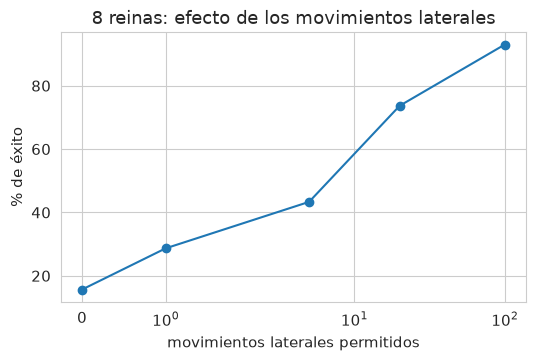

éxito con 'pares en conflicto' : {0: 0.13333333333333333, 100: 0.9433333333333334} 
éxito con 'reinas en conflicto': {0: 0.20333333333333334, 100: 0.9266666666666666}
Sin laterales el éxito cae con n (≈42 % en n=4 → ≈3 % en n=16), pero con 100 laterales se mantiene en ≈90–100 %: el obstáculo dominante son las MESETAS, no solo los óptimos locales.
Mismo problema, distinta función objetivo, distinto éxito: la función objetivo DEFINE el paisaje que recorre el algoritmo. Diseñarla bien es parte del trabajo.


In [29]:
rows = []                                                                                           # 7-1
for n_ in (4, 8, 12, 16):
    rows.append({"n": n_, **{f"éxito (lat={l})": success_stats(lambda r, n_=n_, l=l: hill_climbing_queens(n_, r, l), 200, n_)["éxito"] for l in (0, 100)}})
display(pd.DataFrame(rows).set_index("n"))
xs_l = [0, 1, 5, 20, 100]                                                                           # 7-2
ys_l = [success_stats(lambda r, l=l: hill_climbing_queens(8, r, l), 300, 2)["éxito"] for l in xs_l]
fig, ax = plt.subplots(figsize=(6, 3.5)); ax.plot(xs_l, np.array(ys_l) * 100, "o-"); ax.set(xscale="symlog", xlabel="movimientos laterales permitidos", ylabel="% de éxito", title="8 reinas: efecto de los movimientos laterales"); ax.grid(True); plt.show()
def queens_in_conflict(P):                                                                          # 7-3
    P = np.atleast_2d(P); n = P.shape[1]; cols = np.arange(n)
    att = (P[:, :, None] == P[:, None, :]) | (np.abs(P[:, :, None] - P[:, None, :]) == np.abs(cols[:, None] - cols[None, :]))
    att &= ~np.eye(n, dtype=bool); return att.any(axis=2).sum(axis=1)
alt = {l: success_stats(lambda r, l=l: hill_climbing_queens(8, r, l, cost_fn=queens_in_conflict), 300, 3)["éxito"] for l in (0, 100)}
base = {l: success_stats(lambda r, l=l: hill_climbing_queens(8, r, l), 300, 3)["éxito"] for l in (0, 100)}
print("éxito con 'pares en conflicto' :", base, "\néxito con 'reinas en conflicto':", alt)
print("Sin laterales el éxito cae con n (≈42 % en n=4 → ≈3 % en n=16), pero con 100 laterales se mantiene en ≈90–100 %: el obstáculo dominante son las MESETAS, no solo los óptimos locales.")
print("Mismo problema, distinta función objetivo, distinto éxito: la función objetivo DEFINE el paisaje que recorre el algoritmo. Diseñarla bien es parte del trabajo.")

### 7.3 *Simulated annealing* (recocido simulado)
**Por qué funciona (analogía metalúrgica):** al templar acero, lo calientas hasta que los átomos se mueven libremente y lo enfrías **lentamente**; si el enfriamiento es lento, los átomos encuentran una disposición de baja energía (cristal); si es brusco, quedan atrapados en una estructura imperfecta. *Simulated annealing* (SA) imita esto: acepta movimientos **que empeoran** con una probabilidad que depende de una "temperatura" $T$ que desciende con el tiempo.

**El algoritmo** (AIMA Fig. 4.5), minimizando un costo $E$:
1. Elige un vecino **aleatorio** del estado actual.
2. Si **mejora** ($\Delta E<0$), acéptalo siempre.
3. Si **empeora**, acéptalo con probabilidad $e^{-\Delta E/T}$ (regla de Metropolis).
4. Baja $T$ según un **calendario de enfriamiento** (*cooling schedule*) y repite.

$$P(\text{aceptar}\mid\Delta E>0)=e^{-\Delta E/T}\qquad T\to\infty:\;P\to1\;\text{(camina al azar)}\qquad T\to0:\;P\to0\;\text{(es hill climbing)}$$

Veamos ese comportamiento de $T$ en números antes de usarlo:

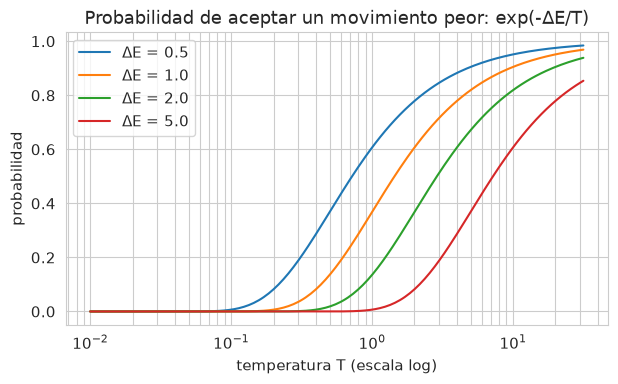

{'T=5': [0.905, 0.819, 0.67, 0.368], 'T=1': [0.607, 0.368, 0.135, 0.007], 'T=0.1': [0.007, 0.0, 0.0, 0.0]}


In [30]:
dE = np.array([0.5, 1, 2, 5])
fig, ax = plt.subplots(figsize=(7, 3.8))
T_grid = np.logspace(-2, 1.5, 200)
for d in dE:
    ax.semilogx(T_grid, np.exp(-d / T_grid), label=f"ΔE = {d}")
ax.set(title="Probabilidad de aceptar un movimiento peor: exp(-ΔE/T)", xlabel="temperatura T (escala log)", ylabel="probabilidad"); ax.grid(True, which="both"); ax.legend(); plt.show()
print({f"T={T}": [round(float(np.exp(-d / T)), 3) for d in dE] for T in (5, 1, 0.1)})

**Qué deberías ver:** curvas en forma de "S": con $T$ alta, casi cualquier empeoramiento se acepta (probabilidad → 1); con $T$ baja, casi ninguno; y para un mismo $T$, los empeoramientos **grandes** son mucho menos probables que los pequeños. Esa mezcla permite *escalar pequeñas colinas* al principio y **congelarse** hacia el final.

#### Aplicación: el problema del viajante (TSP)
Visitar $n$ ciudades exactamente una vez y volver al origen minimizando la distancia total. Con $n=30$ hay $29!/2\approx4\times10^{30}$ rutas: imposible por fuerza bruta. El estado es una **permutación**; el vecino clásico es el movimiento **2-opt**: elegir dos aristas, quitarlas y **invertir** el tramo entre ellas (elimina cruces). Para $n=30$ ciudades aleatorias en el cuadrado unitario compararemos: (a) el heurístico del **vecino más cercano**, (b) *hill climbing* con 2-opt (con reinicios) y (c) SA.

In [31]:
def make_cities(n, rng):
    pts = rng.random((n, 2)); return pts, cdist(pts, pts)              # matriz de distancias (ver NB-03: cdist/broadcasting)

def tour_length(t, D):
    return D[t, np.roll(t, -1)].sum()

def nearest_neighbor_tour(D, start=0):
    n = len(D); tour, left = [start], set(range(n)) - {start}
    while left:
        nxt = min(left, key=lambda j: D[tour[-1], j]); tour.append(nxt); left.remove(nxt)
    return np.array(tour)

def two_opt_delta(t, i, j, D):
    # Cambio en la longitud al invertir t[i..j]: solo cuentan las dos aristas que se cortan (cálculo O(1), no O(n))
    n = len(t); a, b, c, d = t[i - 1], t[i], t[j], t[(j + 1) % n]
    return D[a, c] + D[b, d] - D[a, b] - D[c, d]

pts, D = make_cities(30, np.random.default_rng(11))
t_nn = nearest_neighbor_tour(D)
print(f"Vecino más cercano: longitud = {tour_length(t_nn, D):.3f}")

Vecino más cercano: longitud = 5.542


In [32]:
def hill_climb_tsp(D, rng, start=None, max_stall=3000):
    n = len(D); t = rng.permutation(n) if start is None else start.copy(); stall = 0
    while stall < max_stall:                                             # primera mejora: acepta el primer 2-opt que acorta
        i, j = sorted(rng.choice(np.arange(1, n), 2, replace=False))
        if two_opt_delta(t, i, j, D) < -1e-12:
            t[i:j + 1] = t[i:j + 1][::-1]; stall = 0
        else:
            stall += 1
    return t

def simulated_annealing_tsp(D, rng, T0=1.0, T_end=1e-3, iters=60_000, start=None):
    n = len(D); t = rng.permutation(n) if start is None else start.copy()
    L = tour_length(t, D); best, best_L = t.copy(), L; trace = []
    for k in range(iters):
        T = T0 * (T_end / T0) ** (k / iters)                             # enfriamiento geométrico (exponencial)
        i, j = sorted(rng.choice(np.arange(1, n), 2, replace=False))
        dE = two_opt_delta(t, i, j, D)
        if dE < 0 or rng.random() < math.exp(-dE / T):                   # Metropolis: a veces aceptamos empeorar
            t[i:j + 1] = t[i:j + 1][::-1]; L += dE
            if L < best_L - 1e-12: best, best_L = t.copy(), L
        if k % 500 == 0: trace.append((k, T, L, best_L))
    return best, best_L, np.array(trace)

r_ = np.random.default_rng(1)
hc_runs = [tour_length(hill_climb_tsp(D, r_), D) for _ in range(20)]
t_sa, L_sa, trace = simulated_annealing_tsp(D, np.random.default_rng(2))
print(f"Hill climbing 2-opt (20 reinicios aleatorios): mejor = {min(hc_runs):.3f} | peor = {max(hc_runs):.3f} | media = {np.mean(hc_runs):.3f}")
print(f"Simulated annealing (1 corrida de 60.000 pasos): {L_sa:.3f}")

Hill climbing 2-opt (20 reinicios aleatorios): mejor = 4.698 | peor = 5.321 | media = 4.921
Simulated annealing (1 corrida de 60.000 pasos): 4.698


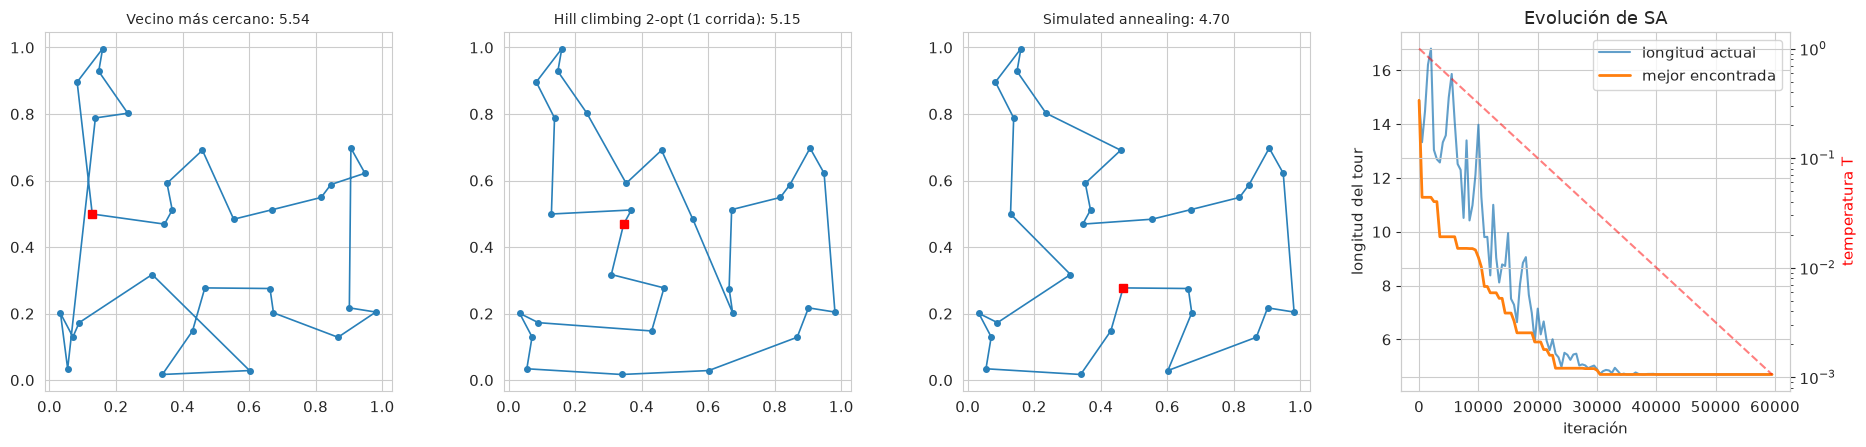

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
def draw_tour(ax, t, title):
    p = pts[np.r_[t, t[0]]]; ax.plot(p[:, 0], p[:, 1], "-o", color="#2980b9", ms=4, lw=1.2); ax.plot(*pts[t[0]], "rs"); ax.set_title(title, fontsize=10); ax.set_aspect("equal"); ax.grid(True)
draw_tour(axes[0], t_nn, f"Vecino más cercano: {tour_length(t_nn, D):.2f}")
draw_tour(axes[1], hill_climb_tsp(D, np.random.default_rng(1)), f"Hill climbing 2-opt (1 corrida): {tour_length(hill_climb_tsp(D, np.random.default_rng(1)), D):.2f}")
draw_tour(axes[2], t_sa, f"Simulated annealing: {L_sa:.2f}")
axes[3].plot(trace[:, 0], trace[:, 2], label="longitud actual", alpha=0.7); axes[3].plot(trace[:, 0], trace[:, 3], label="mejor encontrada", lw=2)
ax_t = axes[3].twinx(); ax_t.plot(trace[:, 0], trace[:, 1], "r--", alpha=0.5); ax_t.set_ylabel("temperatura T", color="r"); ax_t.set_yscale("log")
axes[3].set(title="Evolución de SA", xlabel="iteración", ylabel="longitud del tour"); axes[3].grid(True); axes[3].legend()
plt.tight_layout(); plt.show()

**Qué deberías ver:**
- **Vecino más cercano:** un tour decente pero con **cruces** y un salto largo al final (el heurístico "codicioso" deja para el final lo que dejó atrás).
- **Hill climbing 2-opt:** elimina los cruces, pero según el punto de partida queda en distintos **óptimos locales** (la dispersión entre la mejor y la peor de las 20 corridas lo muestra).
- **SA:** típicamente iguala o supera al **mejor** de los 20 reinicios con una sola corrida y es más **consistente**.
- **Panel derecho:** al inicio (T alta) la longitud *actual* **sube y baja** mucho (acepta empeorar y explora); al enfriarse, se estabiliza y converge; la "mejor encontrada" solo desciende. Es el calendario de enfriamiento en acción.

> **NOTA (el calendario importa):** con $T_0$ demasiado bajo, SA se comporta como *hill climbing* y se atasca; con enfriamiento demasiado rápido, "congela" un óptimo local; con demasiado lento, desperdicia tiempo. Para $n$ grande lo normal es empezar con $T_0\approx$ la diferencia típica de costo entre vecinos. Con enfriamiento logarítmico SA converge al óptimo global *en teoría* (con paciencia infinita); en práctica se usan calendarios geométricos como el de arriba.

### 🔧 Pruébalo tú mismo

### 🔧 Pruébalo tú mismo

**7-4. Calendarios:** ejecuta SA con `iters ∈ {1.000, 10.000, 100.000}` y `T0 ∈ {0.01, 0.1, 1, 10}` (20 semillas cada combinación). Haz un mapa de calor de la longitud media. ¿Cuándo SA es peor que *hill climbing*?

**7-5. Más ciudades:** repite con `n = 60` y `n = 100`. ¿Sigue ganando SA? ¿Cuánto tarda? Compara con el vecino más cercano.

**7-6. Partir de una buena solución:** inicia SA desde el tour del vecino más cercano con `T0` pequeño. ¿Mejora la solución final? ¿Y el tiempo?

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 7-4, 7-5 y 7-6
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

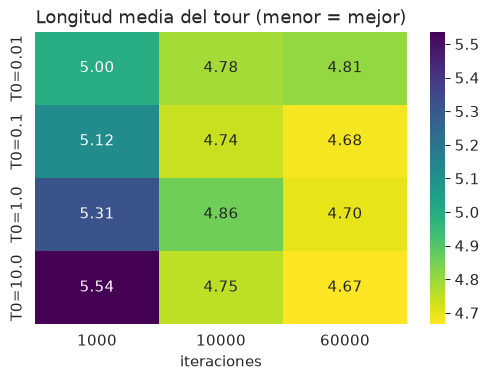

hill climbing medio: 4.921 → con pocas iteraciones o T0 muy bajo, SA no mejora a hill climbing
n=60: NN=7.73 | SA=6.62 (1.0 s)
n=100: NN=8.98 | SA=8.18 (1.0 s)
SA desde NN (T0=0.05): 4.696 vs NN 5.542 vs SA aleatorio 4.698


In [34]:
iters_l, T0_l = (1_000, 10_000, 60_000), (0.01, 0.1, 1.0, 10.0)                                      # 7-4 (60k en vez de 100k para acotar el tiempo)
heat = np.array([[np.mean([simulated_annealing_tsp(D, np.random.default_rng(s), T0=t0, iters=it)[1] for s in range(6)]) for it in iters_l] for t0 in T0_l])
fig, ax = plt.subplots(figsize=(6, 3.8)); sns.heatmap(pd.DataFrame(heat, index=[f"T0={t}" for t in T0_l], columns=iters_l), annot=True, fmt=".2f", cmap="viridis_r", ax=ax)
ax.set(title="Longitud media del tour (menor = mejor)", xlabel="iteraciones"); plt.show()
print("hill climbing medio:", round(np.mean(hc_runs), 3), "→ con pocas iteraciones o T0 muy bajo, SA no mejora a hill climbing")
for n_ in (60, 100):                                                                                 # 7-5
    p_, D_ = make_cities(n_, np.random.default_rng(n_)); t0_ = time.perf_counter()
    _, L_, _ = simulated_annealing_tsp(D_, np.random.default_rng(0), iters=120_000)
    print(f"n={n_}: NN={tour_length(nearest_neighbor_tour(D_), D_):.2f} | SA={L_:.2f} ({time.perf_counter() - t0_:.1f} s)")
_, L_nn_sa, _ = simulated_annealing_tsp(D, np.random.default_rng(3), T0=0.05, iters=30_000, start=t_nn)   # 7-6
print(f"SA desde NN (T0=0.05): {L_nn_sa:.3f} vs NN {tour_length(t_nn, D):.3f} vs SA aleatorio {L_sa:.3f}")

### 7.4 Algoritmos genéticos
**Por qué:** en vez de un solo caminante, mantén una **población** de estados. Los mejores "se reproducen" (**cruce**), se aplican pequeñas **mutaciones** y los peores desaparecen. La idea: *combinar buenas partes de distintas soluciones* (algo que los métodos de un solo estado no pueden hacer). Es especialmente útil cuando el estado tiene **bloques** que se pueden heredar intactos.

El ciclo (AIMA Fig. 4.8) para 8 reinas, con cada individuo = tupla de filas por columna:
1. **Aptitud** (*fitness*): pares que **no** se atacan = $28-\text{conflictos}$ (máx. 28 = solución).
2. **Selección** proporcional a la aptitud (más aptos → más probabilidad de ser padres).
3. **Cruce de un punto:** hijo = primeras $k$ columnas de un padre + el resto del otro.
4. **Mutación:** con baja probabilidad, mover una reina aleatoriamente.
5. Repetir hasta alcanzar fitness 28 o agotar generaciones. Usamos **elitismo** (conservar los 2 mejores) para no perder el progreso.

GA 8 reinas: resueltas 26/30 corridas | generaciones medias para resolver = 97.4
aptitud final de las corridas NO resueltas (máx. 28): [27, 27, 27, 27]


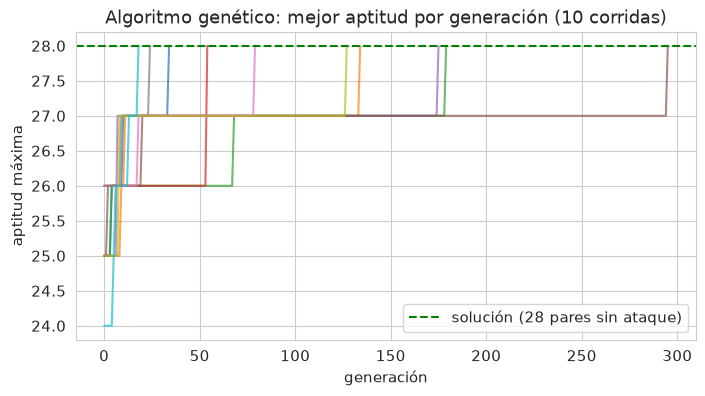

In [35]:
def genetic_queens(n=8, pop_size=100, p_mut=0.3, max_gen=500, elite=2, rng=None):
    rng = rng or np.random.default_rng()
    max_fit = n * (n - 1) // 2
    pop = rng.integers(0, n, (pop_size, n)); history = []
    for gen in range(max_gen):
        fit = max_fit - conflicts_batch(pop); history.append(fit.max())
        if fit.max() == max_fit:
            return pop[fit.argmax()], gen, np.array(history)
        probs = fit / fit.sum()                                           # ruleta: probabilidad ∝ aptitud
        parents = pop[rng.choice(pop_size, size=(pop_size - elite, 2), p=probs)]
        cut = rng.integers(1, n, pop_size - elite)                        # punto de cruce por hijo
        mask = np.arange(n)[None, :] < cut[:, None]
        kids = np.where(mask, parents[:, 0], parents[:, 1])
        mut = rng.random(len(kids)) < p_mut                               # mutación: 1 gen al azar
        kids[mut, rng.integers(0, n, mut.sum())] = rng.integers(0, n, mut.sum())
        pop = np.vstack([pop[np.argsort(fit)[-elite:]], kids])           # elitismo
    return pop[fit.argmax()], max_gen, np.array(history)

runs_ga = [genetic_queens(rng=np.random.default_rng(s)) for s in range(30)]
solved = [g for _, g, h in runs_ga if h[-1] == 28]
print(f"GA 8 reinas: resueltas {len(solved)}/30 corridas | generaciones medias para resolver = {np.mean(solved):.1f}")
print("aptitud final de las corridas NO resueltas (máx. 28):", [int(h[-1]) for _, g, h in runs_ga if h[-1] != 28])

fig, ax = plt.subplots(figsize=(8, 4))
for _, g, h in runs_ga[:10]:
    ax.plot(h, alpha=0.7)
ax.axhline(28, color="g", ls="--", label="solución (28 pares sin ataque)")
ax.set(title="Algoritmo genético: mejor aptitud por generación (10 corridas)", xlabel="generación", ylabel="aptitud máxima"); ax.grid(True); ax.legend(); plt.show()

**Qué deberías ver:** la gran mayoría de las corridas (≈ 85–90 %; en una ejecución típica unas 26 de 30) resuelve el problema, en promedio tras unas 100 generaciones; las que no lo logran se quedan estancadas con aptitud 27, a **un solo par** de la solución (**convergencia prematura**, ver Troubleshooting). Las curvas suben rápido hasta ≈ 26 y luego "escalan" el último tramo con altibajos: la **recombinación** une buenos bloques de columnas.

### Comparación de los tres métodos locales en 8 reinas
Mismo problema, tres algoritmos: ¿cuánta **computación** (número de evaluaciones de la función objetivo) necesita cada uno por solución resuelta?

In [36]:
def sa_queens(n, rng, T0=2.0, T_end=0.05, iters=20_000):
    s = rng.integers(0, n, n); E = conflicts_batch(s)[0]
    for k in range(iters):
        if E == 0:
            return s, True, k + 1
        T = T0 * (T_end / T0) ** (k / iters)
        c, r = rng.integers(0, n), rng.integers(0, n)
        if r == s[c]: continue
        s2 = s.copy(); s2[c] = r; E2 = conflicts_batch(s2)[0]; dE = E2 - E
        if dE <= 0 or rng.random() < math.exp(-dE / T):
            s, E = s2, E2
    return s, E == 0, iters

N_RUNS = 100
sa_out = [sa_queens(8, np.random.default_rng(s)) for s in range(N_RUNS)]
hc_out = [hill_climbing_queens(8, np.random.default_rng(s), sideways=100) for s in range(N_RUNS)]
ga_out = [genetic_queens(rng=np.random.default_rng(s)) for s in range(N_RUNS)]
cmp_ = pd.DataFrame({
    "Hill climbing (100 laterales)": {"éxito %": np.mean([o[1] for o in hc_out]) * 100, "evaluaciones/corrida": np.mean([(o[2] + 1) * 56 for o in hc_out])},
    "Simulated annealing": {"éxito %": np.mean([o[1] for o in sa_out]) * 100, "evaluaciones/corrida": np.mean([o[2] for o in sa_out])},
    "Algoritmo genético (pob. 100)": {"éxito %": np.mean([h[-1] == 28 for _, _, h in ga_out]) * 100, "evaluaciones/corrida": np.mean([(g + 1) * 100 for _, g, _ in ga_out])},
}).T
display(cmp_.round(1))

,éxito %,evaluaciones/corrida
Hill climbing (100 laterales),96.0,1579.8
Simulated annealing,100.0,4778.7
Algoritmo genético (pob. 100),85.0,18683.0


**Qué deberías ver:** *hill climbing* con laterales (≈ 96 %) y SA (≈ 100 %) resuelven casi siempre; el genético con 500 generaciones máximo queda más abajo (≈ 85 %). Difieren también en **cuánto cuestan** (evaluaciones de la función objetivo): *hill climbing* ≈ 1 600, SA ≈ 4 800, genético ≈ 18 700 por corrida. Aquí el más barato es *hill climbing* con laterales, pero **no generalices**: 8 reinas es un problema *fácil*; ya con $n=16$ (🔧 7-9) el genético casi no resuelve y SA sí, y para TSP o espacios mayores las diferencias son otras. Lo que sí es general: la comparación justa se hace **por número de evaluaciones** (en el Ejercicio 3 evaluar es un ajuste de mínimos cuadrados, así que contar evaluaciones importa).

### ⚠️ Troubleshooting

**Síntoma:** SA "no avanza": el costo se queda en un valor alto.
**Por qué:** temperatura inicial demasiado baja (nunca acepta empeoramientos) o escala del costo mal calibrada (ΔE típico ≫ T).
**Solución:** elige $T_0$ de modo que se acepte ≈ 50–80 % de los empeoramientos al inicio (mide ΔE con unos movimientos aleatorios), y enfría geométricamente hasta una $T$ casi nula.

**Síntoma:** el algoritmo genético converge rápido a una población **idéntica** y se estanca.
**Por qué:** pérdida de diversidad (*convergencia prematura*): selección demasiado agresiva o mutación demasiado baja.
**Solución:** más mutación, selección por torneo (menor presión), más población, o inyectar individuos aleatorios; también ayuda mantener el elitismo pequeño.

**Síntoma:** distintas ejecuciones dan resultados distintos.
**Por qué:** estos métodos son estocásticos.
**Solución:** fija la semilla para reproducir y, para comparar, **repite muchas corridas** y reporta media/distribución, nunca una sola corrida.

### 🔧 Pruébalo tú mismo

### 🔧 Pruébalo tú mismo

**7-7. Presión de selección:** cambia la selección a **torneo** (elige 3 al azar y toma el mejor). ¿Mejora la tasa de éxito o las generaciones? Prueba también `p_mut ∈ {0, 0.05, 0.3, 0.8}`.

**7-8. Sin cruce:** desactiva el cruce (el hijo es copia de un padre + mutación). ¿Sigue funcionando? ¿Qué te dice sobre cuánto aporta la recombinación en este problema?

**7-9. Más reinas:** ejecuta el GA con `n=16` y `max_gen=2000`. ¿Resuelve? ¿Y SA con 200.000 iteraciones? Compara las evaluaciones.

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 7-7, 7-8 y 7-9
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

In [37]:
def ga_variant(n=8, pop_size=100, p_mut=0.3, max_gen=500, elite=2, selection="roulette", crossover=True, rng=None):
    max_fit = n * (n - 1) // 2; pop = rng.integers(0, n, (pop_size, n))
    for gen in range(max_gen):
        fit = max_fit - conflicts_batch(pop)
        if fit.max() == max_fit: return True, gen
        if selection == "roulette":
            idx = rng.choice(pop_size, size=(pop_size - elite, 2), p=fit / fit.sum())
        else:                                                                    # torneo de tamaño 3
            cand = rng.integers(0, pop_size, (pop_size - elite, 2, 3)); idx = np.take_along_axis(cand, fit[cand].argmax(axis=2)[..., None], axis=2)[..., 0]
        parents = pop[idx]; cut = rng.integers(1, n, pop_size - elite)
        kids = np.where(np.arange(n)[None, :] < cut[:, None], parents[:, 0], parents[:, 1]) if crossover else parents[:, 0].copy()
        mut = rng.random(len(kids)) < p_mut; kids[mut, rng.integers(0, n, mut.sum())] = rng.integers(0, n, mut.sum())
        pop = np.vstack([pop[np.argsort(fit)[-elite:]], kids])
    return False, max_gen
rows = []
for name, kw in [("ruleta, p_mut=0.3", {}), ("torneo, p_mut=0.3", {"selection": "tournament"}), ("ruleta, p_mut=0", {"p_mut": 0.0}),
                 ("ruleta, p_mut=0.8", {"p_mut": 0.8}), ("sin cruce", {"crossover": False})]:
    out = [ga_variant(rng=np.random.default_rng(s), **kw) for s in range(25)]
    rows.append({"variante": name, "éxito %": 100 * np.mean([o[0] for o in out]), "gen. medias (éxito)": np.mean([g for ok, g in out if ok]) if any(ok for ok, _ in out) else np.nan})
tab_ga = pd.DataFrame(rows).set_index("variante"); display(tab_ga.round(1))
print(f"Sin mutación el GA se estanca ({tab_ga.loc['ruleta, p_mut=0', 'éxito %']:.0f} % de éxito: la población pierde diversidad). "
      f"Sin cruce funciona casi igual en éxito ({tab_ga.loc['sin cruce', 'éxito %']:.0f} % vs {tab_ga.loc['ruleta, p_mut=0.3', 'éxito %']:.0f} %) pero necesita "
      f"{tab_ga.loc['sin cruce', 'gen. medias (éxito)'] / tab_ga.loc['ruleta, p_mut=0.3', 'gen. medias (éxito)']:.1f}× más generaciones: aquí el cruce acelera, no es imprescindible.")
out16 =[genetic_queens(n=16, max_gen=2000, rng=np.random.default_rng(s)) for s in range(5)]
print("GA n=16: resueltas", sum(h[-1] == 120 for _, _, h in out16), "/ 5 | generaciones:", [g for _, g, _ in out16])
print("SA n=16:", [sa_queens(16, np.random.default_rng(s), iters=200_000)[1:] for s in range(3)])

,éxito %,gen. medias (éxito)
variante,,
"ruleta, p_mut=0.3",88.0,92.4
"torneo, p_mut=0.3",76.0,96.5
"ruleta, p_mut=0",24.0,23.3
"ruleta, p_mut=0.8",76.0,175.0
sin cruce,84.0,167.6


Sin mutación el GA se estanca (24 % de éxito: la población pierde diversidad). Sin cruce funciona casi igual en éxito (84 % vs 88 %) pero necesita 1.8× más generaciones: aquí el cruce acelera, no es imprescindible.
GA n=16: resueltas 1 / 5 | generaciones: [1957, 2000, 2000, 2000, 2000]
SA n=16: [(True, 116673), (True, 106986), (True, 99470)]


### 📊 Resumen visual — búsqueda local
```
  MÉTODO                 MEMORIA    IDEA                              LIMITACIÓN                      ESCAPA DE ÓPTIMOS LOCALES
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  Hill climbing          O(1)       subir siempre                      óptimos locales y mesetas       NO  (arreglos: laterales, reinicios)
  Random restart         O(1)       repetir desde puntos al azar       necesita muchos intentos        sí, por fuerza bruta
  Simulated annealing    O(1)       aceptar empeoramientos con e^(-ΔE/T)  calendario de T delicado     SÍ, probabilísticamente
  Local beam search      O(k)       k estados, quedarse con los k mejores   se concentran (poca diversidad) parcial
  Algoritmo genético     O(pob.)    población + cruce + mutación       diversidad / codificación       SÍ, recombinando bloques
```

## 8. Entornos complejos (AIMA 4.3 – 4.5): panorama

Todo lo anterior supone un entorno **determinista, observable y conocido**. Si eso cambia, la solución deja de ser una secuencia y pasa a ser **un plan condicional o una política**. AIMA cap. 4 lo presenta; aquí un mapa conceptual (no lo implementamos todo: hacerlo bien merece un capítulo, y te evalúan sobre todo la idea y el algoritmo en papel):

| Situación | Qué cambia | Idea de solución | Ejemplo |
|---|---|---|---|
| **No determinista** (4.3) | la acción puede tener varios resultados | **búsqueda AND-OR**: un *plan condicional* con `if-then-else` que cubra todos los resultados | aspiradora "errática" que a veces ensucia |
| **Parcialmente observable** (4.4) | no sabes en qué estado estás | buscar en el espacio de **estados de creencia** (conjuntos de estados posibles) | robot sin sensor (*sensorless*) que se localiza chocando con paredes |
| **Búsqueda online / desconocida** (4.5) | no conoces el mapa; exploras mientras actúas | **LRTA\***, DFS online (el agente aprende $h$ al moverse) | robot explorando un edificio |
| **Espacios continuos** (4.2) | infinitos estados y acciones | **gradiente**, Newton–Raphson, discretización | ajustar parámetros reales (NB-03 sec. 7; NB-11) |
| **Con adversario** (cap. 5) | otro agente se opone | **minimax**, poda alfa-beta | juegos (NB-05) |
| **Restricciones** (cap. 6) | estado = asignación de variables | **backtracking + propagación** | Sudoku (NB-06) |

> **Conexión con la tesis y con NB-08:** un **HMM** es un modelo de un entorno *parcialmente observable*: no ves el estado real, solo observaciones ruidosas, y mantienes una **distribución de creencia** sobre los estados. Y el algoritmo de **Viterbi** que decodifica el mensaje más probable en comunicaciones digitales es, exactamente, un **camino de costo mínimo en un *trellis*** (un grafo por capas): una búsqueda de costo uniforme/programación dinámica sobre el espacio de estados del codificador.

## 9. Tabla comparativa (AIMA Fig. 3.15) 🧠 *para memorizar antes de la Solemne*

Con $b$ = factor de ramificación, $d$ = profundidad de la solución menos profunda, $m$ = profundidad máxima, $\ell$ = límite de profundidad, $C^*$ = costo óptimo, $\epsilon$ = costo mínimo de acción.

| Algoritmo | Completo | Óptimo | Tiempo | Espacio | Cuándo usarlo |
|---|---|---|---|---|---|
| **BFS** | Sí (si $b$ finito) | Sí si costos iguales | $O(b^d)$ | $O(b^d)$ | solución superficial; mucha memoria disponible |
| **UCS / Dijkstra** | Sí (si costos $\ge\epsilon>0$) | **Sí** | $O(b^{1+\lfloor C^*/\epsilon\rfloor})$ | ídem | costos variables y sin heurística |
| **DFS** | **No** en árbol/infinito; sí en grafo finito | No | $O(b^m)$ | **$O(bm)$** | memoria escasa; muchas soluciones profundas |
| **Depth-limited** | No (si $\ell<d$) | No | $O(b^\ell)$ | $O(b\ell)$ | se conoce una cota de profundidad |
| **IDS** | Sí | Sí si costos iguales | $O(b^d)$ | **$O(bd)$** | **espacio grande y profundidad desconocida** (la opción ciega por defecto) |
| **Bidireccional** | Sí | Sí si costos iguales | $O(b^{d/2})$ | $O(b^{d/2})$ | meta única y acciones reversibles |
| **Greedy (mejor primero con $h$)** | No en árbol; sí en grafo finito | No | $O(b^m)$ peor caso | ídem | respuesta rápida "suficientemente buena" |
| **A\*** | Sí | **Sí** si $h$ admisible (árbol) / consistente (grafo) | exponencial en el error de $h$ | todos los nodos en memoria | la opción **informada** por defecto |
| **IDA\*, RBFS, SMA\*** | Sí | Sí (mismas condiciones) | similar a A\* | **lineal / acotada** | A\* se queda sin memoria |

### Cómo elegir (árbol de decisión práctico)
```
 ¿Importa el camino o solo el estado final?
   ├─ solo el estado final ───────► BÚSQUEDA LOCAL (hill climbing + reinicios · SA · genético)
   └─ importa el camino
        ├─ ¿hay una buena heurística admisible?
        │     ├─ sí ───► A*  (si falta memoria: IDA*/SMA*;  si basta "bueno": A* ponderado)
        │     └─ no
        │          ├─ costos variables ──► UCS (Dijkstra)
        │          ├─ costos iguales y memoria sobra ──► BFS
        │          └─ costos iguales y memoria escasa ──► IDS
```

## 10. 📋 Cheat Sheet

| Concepto / Función | Qué hace | Cuándo usarlo | Sintaxis rápida |
|---|---|---|---|
| `Problem` (subclase) | define estado, acciones, transición, meta, costo | siempre que formules un problema | `class P(Problem): actions(s), result(s,a), is_goal(s)` |
| Estado hasheable | permite `reached`/`set` | evitar repetir estados | usar **tuplas**, nunca listas/arrays |
| `best_first_search(p, f)` | expande el menor $f(n)$ | núcleo de UCS, greedy, A\* | `best_first_search(p, lambda n: n.path_cost + p.h(n))` |
| `breadth_first_search(p)` | por capas de pasos | pasos mínimos, costos iguales | test de meta al **generar** |
| `uniform_cost_search(p)` | menor $g(n)$ | costos distintos (Dijkstra) | test de meta al **expandir** |
| `depth_first_search(p, check=…)` | pila LIFO | memoria mínima | `check`: `"graph"` · `"cycle"` · `"none"` (¡puede ciclar!) |
| `iterative_deepening_search(p)` | DFS con límite creciente | ciego por defecto (espacio grande) | memoria $O(bd)$ |
| `astar_search(p, W)` | $f=g+W\,h$ | informada óptima ($W=1$) o rápida ($W>1$) | `astar_search(p, W=1.0)` |
| Heurística admisible | $h\le h^*$ | garantía de optimalidad | derívala **relajando** el problema |
| Heurística consistente | $h(n)\le c+h(n')$ | A\* en grafos | $f$ no decrece a lo largo de caminos |
| Dominancia | $h_2\ge h_1$ (ambas admisibles) | elegir entre heurísticas | la mayor expande menos nodos |
| $b^*$ | $N+1=\sum_{i=0}^d b^{*i}$ | medir calidad de $h$ | `brentq(lambda b: (b**(d+1)-1)/(b-1)-(N+1), 1+1e-9, 50)` |
| Paridad (8-puzzle) | ¿tiene solución? | antes de buscar | nº de inversiones **par** (3×3) |
| `heapq` + contador | cola de prioridad estable | frontera de A\*/UCS | `heappush(q, (f, contador, nodo))` |
| Hill climbing | sube al mejor vecino | optimización rápida | se atasca: laterales, reinicios |
| Simulated annealing | acepta peor con $e^{-\Delta E/T}$ | escapar de óptimos locales | `T = T0*(Tend/T0)**(k/iters)` |
| 2-opt | invierte un tramo del tour | TSP | $\Delta=D_{ac}+D_{bd}-D_{ab}-D_{cd}$ en $O(1)$ |
| Algoritmo genético | población + cruce + mutación | codificaciones con bloques | elitismo + diversidad |
| Búsqueda AND-OR | plan condicional | entornos no deterministas | (concepto, AIMA 4.3) |

## 11. Conexiones con el Mundo Real

**En la industria.** **Navegación y mapas:** los servicios de rutas usan variantes de A\* y Dijkstra con precomputación (*landmarks*, *contraction hierarchies*) para responder en milisegundos sobre grafos de cientos de millones de nodos. **Videojuegos y robótica:** A\* sobre grillas o mallas de navegación mueve a los personajes y a los robots de bodega; la búsqueda local y SA se usan para **planificar turnos, horarios y rutas de reparto** (TSP/VRP). **Optimización de hiperparámetros** y de arquitecturas (NAS) son búsquedas locales/evolutivas en un espacio gigante.

**Comunicaciones Digitales.** El enrutamiento de estado de enlace (**OSPF**) ejecuta **Dijkstra** (= costo uniforme) en cada router sobre la topología de la red, con el costo del enlace (ancho de banda, retardo) como $c(s,a,s')$. El **algoritmo de Viterbi** que decodifica códigos convolucionales y ecualiza con ISI es un camino de costo mínimo en un *trellis* (NB-08). Planificar la ubicación de antenas o asignar frecuencias son problemas de búsqueda local/CSP.

**Sistemas Distribuidos.** Descubrimiento de rutas, balanceo de carga y *scheduling* de tareas son problemas de búsqueda; paralelizar A\* es difícil porque la frontera es una estructura compartida y el orden importa (sobrecarga de coordinación). El costo de memoria de A\* es el cuello de botella típico a escala.

**Big Data.** Grafos de redes sociales y carreteras no caben en un nodo: se particionan (ver NB-22) y se usan algoritmos de camino mínimo distribuidos (Pregel/Giraph: Dijkstra como cómputo "centrado en vértices") o aproximaciones.

**Tesis (SNN + diagrama de ojo + BER).** Los hiperparámetros de tu ecualizador (nº de neuronas, umbrales, constantes de tiempo) forman un espacio de búsqueda con **plateaus y óptimos locales** y una función objetivo **cara de evaluar** (cada punto = una simulación). Eso es exactamente el terreno de **SA, algoritmos genéticos y búsqueda local**, con un presupuesto de evaluaciones limitado. En el Ejercicio 3 lo practicas con un ecualizador lineal; con tu SNN será la misma lógica (y después, optimización bayesiana / *surrogate models* si evaluar es muy caro).

**Contexto chileno / latinoamericano.** Logística de última milla en Santiago (rutas de reparto = VRP), planificación de turnos en minería y salud, asignación de horarios universitarios (CSP + búsqueda local, NB-06), y enrutamiento de transporte público son problemas reales que se atacan con las técnicas de este notebook.

**Limitaciones y honestidad.**
- La búsqueda sistemática sufre la **explosión combinatoria**: sin buenas heurísticas, nada sirve a escala. **Diseñar $h$ es la parte difícil** (y la heurística perfecta equivale a resolver el problema).
- A\* es limitado por **memoria**, no por tiempo; en la práctica se usa IDA\*, SMA\* o A\* ponderado.
- La búsqueda local **no garantiza optimalidad ni completitud**; su calidad depende de la representación, los vecinos y los hiperparámetros del propio algoritmo (calendario de SA, tamaño de población).
- Para problemas con estructura (rutas, flujos, asignación lineal) existen **algoritmos exactos específicos** (Dijkstra, Hungarian, programación lineal entera/solvers como OR-Tools) que superan con creces a SA/GA. Usa búsqueda local cuando la estructura es difícil de explotar.
- En deep learning, el "descenso" que vemos aquí se sustituye por **gradientes** (NB-11, NB-16), pero la intuición de paisajes con óptimos locales y mesetas es la misma.

## 12. Ejercicios progresivos

Cada nivel tiene una celda **"Tu turno"** y, **después**, su solución completa en celdas separadas. Intenta resolverlo tú primero.

---
### Nivel 1 — Reproducir (guiado): laberinto con costos de terreno
**Objetivo:** ver por qué BFS **deja de ser óptimo** cuando las acciones tienen costos distintos, y que A\* con la heurística correcta sigue siendo óptimo.

**Pasos:**
1. Construye una grilla de 20×20 con `make_grid(20, 0.2, ...)` y una matriz `costs` del mismo tamaño con terrenos: pasto = 1 (por defecto), **barro = 3** en una franja y **agua = 8** en otra (que cruce el camino directo).
2. Crea `GridProblem(grid, (0, 0), (19, 19), costs=costs)` y ejecuta **BFS** y **UCS**. Compara costo y número de pasos.
3. Ejecuta **A\*** con la heurística de `GridProblem` (Manhattan × costo mínimo). Verifica que su costo coincide con UCS y que expande menos nodos.
4. Dibuja BFS y A\* sobre el mapa (usa `draw_grid`) y comenta por qué la ruta óptima **rodea** el agua.

> 💡 **Hints:** `costs = np.ones((20, 20)); costs[8:12, :] = 8`; `costs` se aplica al **entrar** en una celda; cuida que el agua no tape *todo* el camino (deja un hueco o usa `make_grid` hasta que sea resoluble).

In [38]:
# Tu turno (Nivel 1)

#### ✅ Solución — Nivel 1

BFS : 38 pasos, costo real = 93, expandidos = 332
UCS : 42 pasos, costo real = 42, expandidos = 255
A*  : 42 pasos, costo real = 42, expandidos = 123


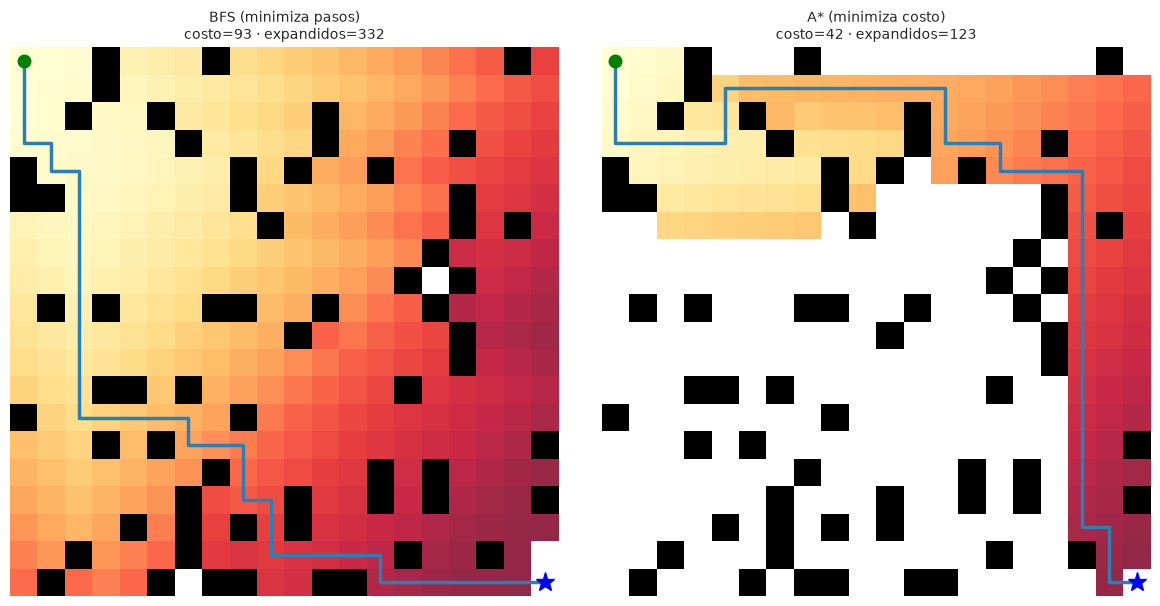

In [39]:
g1 = make_grid(20, 0.20, np.random.default_rng(4))
costs1 = np.ones((20, 20)); costs1[5:8, 2:16] = 3.0; costs1[11:14, 0:17] = 8.0         # franja de barro y franja de agua (con paso libre a la derecha)
g1[11:14, 17:20] = 0                                                                     # garantizamos un "puente" libre por el lado derecho
g1[0, 0] = g1[-1, -1] = 0
p1 = GridProblem(g1, (0, 0), (19, 19), costs=costs1)
bfs1, ucs1, ast1 = breadth_first_search(p1), uniform_cost_search(p1), astar_search(p1)
cost_of = lambda r: sum(costs1[s] for s in r.node.path_states()[1:])                      # costo REAL de la ruta de BFS bajo los terrenos
print(f"BFS : {bfs1.length} pasos, costo real = {cost_of(bfs1):.0f}, expandidos = {len(bfs1.expanded)}")
print(f"UCS : {ucs1.length} pasos, costo real = {ucs1.cost:.0f}, expandidos = {len(ucs1.expanded)}")
print(f"A*  : {ast1.length} pasos, costo real = {ast1.cost:.0f}, expandidos = {len(ast1.expanded)}")
assert abs(ast1.cost - ucs1.cost) < 1e-9 and cost_of(bfs1) >= ucs1.cost and len(ast1.expanded) <= len(ucs1.expanded)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (nm, r) in zip(axes, [("BFS (minimiza pasos)", bfs1), ("A* (minimiza costo)", ast1)]):
    ax.imshow(costs1, cmap="Greens_r", alpha=0.35); draw_grid(ax, g1, r, nm)
plt.tight_layout(); plt.show()

**Qué deberías ver:** BFS devuelve la ruta con **menos pasos**, que atraviesa el barro/agua y por eso **cuesta más**; UCS y A\* devuelven la misma ruta de costo mínimo (a veces con **más pasos**: dan un rodeo para evitar el agua) y A\* expande menos celdas. En el mapa, la zona verde más oscura es el terreno caro. Es la prueba de que *"óptimo" depende del criterio*: BFS es óptimo en pasos, no en costo.

---
### Nivel 2 — Aplicar (problema nuevo): misioneros y caníbales
**Problema (AIMA ejercicio 3.9):** tres misioneros y tres caníbales deben cruzar un río en un bote con capacidad para **2** personas. En **ninguna orilla** (ni en el bote) puede haber más caníbales que misioneros *si hay al menos un misionero* (los comerían). El bote necesita al menos 1 persona para moverse.

**Tu tarea (sin paso a paso):**
1. **Formula** el problema como subclase de `Problem`: define el estado (por ejemplo `(misioneros_izq, caníbales_izq, bote_izq)`), las acciones, la transición y el test de meta. Generalízalo a `n` misioneros/caníbales y bote de capacidad `cap`.
2. Resuélvelo con **BFS** y con **IDS**. ¿Cuántos cruces mínimos necesitas para `n=3, cap=2`? ¿Cuántos estados válidos tiene el espacio?
3. Imprime la secuencia de movimientos de la solución.
4. Prueba `n=4, cap=2` y `n=4, cap=3` (y `n=5, cap=3`). ¿Alguno **no tiene solución**? ¿Cómo lo detecta tu algoritmo?
5. Explica en una línea por qué usar búsqueda en **grafo** (con `reached`) es esencial aquí.

In [40]:
# Tu turno (Nivel 2)

#### ✅ Solución — Nivel 2

In [41]:
class MissionariesCannibals(Problem):
    # Estado: (misioneros en la orilla izquierda, caníbales en la izquierda, bote en la izquierda: 1/0)
    def __init__(self, n=3, cap=2):
        super().__init__((n, n, 1), (0, 0, 0)); self.n, self.cap = n, cap

    def safe(self, m, c):
        left_ok = (m == 0) or (m >= c)                               # orilla izquierda: sin misioneros o no superados
        right_ok = (self.n - m == 0) or (self.n - m >= self.n - c)
        return left_ok and right_ok

    def actions(self, s):
        m, c, boat = s; acts = []
        for dm in range(self.cap + 1):
            for dc in range(self.cap + 1 - dm):
                if 1 <= dm + dc <= self.cap:
                    nm, nc = (m - dm, c - dc) if boat else (m + dm, c + dc)   # el bote lleva dm misioneros y dc caníbales
                    if 0 <= nm <= self.n and 0 <= nc <= self.n and self.safe(nm, nc):
                        acts.append((dm, dc))
        return acts

    def result(self, s, a):
        m, c, boat = s; dm, dc = a
        return (m - dm, c - dc, 0) if boat else (m + dm, c + dc, 1)

mc = MissionariesCannibals(3, 2)
r_bfs, r_ids = breadth_first_search(mc), iterative_deepening_search(mc)
seen, stack = {mc.initial}, [mc.initial]                          # espacio completo alcanzable (sin detenerse en la meta)
while stack:
    st = stack.pop()
    for a in mc.actions(st):
        nxt = mc.result(st, a)
        if nxt not in seen: seen.add(nxt); stack.append(nxt)
print(f"n=3, cap=2 → cruces mínimos BFS = {r_bfs.length} | IDS = {r_ids.length} | estados válidos alcanzables en total = {len(seen)}")
for st, act in zip(r_bfs.node.path_states(), [None] + r_bfs.node.path_actions()):
    print(f"  {'inicio' if act is None else f'lleva {act[0]}M+{act[1]}C':>14} → (M izq={st[0]}, C izq={st[1]}, bote={'izq' if st[2] else 'der'})")
assert r_bfs.length == 11 == r_ids.length

for n_, cap_ in [(3, 2), (4, 2), (4, 3), (5, 3)]:
    r = breadth_first_search(MissionariesCannibals(n_, cap_))
    print(f"n={n_}, cap={cap_}: {'solución en ' + str(r.length) + ' cruces' if r.found else 'SIN SOLUCIÓN (BFS agotó ' + str(len(r.expanded)) + ' estados alcanzables)'}")
# Sin `reached` el bote iría y vendría infinitamente entre los mismos estados (ciclos); con el grafo explícito el espacio es finito y BFS termina,
# de modo que "no hay solución" es una respuesta DEMOSTRADA (completitud en espacios finitos), no un tiempo agotado.

n=3, cap=2 → cruces mínimos BFS = 11 | IDS = 11 | estados válidos alcanzables en total = 16
          inicio → (M izq=3, C izq=3, bote=izq)
     lleva 0M+2C → (M izq=3, C izq=1, bote=der)
     lleva 0M+1C → (M izq=3, C izq=2, bote=izq)
     lleva 0M+2C → (M izq=3, C izq=0, bote=der)
     lleva 0M+1C → (M izq=3, C izq=1, bote=izq)
     lleva 2M+0C → (M izq=1, C izq=1, bote=der)
     lleva 1M+1C → (M izq=2, C izq=2, bote=izq)
     lleva 2M+0C → (M izq=0, C izq=2, bote=der)
     lleva 0M+1C → (M izq=0, C izq=3, bote=izq)
     lleva 0M+2C → (M izq=0, C izq=1, bote=der)
     lleva 0M+1C → (M izq=0, C izq=2, bote=izq)
     lleva 0M+2C → (M izq=0, C izq=0, bote=der)
n=3, cap=2: solución en 11 cruces
n=4, cap=2: SIN SOLUCIÓN (BFS agotó 11 estados alcanzables)
n=4, cap=3: solución en 9 cruces
n=5, cap=3: solución en 11 cruces


**Qué deberías ver:** la solución clásica de **11 cruces** para (3 misioneros, 3 caníbales, bote de 2), idéntica con BFS e IDS, dentro de un espacio de apenas unos 15–16 estados válidos alcanzables (el número exacto lo imprime el código); la tabla final muestra que `n=4, cap=2` **no tiene solución** (BFS lo declara tras agotar el espacio finito) mientras que `n=4, cap=3` y `n=5, cap=3` sí. Ese "no hay solución" es un resultado **demostrado**: es una de las ventajas de la búsqueda sistemática frente a la local.

---
### Nivel 3 — Integrar (NB-03 + Tesis): búsqueda local de hiperparámetros del ecualizador
**Contexto:** en NB-03 (Ejercicio 3) diseñaste un ecualizador FIR por mínimos cuadrados con parámetros elegidos "a ojo": longitud `L`, retardo `d` y (si añades regularización Ridge) `λ`. Ahora los vas a **buscar automáticamente**. Este es el ensayo general de optimizar los hiperparámetros de tu ecualizador SNN, donde cada evaluación será una simulación cara.

**Tu tarea:**
1. Reutiliza el canal $h=[0.9,0.45,0.25]$ a $E_b/N_0=12$ dB (ver NB-03 Nivel 3) y genera una secuencia de **entrenamiento** y otra de **validación** de 6.000 símbolos BPSK.
2. Define el espacio de configuraciones `(L, d, k)` con `L ∈ {3,…,15}`, `d ∈ {0,…,8}` con `d < L` y `k ∈ {0,…,14}` indexando $\log_{10}\lambda\in[-6,1]$ (15 valores). El **costo** de una configuración es el **MSE en validación** del ecualizador Ridge entrenado en la secuencia de entrenamiento.
3. Calcula el **óptimo global por fuerza bruta** (¿cuántas configuraciones hay?) y úsalo como referencia.
4. Implementa **hill climbing** (vecinos = ±1 en un parámetro) con reinicios y **SA** sobre este espacio, **contando evaluaciones** (usa una caché para no re-evaluar), y añade una **línea base de búsqueda aleatoria** con el mismo presupuesto. Mide qué % del espacio es *mejor* que lo que encuentra cada método. ¿Le ganan tus algoritmos a la búsqueda aleatoria?
5. Reflexiona: ¿qué pasa con las **mesetas** en el costo vs `d`? ¿Cuándo valdría la pena *no* usar fuerza bruta?

In [42]:
# Tu turno (Nivel 3)

#### ✅ Solución — Nivel 3

In [43]:
rs = np.random.default_rng(7)
h_ch = np.array([0.9, 0.45, 0.25]); sigma = np.sqrt(np.sum(h_ch ** 2) / (2 * 10 ** (12 / 10)))      # Eb/N0 = 12 dB (como en NB-03)
def make_data(n, rng):
    x = 2.0 * rng.integers(0, 2, n) - 1.0
    return x, np.convolve(x, h_ch)[:n] + sigma * rng.normal(size=n)
x_tr, y_tr = make_data(6000, rs); x_va, y_va = make_data(6000, rs)
LAMBDAS = np.logspace(-6, 1, 15)

def windows(y, L):
    return sliding_window_view(np.concatenate([np.zeros(L - 1), y]), L)[:, ::-1]
def target(x, d):
    return np.concatenate([np.zeros(d), x])[:len(x)]

def val_mse(cfg):
    L, d, k = cfg
    Y = windows(y_tr, L); w = np.linalg.solve(Y.T @ Y + LAMBDAS[k] * np.eye(L), Y.T @ target(x_tr, d))        # Ridge (NB-03 sec. 5.3)
    return float(np.mean((windows(y_va, L) @ w - target(x_va, d))[d:] ** 2))

space = [(L, d, k) for L in range(3, 16) for d in range(0, 9) if d < L for k in range(15)]
brute = {c: val_mse(c) for c in space}
best_cfg = min(brute, key=brute.get); best = brute[best_cfg]
print(f"{len(space)} configuraciones | óptimo global: L,d,k = {best_cfg} → MSE = {best:.5f} (λ = {LAMBDAS[best_cfg[2]]:.1e})")
print(f"MSE mediano del espacio: {np.median(list(brute.values())):.4f} | peor: {max(brute.values()):.4f}")

1440 configuraciones | óptimo global: L,d,k = (15, 3, 0) → MSE = 0.04997 (λ = 1.0e-06)
MSE mediano del espacio: 0.0504 | peor: 0.2668


In [44]:
class CountedObjective:
    # Envuelve el costo con una caché: cuenta solo evaluaciones DISTINTAS (lo que de verdad "cuesta" en una simulación)
    def __init__(self): self.cache = {}; self.history = []
    def __call__(self, cfg):
        if cfg not in self.cache:
            self.cache[cfg] = val_mse(cfg)
        self.history.append(min(self.cache.values())); return self.cache[cfg]
    @property
    def n_evals(self): return len(self.cache)

def neighbors_cfg(cfg):
    L, d, k = cfg; out = []
    for dL, dd, dk in [(1, 0, 0), (-1, 0, 0), (0, 1, 0), (0, -1, 0), (0, 0, 1), (0, 0, -1)]:
        c = (L + dL, d + dd, k + dk)
        if 3 <= c[0] <= 15 and 0 <= c[1] <= 8 and c[1] < c[0] and 0 <= c[2] <= 14: out.append(c)
    return out

def hill_climb_cfg(obj, rng, restarts=5):
    for _ in range(restarts):
        cur = space[rng.integers(len(space))]
        while True:
            best_n = min(neighbors_cfg(cur), key=obj)                       # steepest ascent: evalúa TODOS los vecinos
            if obj(best_n) < obj(cur) - 1e-12: cur = best_n
            else: break                                                     # óptimo local o meseta
    return min(obj.cache, key=obj.cache.get)

def sa_cfg(obj, rng, iters=250, T0=0.05, T_end=1e-4):
    cur = space[rng.integers(len(space))]; E = obj(cur)
    for k in range(iters):
        T = T0 * (T_end / T0) ** (k / iters); cand = neighbors_cfg(cur)[rng.integers(len(neighbors_cfg(cur)))]
        dE = obj(cand) - E
        if dE <= 0 or rng.random() < math.exp(-dE / T): cur, E = cand, obj(cand)
    return min(obj.cache, key=obj.cache.get)

In [45]:
def random_search_cfg(obj, rng, budget=150):
    # Línea base obligatoria: ¿le gana nuestro algoritmo "inteligente" a probar configuraciones al azar con el mismo presupuesto?
    for idx in rng.choice(len(space), budget, replace=False):
        obj(space[idx])
    return min(obj.cache, key=obj.cache.get)

sorted_vals = np.sort(list(brute.values()))
pct_better = lambda cfg: 100 * np.searchsorted(sorted_vals, brute[cfg]) / len(sorted_vals)      # % del espacio MEJOR que lo hallado
methods = {"Hill climbing + reinicios": hill_climb_cfg, "Simulated annealing": sa_cfg, "Búsqueda aleatoria (150 evals)": random_search_cfg}
rows = []
for seed in range(20):
    for name, fn in methods.items():
        obj = CountedObjective(); cfg = fn(obj, np.random.default_rng(seed))
        rows.append({"método": name, "error vs óptimo %": 100 * (brute[cfg] / best - 1), "evaluaciones": obj.n_evals,
                     "% del espacio mejor": pct_better(cfg), "≤0.2% del óptimo": brute[cfg] <= best * 1.002})
res_hp = pd.DataFrame(rows)
display(res_hp.groupby("método").agg(**{"error medio %": ("error vs óptimo %", "mean"), "evaluaciones medias": ("evaluaciones", "mean"),
                                       "% del espacio mejor (media)": ("% del espacio mejor", "mean"),
                                       "% corridas ≤0.2 % del óptimo": ("≤0.2% del óptimo", lambda s: 100 * s.mean())}).round(3))
print(f"Fuerza bruta: {len(space)} evaluaciones. Mediana del espacio a {100 * (np.median(sorted_vals) / best - 1):.1f} % del óptimo (¡paisaje muy plano!).")
assert (res_hp["error vs óptimo %"] < 100).all()

,error medio %,evaluaciones medias,% del espacio mejor (media),% corridas ≤0.2 % del óptimo
método,,,,
Búsqueda aleatoria (150 evals),0.00e+00,150.00,0.49,100.0
Hill climbing + reinicios,2.00e-03,173.35,0.20,100.0
Simulated annealing,3.00e-03,147.85,0.77,100.0


Fuerza bruta: 1440 evaluaciones. Mediana del espacio a 0.9 % del óptimo (¡paisaje muy plano!).


**Qué deberías ver (y una lección incómoda):** el espacio tiene **1 440 configuraciones**; la fuerza bruta las evalúa todas y da el óptimo global como referencia. *Hill climbing con reinicios* y *SA* lo encuentran (o quedan a una fracción de %) evaluando ~150–170 configuraciones, **un 10 % del espacio**… pero la **búsqueda aleatoria con 150 evaluaciones hace lo mismo**: en la tabla, los tres métodos quedan prácticamente empatados (todos en el ~1 % mejor del espacio, y el MSE mediano del espacio está a menos de 1 % del óptimo).

¿Por qué? Porque este problema es **demasiado pequeño y plano**: casi cualquier configuración razonable es buena (el MSE casi no cambia con `d` para `d ≤ 4`; lo viste en NB-03). La búsqueda local **no aporta** cuando el paisaje no tiene estructura que aprovechar. Esta es una lección metodológica que vale oro: **siempre compara tu algoritmo "inteligente" contra una línea base de búsqueda aleatoria con el mismo presupuesto**. Si no le gana, no necesitas el algoritmo sofisticado.

**Reflexión para la tesis:** con tu ecualizador SNN la situación será distinta: más hiperparámetros (umbral, constantes de tiempo, número de neuronas, tasa de aprendizaje), un espacio **grande**, evaluaciones **caras** (minutos u horas) y **ruidosas** (cada evaluación es una simulación estocástica); ahí la fuerza bruta es inviable y la búsqueda aleatoria deja de bastar si hay interacciones entre parámetros. El repertorio de partida es el de este notebook: *hill climbing con reinicios* (barato, robusto si el paisaje es suave), **SA** (óptimos locales/mesetas), **algoritmos genéticos** (estructura combinatoria) y, como siguiente nivel, **optimización bayesiana** (modelo sustituto que decide qué evaluar). Usa siempre la búsqueda aleatoria como control.

## 13. Resumen

1. Un problema de búsqueda = **estado inicial, acciones, transición, meta y costo**; todos los algoritmos sistemáticos son *best-first search* con distinta $f(n)$ (BFS: profundidad; UCS: $g$; greedy: $h$; **A\***: $g+h$), y se evalúan por **completitud, optimalidad y complejidad**.
2. **A\*** es óptimo con heurísticas **admisibles** (árbol) o **consistentes** (grafo); una heurística que **domina** a otra expande menos nodos, y $b^*$ (factor de ramificación efectivo) cuantifica su calidad; las heurísticas se derivan **relajando** el problema.
3. Sin heurística y con poca memoria, **IDS** es la opción ciega por defecto; DFS en árbol **no es completo** (ciclos) y BFS/UCS/A\* consumen memoria exponencial.
4. Cuando **solo importa el estado final**, la **búsqueda local** (hill climbing, SA, genéticos) usa memoria constante y escala a problemas enormes a cambio de perder garantías: se atasca en óptimos locales y mesetas, que mitigan los reinicios, los movimientos laterales y la aleatoriedad controlada.
5. La elección del algoritmo depende del problema (¿camino o estado?, ¿heurística?, ¿memoria?, ¿costos?): domina la **tabla comparativa** de la sección 9 y el árbol de decisión.

## Siguiente paso
→ **Continúa en:** **NB-05 — Búsqueda Adversarial (Juegos)** (AIMA cap. 5): minimax y poda alfa-beta reutilizan el marco `Problem` y las ideas de heurística de evaluación. En paralelo, **NB-06 — CSP** (backtracking = DFS con propagación) y, para la parte probabilística y Viterbi, **NB-08**.

## Para profundizar
- *AIMA 4.ª ed.*, cap. 3: 3.3 (algoritmos de búsqueda, Fig. 3.7 *best-first*), 3.4 (búsqueda no informada), 3.5 (informada, A\* y su demostración de optimalidad), 3.6 (heurísticas, dominancia, relajación y *pattern databases*); cap. 4: 4.1 (*hill climbing*, *simulated annealing*, *genetic algorithms*), 4.3–4.5 (AND-OR, estados de creencia, búsqueda online).
- *CLRS*, cap. 22–24: BFS/DFS y caminos mínimos (Dijkstra, Bellman–Ford) con sus demostraciones de corrección y complejidad.
- Paper: Hart, Nilsson & Raphael, "A Formal Basis for the Heuristic Determination of Minimum Cost Paths" (1968), el artículo original de A\*; y Kirkpatrick, Gelatt & Vecchi, "Optimization by Simulated Annealing" (*Science*, 1983).
- Para práctica: el repositorio de código de AIMA (`aima-python`, módulos `search.py`) implementa la misma estructura `Problem`/`Node` que usamos aquí.
- Herramientas reales: **OR-Tools** (Google) para TSP/VRP; `networkx.astar_path` para grafos.

---

# Parte II · De la lista de recomendaciones al recorrido

> **El hilo completo, y dónde encaja esta parte.**
>
> ```
> NB-01   catálogo limpio, etiquetas canónicas
>    ↓
> NB-02   dentro de MongoDB, con búsqueda e índices
>    ↓
> NB-03   "estos 20 stands te interesan, en este orden"
>    ↓
> NB-04   ← AQUÍ:  "y este es tu recorrido, en 3 horas, a pie"
> ```
>
> Una feria no es una página web: es un **espacio físico**. La persona llega con un
> tiempo limitado, camina, y las charlas tienen **hora fija**. Una lista ordenada de 20
> stands es una recomendación incompleta si visitarlos todos requiere seis horas y el
> asistente tiene tres.
>
> Esto es exactamente un problema de búsqueda, y todas las herramientas ya están en la
> Parte I de este notebook. Lo que falta es **modelarlo bien**, que es la parte difícil.

### Qué cubre

| § | Tema | Herramienta de la Parte I |
|---|---|---|
| 14 | La feria como grafo; A* sobre el plano | §3–4 (A*, heurísticas admisibles) |
| 15 | Qué visitar: *orienteering*, no TSP | §7 (búsqueda local, SA) |
| 16 | Charlas con horario: ventanas de tiempo | modelado de estados |
| 17 | Integración: el premio de cada stand sale de NB-03 | — |

### ⚠ La advertencia más importante de esta parte

El error que se comete aquí es elegir el algoritmo antes de modelar el problema. Casi
todo el mundo dice "esto es un TSP" y se lanza a implementarlo. **No es un TSP**, y en
§15 vas a ver exactamente por qué. Modelar mal y resolver perfecto da una respuesta
perfecta a la pregunta equivocada.

In [46]:
# === Parte II · Setup autocontenido =========================================
# Regenera el catálogo EXPOLIBRO definido en NB-01 §13. Mismo SEED -> datos
# idénticos, así que los números de este notebook y los de NB-01/03/04 cuadran.
import json, re, unicodedata, warnings
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 130)

SEED_FERIA = 2026

TAXONOMIA = {
    "ficcion":    ["fantasia", "ciencia_ficcion", "policial", "romance", "terror", "steampunk"],
    "no_ficcion": ["historia", "biografia", "ensayo", "divulgacion"],
    "infantil":   ["album_ilustrado", "juvenil"],
    "tecnico":    ["programacion", "matematicas", "diseno"],
}
SINONIMOS = {"scifi": "ciencia_ficcion", "cf": "ciencia_ficcion", "sci_fi": "ciencia_ficcion",
             "fantastico": "fantasia", "fantasy": "fantasia", "negra": "policial",
             "thriller": "policial", "misterio": "policial", "horror": "terror",
             "ensayos": "ensayo", "divulgacion_cientifica": "divulgacion",
             "infantil_juvenil": "juvenil", "ya": "juvenil", "coding": "programacion",
             "software": "programacion", "mates": "matematicas", "math": "matematicas"}
GENERAL_DE = {e: g for g, es in TAXONOMIA.items() for e in es}

def normalizar(texto: str) -> str:
    sin = "".join(c for c in unicodedata.normalize("NFKD", str(texto))
                  if not unicodedata.combining(c))
    return re.sub(r"_+", "_", re.sub(r"[^a-z0-9]+", "_", sin.lower())).strip("_")

def canonizar(etiqueta: str):
    e = normalizar(etiqueta); e = SINONIMOS.get(e, e)
    g = GENERAL_DE.get(e)
    return (g, e) if g else None

EDITORIALES = [
    ("ED-01", "Austral", "A", ["libro", "charla"], ["ficcion"]),
    ("ED-02", "Pehuén", "A", ["libro"], ["no_ficcion"]),
    ("ED-03", "Lumen Chica", "B", ["libro", "revista"], ["infantil"]),
    ("ED-04", "Nébula", "B", ["libro", "revista", "charla"], ["ficcion"]),
    ("ED-05", "Cuarto Mundo", "B", ["libro", "charla"], ["no_ficcion", "ficcion"]),
    ("ED-06", "Tecnos", "C", ["libro", "charla"], ["tecnico"]),
    ("ED-07", "Zig-Zag Hoy", "C", ["revista"], ["infantil", "ficcion"]),
    ("ED-08", "La Pólvora", "C", ["libro", "revista"], ["ficcion", "no_ficcion"]),
    ("ED-09", "Andes Datos", "D", ["libro", "charla"], ["tecnico", "no_ficcion"]),
    ("ED-10", "Mapocho", "D", ["libro"], ["no_ficcion"]),
]
PASILLO_Y = {"A": 0.0, "B": 10.0, "C": 20.0, "D": 30.0}

def ensuciar(obras, rng):
    s = pd.concat([obras, obras.sample(25, random_state=1)], ignore_index=True)
    s.loc[rng.choice(len(s), 30, replace=False), "precio"] = np.nan
    variantes = ["Ciencia-Ficción", "SciFi", "  fantasía ", "THRILLER", "cocina"]
    for i in rng.choice(len(s), 40, replace=False):
        s.at[i, "tags"] = s.at[i, "tags"] + [{"general": "?", "especifico": str(rng.choice(variantes))}]
    s.loc[rng.choice(len(s), 15, replace=False), "rating"] *= 2
    return s

def generar_expolibro(seed=SEED_FERIA, n_obras=600, n_asistentes=400, sucio=True):
    rng = np.random.default_rng(seed)
    stands = pd.DataFrame([{"_id": i, "nombre": n, "pasillo": p, "dominios": d, "sesgo": s,
                            "x": float(rng.uniform(0, 40)), "y": PASILLO_Y[p],
                            "popularidad": float(np.round(rng.uniform(1, 5), 2))}
                           for i, n, p, d, s in EDITORIALES])
    todas = [e for l in TAXONOMIA.values() for e in l]
    filas = []
    for k in range(n_obras):
        st = stands.iloc[rng.integers(len(stands))]
        dominio = str(rng.choice(st["dominios"])); tags = []
        for _ in range(int(rng.integers(1, 4))):
            if rng.random() < 0.70:
                g = str(rng.choice(st["sesgo"])); e = str(rng.choice(TAXONOMIA[g]))
            else:
                e = str(rng.choice(todas)); g = GENERAL_DE[e]
            tags.append({"general": g, "especifico": e})
        tags = list({(t["general"], t["especifico"]): t for t in tags}.values())
        filas.append({"_id": f"OB-{k:04d}", "titulo": f"Obra {k:04d}", "dominio": dominio,
                      "stand_id": st["_id"], "tags": tags,
                      "anio": int(rng.integers(1998, 2027)),
                      "rating": float(np.round(np.clip(rng.normal(3.8, .8), 1, 5), 2)),
                      "precio": float(np.round(rng.uniform(3_000, 45_000), -2))})
    obras = pd.DataFrame(filas)
    con_ch = stands[stands["dominios"].map(lambda d: "charla" in d)]
    charlas = pd.DataFrame([{"_id": f"CH-{j:03d}", "stand_id": s,
                             "escenario": f"E{int(rng.integers(1, 4))}",
                             "inicio_min": int(rng.integers(0, 9) * 60 + rng.choice([0, 30])),
                             "duracion_min": int(rng.choice([30, 45, 60])),
                             "aforo": int(rng.choice([40, 80, 150]))}
                            for j, s in enumerate(rng.choice(con_ch["_id"].to_numpy(), 24))])
    charlas["fin_min"] = charlas["inicio_min"] + charlas["duracion_min"]
    asistentes = pd.DataFrame([{"_id": f"AS-{a:04d}",
                                "gustos": sorted(rng.choice(todas, size=int(rng.integers(2, 6)),
                                                            replace=False).tolist()),
                                "minutos_disponibles": int(rng.choice([90, 120, 180, 240]))}
                               for a in range(n_asistentes)])
    esp = obras["tags"].map(lambda ts: {t["especifico"] for t in ts})
    inter = []
    for _, a in asistentes.iterrows():
        g = set(a["gustos"]); cand = obras.loc[esp.map(lambda s: len(s & g)) > 0, "_id"]
        if len(cand) == 0: continue
        for oid in rng.choice(cand.to_numpy(), size=min(len(cand), int(rng.integers(3, 15))),
                              replace=False):
            inter.append({"asistente_id": a["_id"], "obra_id": str(oid),
                          "rating": int(np.clip(round(rng.normal(4, 1)), 1, 5))})
    d = {"stands": stands, "obras": obras, "charlas": charlas, "asistentes": asistentes,
         "interacciones": pd.DataFrame(inter)}
    if sucio: d["obras_crudas"] = ensuciar(obras, rng)
    return d

def a_documentos(df: pd.DataFrame) -> list[dict]:
    """DataFrame -> dicts BSON-seguros (ver NB-01 §11.2)."""
    limpio = df.copy()
    for col in limpio.columns:
        s = limpio[col]
        if pd.api.types.is_datetime64_any_dtype(s):
            limpio[col] = pd.Series([None if pd.isna(v) else v.to_pydatetime() for v in s],
                                    index=limpio.index, dtype=object)
        elif pd.api.types.is_integer_dtype(s):
            limpio[col] = s.astype(object).map(lambda v: None if pd.isna(v) else int(v))
        elif pd.api.types.is_float_dtype(s):
            limpio[col] = s.astype(object).map(lambda v: None if pd.isna(v) else float(v))
    return [{k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in r.items()}
            for r in limpio.to_dict("records")]

FERIA = generar_expolibro()
print("Catálogo EXPOLIBRO regenerado:",
      {k: len(v) for k, v in FERIA.items()})

# Imports adicionales de esta parte
import heapq, itertools, math, time
from dataclasses import dataclass, field
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "grid.alpha": 0.35})

Catálogo EXPOLIBRO regenerado: {'stands': 10, 'obras': 600, 'charlas': 24, 'asistentes': 400, 'interacciones': 3410, 'obras_crudas': 625}


## 14. La feria como espacio de búsqueda

### 14.1 Primero el modelo, después el algoritmo

Antes de escribir una línea hay que responder tres preguntas. Son las mismas tres de
cualquier problema de búsqueda (AIMA cap. 3), y equivocarse en una invalida todo lo
que venga después.

| Pregunta | Respuesta para la feria | Por qué así |
|---|---|---|
| ¿Qué es un **estado**? | estar parado en un nodo del plano | la posición es lo único que determina a dónde puedes ir |
| ¿Qué es una **acción**? | caminar por un tramo de pasillo | el movimiento está restringido a los pasillos |
| ¿Cuál es el **costo**? | **segundos**, no metros | lo escaso es el tiempo; si hubiera escaleras o zonas lentas, 1 m ≠ 1 m |

> **Idea clave.** Que el costo esté en segundos y no en metros no es un detalle de
> unidades: es lo que permite que el recorrido se mezcle con las charlas (que están en
> minutos) y con el presupuesto del asistente. **Todos los costos de un problema de
> búsqueda tienen que estar en la misma unidad**, y esa unidad debe ser la que de
> verdad escasea.

El plano: cuatro pasillos horizontales (A, B, C, D) con los stands, y dos pasillos
verticales en los extremos que los conectan. No se puede atravesar en diagonal —hay
stands en medio—, así que la distancia real es **Manhattan**, no euclidiana.

```
          x=0                                           x=40
  y=30  D  ├──[ED-09]────────[ED-10]──────────────────────┤
           │                                              │
  y=20  C  ├──[ED-06]──[ED-07]──────[ED-08]───────────────┤
           │                                              │
  y=10  B  ├──[ED-03]──────[ED-04]────[ED-05]─────────────┤
           │                                              │
  y=0   A  ├────[ED-01]──────────[ED-02]──────────────────┤
          ENTRADA                                    pasillo vertical
```

In [47]:
VELOCIDAD = 1.2          # m/s caminando en una feria con gente (más lento que en la calle)

def construir_grafo_feria(stands: pd.DataFrame):
    """Devuelve (grafo, pos). grafo[u][v] = segundos de u a v.

    Nodos: un nodo por stand + los cruces de cada pasillo con los dos verticales.
    Aristas: tramos de pasillo entre nodos consecutivos de la misma fila, más los
    tramos verticales entre cruces de pasillos contiguos.
    """
    grafo, pos = {}, {}

    def arista(u, v):
        d = abs(pos[u][0] - pos[v][0]) + abs(pos[u][1] - pos[v][1])   # Manhattan
        seg = d / VELOCIDAD
        grafo.setdefault(u, {})[v] = seg
        grafo.setdefault(v, {})[u] = seg                              # feria = grafo NO dirigido

    X_IZQ, X_DER = -2.0, 42.0
    for pasillo, y in PASILLO_Y.items():
        pos[f"cruce_{pasillo}_izq"] = (X_IZQ, y)
        pos[f"cruce_{pasillo}_der"] = (X_DER, y)

    for _, s in stands.iterrows():
        pos[s["_id"]] = (s["x"], s["y"])

    # tramos horizontales: ordenar los nodos de cada pasillo por x y encadenarlos
    for pasillo, y in PASILLO_Y.items():
        fila = sorted([n for n, (_, yy) in pos.items() if yy == y], key=lambda n: pos[n][0])
        for u, v in zip(fila, fila[1:]):
            arista(u, v)

    # tramos verticales: solo entre pasillos CONTIGUOS (no hay atajos)
    orden = sorted(PASILLO_Y, key=lambda p: PASILLO_Y[p])
    for p, q in zip(orden, orden[1:]):
        arista(f"cruce_{p}_izq", f"cruce_{q}_izq")
        arista(f"cruce_{p}_der", f"cruce_{q}_der")

    return grafo, pos


GRAFO, POS = construir_grafo_feria(FERIA["stands"])
ENTRADA = "cruce_A_izq"
print(f"Grafo de la feria: {len(GRAFO)} nodos, "
      f"{sum(len(v) for v in GRAFO.values()) // 2} aristas (no dirigidas)")
print(f"Entrada: {ENTRADA} en {POS[ENTRADA]}")
print(f"\nVecinos de ED-06: "
      f"{ {v: round(s, 1) for v, s in GRAFO['ED-06'].items()} }  (segundos)")

Grafo de la feria: 18 nodos, 20 aristas (no dirigidas)
Entrada: cruce_A_izq en (-2.0, 0.0)

Vecinos de ED-06: {'ED-07': 11.0, 'cruce_C_der': 2.8}  (segundos)


### 14.2 A* sobre el plano, y la heurística que hay que justificar

La heurística: distancia **Manhattan** en línea recta dividida por la velocidad.

$$h(n) = \frac{|x_n - x_{meta}| + |y_n - y_{meta}|}{v}$$

**Por qué es admisible** (nunca sobreestima). Cualquier camino real entre dos puntos
tiene que cubrir, como mínimo, la diferencia en $x$ **y** la diferencia en $y$. Como
aquí solo se puede avanzar en horizontal o en vertical, ningún movimiento reduce ambas
a la vez, así que la suma es una **cota inferior** del recorrido real. Dividir por la
velocidad máxima convierte esa cota de metros a segundos sin romperla. ∎

Esa justificación —"es una cota inferior **porque** el movimiento está restringido a
los ejes"— es la que te piden escribir. Si usaras la distancia euclidiana aquí, también
sería admisible (es aún menor), pero **más débil**: subestima más, informa menos y A*
expande más nodos. Admisible no significa bueno; significa que no te miente.

> ⚠ **TRAMPA clásica.** Si el plano permitiera diagonales, la heurística Manhattan
> **dejaría de ser admisible** (sobreestimaría: la diagonal es más corta que la suma de
> catetos) y A* podría devolver una ruta subóptima. La admisibilidad depende del
> **conjunto de acciones**, no del mapa. Cambiar las acciones obliga a revisar la
> heurística.

In [48]:
def a_estrella(grafo, pos, inicio, meta, velocidad=VELOCIDAD):
    """A* sobre un grafo con pesos. Devuelve (camino, costo, n_expandidos).

    Es el best_first_search del §3 condensado para grafos explícitos, con
    f(n) = g(n) + h(n). Las tres piezas que importan:
      · frontera: cola de prioridad por f
      · alcanzado: mejor g conocido por nodo (evita re-expandir peor)
      · test de meta AL EXPANDIR, no al generar (si no, se pierde optimalidad)
    """
    h = lambda n: (abs(pos[n][0] - pos[meta][0]) + abs(pos[n][1] - pos[meta][1])) / velocidad
    frontera = [(h(inicio), 0.0, inicio, [inicio])]
    alcanzado = {inicio: 0.0}
    expandidos = 0
    while frontera:
        f, g, nodo, camino = heapq.heappop(frontera)
        if nodo == meta:
            return camino, g, expandidos
        if g > alcanzado.get(nodo, math.inf):
            continue                                 # entrada obsoleta en la cola
        expandidos += 1
        for vecino, costo in grafo[nodo].items():
            g2 = g + costo
            if g2 < alcanzado.get(vecino, math.inf):
                alcanzado[vecino] = g2
                heapq.heappush(frontera, (g2 + h(vecino), g2, vecino, camino + [vecino]))
    return None, math.inf, expandidos


def dijkstra(grafo, inicio, meta):
    """Lo mismo con h = 0: Dijkstra es A* sin heurística. Sirve de control."""
    frontera = [(0.0, inicio, [inicio])]
    alcanzado = {inicio: 0.0}; expandidos = 0
    while frontera:
        g, nodo, camino = heapq.heappop(frontera)
        if nodo == meta: return camino, g, expandidos
        if g > alcanzado.get(nodo, math.inf): continue
        expandidos += 1
        for vecino, costo in grafo[nodo].items():
            g2 = g + costo
            if g2 < alcanzado.get(vecino, math.inf):
                alcanzado[vecino] = g2
                heapq.heappush(frontera, (g2, vecino, camino + [vecino]))
    return None, math.inf, expandidos


camino, costo, exp_a = a_estrella(GRAFO, POS, ENTRADA, "ED-10")
camino_d, costo_d, exp_d = dijkstra(GRAFO, ENTRADA, "ED-10")
print(f"A*       : {costo:6.1f} s  ({costo/60:.1f} min), {exp_a} nodos expandidos")
print(f"Dijkstra : {costo_d:6.1f} s  ({costo_d/60:.1f} min), {exp_d} nodos expandidos")
print(f"¿Mismo costo óptimo? {abs(costo - costo_d) < 1e-9}")
print(f"\nRuta: {' -> '.join(camino)}")

A*       :   35.9 s  (0.6 min), 4 nodos expandidos
Dijkstra :   35.9 s  (0.6 min), 9 nodos expandidos
¿Mismo costo óptimo? True

Ruta: cruce_A_izq -> cruce_B_izq -> cruce_C_izq -> cruce_D_izq -> ED-10


In [49]:
# Verificación de admisibilidad: h(n) <= costo real de n a la meta, PARA TODO n.
# No es opcional: si falla, A* puede devolver rutas subóptimas sin avisar.
meta = "ED-10"
violaciones = []
for n in GRAFO:
    h_n = (abs(POS[n][0] - POS[meta][0]) + abs(POS[n][1] - POS[meta][1])) / VELOCIDAD
    _, real, _ = dijkstra(GRAFO, n, meta)
    if h_n > real + 1e-9:
        violaciones.append((n, h_n, real))
print(f"Nodos que violan la admisibilidad hacia {meta}: {len(violaciones)}")
if violaciones:
    for n, h_n, real in violaciones[:5]:
        print(f"   {n}: h={h_n:.2f} > real={real:.2f}")
else:
    print("   ninguno -> la heurística es admisible y A* garantiza el óptimo")

# Y la consistencia (más fuerte): h(n) <= c(n,n') + h(n') para toda arista.
# Una heurística consistente nunca necesita reabrir nodos ya expandidos.
inconsistentes = 0
h = lambda n: (abs(POS[n][0] - POS[meta][0]) + abs(POS[n][1] - POS[meta][1])) / VELOCIDAD
for u in GRAFO:
    for v, c in GRAFO[u].items():
        if h(u) > c + h(v) + 1e-9:
            inconsistentes += 1
print(f"Aristas que violan la consistencia: {inconsistentes}")
print("""
  Admisible vs consistente, que es pregunta de prueba:
    · ADMISIBLE   : h(n) ≤ costo real desde n. Garantiza que A* encuentre el
                    óptimo en búsqueda en ÁRBOL.
    · CONSISTENTE : h(n) ≤ c(n,n') + h(n'). Es más fuerte, implica admisible, y
                    es lo que garantiza el óptimo en búsqueda en GRAFO sin tener
                    que reabrir nodos cerrados.
  Toda heurística basada en una métrica (Manhattan, euclidiana) es consistente
  cuando los costos de las aristas respetan esa misma métrica — como aquí.""")

Nodos que violan la admisibilidad hacia ED-10: 0
   ninguno -> la heurística es admisible y A* garantiza el óptimo
Aristas que violan la consistencia: 0

  Admisible vs consistente, que es pregunta de prueba:
    · ADMISIBLE   : h(n) ≤ costo real desde n. Garantiza que A* encuentre el
                    óptimo en búsqueda en ÁRBOL.
    · CONSISTENTE : h(n) ≤ c(n,n') + h(n'). Es más fuerte, implica admisible, y
                    es lo que garantiza el óptimo en búsqueda en GRAFO sin tener
                    que reabrir nodos cerrados.
  Toda heurística basada en una métrica (Manhattan, euclidiana) es consistente
  cuando los costos de las aristas respetan esa misma métrica — como aquí.


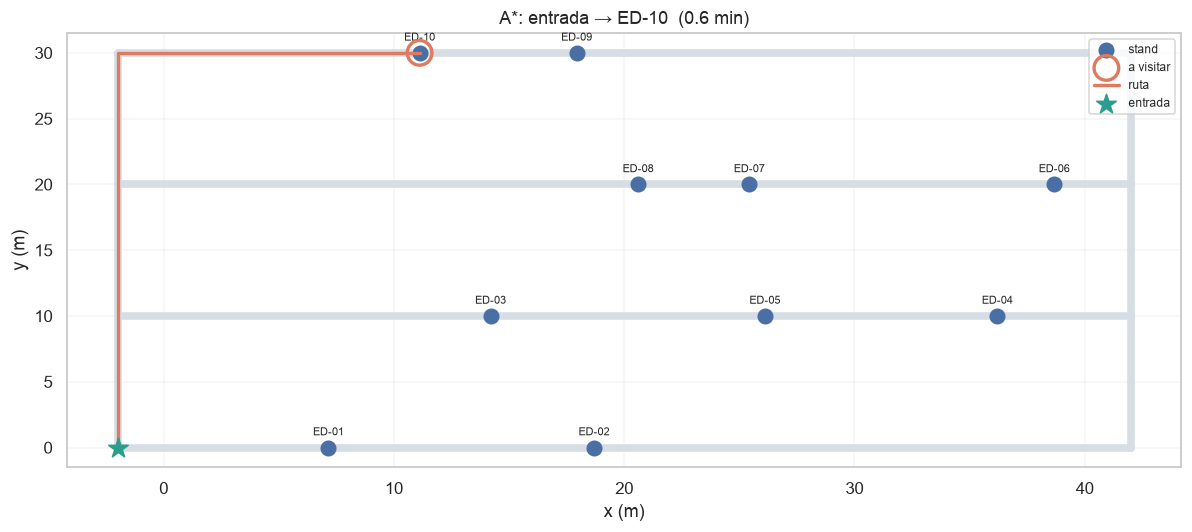

In [50]:
# Dibujar el plano y la ruta
def dibujar_feria(ax, ruta=None, destacados=None, titulo=""):
    for u in GRAFO:
        for v in GRAFO[u]:
            if u < v:
                ax.plot(*zip(POS[u], POS[v]), c="#d7dde5", lw=5, zorder=1,
                        solid_capstyle="round")
    es_stand = lambda n: not n.startswith("cruce_")
    sx = [POS[n][0] for n in POS if es_stand(n)]
    sy = [POS[n][1] for n in POS if es_stand(n)]
    ax.scatter(sx, sy, s=90, c="#4a6fa5", zorder=3, label="stand")
    for n in POS:
        if es_stand(n):
            ax.annotate(n, POS[n], fontsize=7, xytext=(0, 8),
                        textcoords="offset points", ha="center")
    if destacados:
        ax.scatter([POS[n][0] for n in destacados], [POS[n][1] for n in destacados],
                   s=260, facecolors="none", edgecolors="#e07a5f", lw=2.2, zorder=4,
                   label="a visitar")
    if ruta:
        ax.plot([POS[n][0] for n in ruta], [POS[n][1] for n in ruta],
                c="#e07a5f", lw=2.2, zorder=5, label="ruta")
    ax.scatter(*POS[ENTRADA], s=180, marker="*", c="#2a9d8f", zorder=6, label="entrada")
    for p, y in PASILLO_Y.items():
        ax.annotate(p, (-5, y), fontsize=11, weight="bold", va="center")
    ax.set(title=titulo, xlabel="x (m)", ylabel="y (m)")
    ax.legend(loc="upper right", fontsize=8); ax.grid(alpha=.2)

fig, ax = plt.subplots(figsize=(11, 5))
dibujar_feria(ax, ruta=camino, destacados=["ED-10"],
              titulo=f"A*: entrada → ED-10  ({costo/60:.1f} min)")
plt.tight_layout(); plt.show()

---

## 15. Qué visitar: por qué **no** es un TSP

### 15.1 La distinción que decide todo

NB-03 entregó 20 stands con un puntaje de afinidad. El asistente tiene 180 minutos. Lo
que hay que resolver es:

> Elegir un **subconjunto** de stands y un **orden** que **maximice el interés total**,
> sin pasarse del tiempo disponible.

Compara eso con el TSP del §7.3 de la Parte I:

| | TSP (lo que hiciste en §7.3) | Lo que necesita la feria |
|---|---|---|
| ¿Hay que visitar todos? | **Sí**, obligatorio | **No**: eliges cuáles |
| ¿Qué se optimiza? | **minimizar** distancia | **maximizar** interés |
| ¿El tiempo? | es el objetivo | es una **restricción** |
| ¿Todos los nodos valen igual? | sí | **no**: cada uno tiene un premio |

Es otro problema. Se llama **Orienteering Problem** (o *TSP con premios*, o *Selective
TSP*), y viene del deporte de orientación: llegas a puestos de control, cada uno vale
puntos, y hay un tiempo límite.

$$\max \sum_{i \in S} p_i \quad\text{sujeto a}\quad \text{tiempo}(\text{ruta sobre } S) \le T$$

> **Si en tu informe dices "modelamos el recorrido como un TSP", te van a corregir.**
> Decir "es un Orienteering Problem, que es un TSP con premios y presupuesto" demuestra
> que entendiste el problema, no solo que reconociste la palabra. Es un caso de
> **NP-difícil** que generaliza simultáneamente el TSP y el problema de la mochila:
> la mochila decide *qué llevar*, el TSP decide *en qué orden*, y aquí hay que hacer
> las dos cosas a la vez.

### 15.2 Primero, la reducción: del plano a una matriz de distancias

Trabajar sobre los 18 nodos del plano cada vez que se evalúa un orden sería carísimo.
El paso estándar es precalcular la **clausura métrica**: la matriz de tiempos mínimos
entre los stands que nos interesan, usando A*. Después, el problema vive solo sobre esa
matriz y el plano desaparece.

Esto es **abstracción de estados**, y es la misma idea que las heurísticas del 8-puzzle
de §6: resolver un problema relajado para alimentar el problema real.

In [51]:
def matriz_tiempos(nodos: list[str]) -> np.ndarray:
    """Tiempos mínimos entre cada par, vía A*. La clausura métrica del plano."""
    n = len(nodos)
    D = np.zeros((n, n))
    for i, u in enumerate(nodos):
        for j, v in enumerate(nodos):
            if i < j:
                _, c, _ = a_estrella(GRAFO, POS, u, v)
                D[i, j] = D[j, i] = c
    return D


# --- El premio de cada stand sale de NB-03: afinidad con los gustos del asistente ---
# OJO con la elección de la instancia: si el presupuesto de tiempo alcanza para
# visitar TODOS los stands, el problema de selección desaparece y cualquier
# estrategia (incluso la peor) obtiene el 100 % del óptimo. Eso no demuestra
# nada. Elegimos a propósito un asistente con poco tiempo, para que la
# restricción MUERDA. Elegir bien la instancia de prueba es parte del método:
# una instancia trivial hace parecer bueno a cualquier algoritmo.
_cands = FERIA["asistentes"]
_cands = _cands[(_cands["minutos_disponibles"] <= 120) &
                (_cands["gustos"].map(len) >= 3)]
asistente = _cands.iloc[0]
gustos = set(asistente["gustos"])
gustos_gen = {GENERAL_DE[g] for g in gustos if g in GENERAL_DE}

obras = FERIA["obras"]
obras_esp = obras["tags"].map(lambda ts: {t["especifico"] for t in ts})
obras_gen = obras["tags"].map(lambda ts: {t["general"] for t in ts})
# mismo puntaje que el pipeline de MongoDB en NB-02 §16: 3·específicas + 1·generales
obras_pts = 3 * obras_esp.map(lambda s: len(s & gustos)) + obras_gen.map(lambda s: len(s & gustos_gen))
premio_stand = (obras.assign(p=obras_pts).groupby("stand_id")["p"].sum()
                .reindex(FERIA["stands"]["_id"], fill_value=0))

# Tiempo de permanencia: proporcional al interés, con un piso. Decisión de modelado.
minutos_visita = (4 + 0.25 * premio_stand).round().clip(5, 20)

STANDS = list(FERIA["stands"]["_id"])
NODOS = [ENTRADA] + STANDS
D = matriz_tiempos(NODOS) / 60.0                      # a MINUTOS: misma unidad que todo
idx_de = {n: i for i, n in enumerate(NODOS)}

panel = pd.DataFrame({
    "stand": STANDS,
    "nombre": FERIA["stands"]["nombre"].to_numpy(),
    "pasillo": FERIA["stands"]["pasillo"].to_numpy(),
    "premio": premio_stand.to_numpy(),
    "min_visita": minutos_visita.to_numpy(),
    "min_desde_entrada": [D[0, idx_de[s]].round(1) for s in STANDS]})
print(f"Asistente {asistente['_id']} | gustos: {sorted(gustos)} | "
      f"dispone de {asistente['minutos_disponibles']} min\n")
display(panel.sort_values("premio", ascending=False))

Asistente AS-0000 | gustos: ['diseno', 'ensayo', 'fantasia', 'juvenil', 'programacion'] | dispone de 90 min



,stand,nombre,pasillo,premio,min_visita,min_desde_entrada
8,ED-09,Andes Datos,D,267,20.0,0.7
5,ED-06,Tecnos,C,255,20.0,0.8
2,ED-03,Lumen Chica,B,211,20.0,0.4
6,ED-07,Zig-Zag Hoy,C,202,20.0,0.7
7,ED-08,La Pólvora,C,186,20.0,0.6
3,ED-04,Nébula,B,166,20.0,0.7
4,ED-05,Cuarto Mundo,B,160,20.0,0.5
9,ED-10,Mapocho,D,146,20.0,0.6
0,ED-01,Austral,A,142,20.0,0.1
1,ED-02,Pehuén,A,128,20.0,0.3


### 15.3 Tres estrategias, y una forma de saber cuál sirve

1. **Voraz por premio**: ir al stand de mayor premio que quepa. Ignora dónde está.
2. **Voraz por ratio**: ir al que maximice $\dfrac{\text{premio}}{\text{tiempo de llegar} +
   \text{tiempo de visita}}$. La heurística del problema de la mochila, aplicada aquí.
3. **Búsqueda local**: partir de una solución voraz y mejorarla con movimientos
   (intercambiar, insertar, quitar), aceptando empeoramientos con *simulated annealing*
   para no quedarse en un máximo local (§7.3 de la Parte I).

Y lo que hace que esto sea ingeniería y no adivinanza: con 10 stands se puede calcular
el **óptimo exacto** por fuerza bruta, y medir qué tan lejos queda cada heurística.

In [52]:
TIEMPO_DISPONIBLE = float(asistente["minutos_disponibles"])
PREMIO = {s: float(premio_stand[s]) for s in STANDS}
VISITA = {s: float(minutos_visita[s]) for s in STANDS}

def tiempo_ruta(ruta: list[str], volver=True) -> float:
    """Minutos totales: caminar + permanecer. Opcionalmente volver a la entrada."""
    if not ruta: return 0.0
    t = D[0, idx_de[ruta[0]]]
    for u, v in zip(ruta, ruta[1:]):
        t += D[idx_de[u], idx_de[v]]
    t += sum(VISITA[s] for s in ruta)
    if volver: t += D[idx_de[ruta[-1]], 0]
    return t

def premio_ruta(ruta): return sum(PREMIO[s] for s in ruta)
def factible(ruta, T=TIEMPO_DISPONIBLE): return tiempo_ruta(ruta) <= T + 1e-9


def voraz(clave, T=TIEMPO_DISPONIBLE):
    """clave(stand, actual) -> qué tan deseable. Construye la ruta paso a paso."""
    ruta, restantes, actual = [], set(STANDS), ENTRADA
    while restantes:
        viables = [s for s in restantes if factible(ruta + [s], T)]
        if not viables: break
        elegido = max(viables, key=lambda s: clave(s, actual))
        ruta.append(elegido); restantes.discard(elegido); actual = elegido
    return ruta

voraz_premio = voraz(lambda s, a: PREMIO[s])
voraz_ratio = voraz(lambda s, a: PREMIO[s] / max(D[idx_de[a], idx_de[s]] + VISITA[s], 1e-9))

for nombre, r in [("voraz por premio", voraz_premio), ("voraz por ratio", voraz_ratio)]:
    print(f"{nombre:18} premio={premio_ruta(r):5.0f}  tiempo={tiempo_ruta(r):6.1f}/{TIEMPO_DISPONIBLE:.0f} min"
          f"  ({len(r)} stands)")
    print(f"{'':18} {' → '.join(r)}")

voraz por premio   premio=  935  tiempo=  83.2/90 min  (4 stands)
                   ED-09 → ED-06 → ED-03 → ED-07
voraz por ratio    premio=  935  tiempo=  83.2/90 min  (4 stands)
                   ED-09 → ED-06 → ED-03 → ED-07


In [53]:
# --- El óptimo EXACTO por fuerza bruta: solo posible porque hay 10 stands ---
def optimo_exacto(T=TIEMPO_DISPONIBLE):
    """Enumera los subconjuntos ORDENADOS POR PREMIO DESCENDENTE.

    El premio no depende del orden de visita (sin ventanas de tiempo), así que
    el primer subconjunto que resulte factible en ALGÚN orden es ya el óptimo:
    se puede cortar ahí. Sin ese orden previo habría que probarlos todos.
    """
    subs = sorted(((sum(PREMIO[s] for s in sub), sub)
                   for k in range(1, len(STANDS) + 1)
                   for sub in itertools.combinations(STANDS, k)),
                  key=lambda t: -t[0])
    for p, sub in subs:
        for orden in itertools.permutations(sub):
            if factible(list(orden), T):
                return list(orden), p
    return [], 0.0

t0 = time.perf_counter()
opt, opt_p = optimo_exacto()
t_opt = time.perf_counter() - t0

print(f"ÓPTIMO EXACTO  premio={opt_p:.0f}  tiempo={tiempo_ruta(opt):.1f} min  "
      f"({len(opt)} stands)  [calculado en {t_opt:.1f} s]")
print(f"   {' → '.join(opt)}\n")
comp = pd.DataFrame([
    {"estrategia": n, "premio": premio_ruta(r), "stands": len(r),
     "tiempo (min)": round(tiempo_ruta(r), 1),
     "% del óptimo": f"{premio_ruta(r) / opt_p:.1%}"}
    for n, r in [("voraz por premio", voraz_premio), ("voraz por ratio", voraz_ratio),
                 ("óptimo exacto", opt)]])
display(comp)
tot10 = sum(math.perm(len(STANDS), k) for k in range(1, len(STANDS) + 1))
tot20 = sum(math.perm(20, k) for k in range(1, 21))
print(f"""
  RESULTADO HONESTO: las dos heurísticas voraces alcanzan el 100 % del óptimo.
  No es que sean geniales: es que la instancia es CHICA. Con {len(STANDS)} stands y un
  presupuesto que solo deja entrar {len(opt)}, hay pocas combinaciones razonables y
  cualquier estrategia sensata cae en la mejor.

  La conclusión correcta para tu informe NO es "nuestra heurística es óptima".
  Es: "a la escala de nuestra feria ({len(STANDS)} stands), una heurística voraz alcanza
  el óptimo exacto, de modo que no se justifica un metaheurístico". Eso es una
  decisión de ingeniería defendible. En §15.4 vemos a partir de qué tamaño deja
  de ser cierto.

  ⚠ Y por qué la fuerza bruta no escala: con {len(STANDS)} stands son
  Σ C(n,k)·k! ≈ {tot10:,} órdenes posibles (resueltos en {t_opt:.1f} s gracias a la poda).
  Con 20 stands serían ≈ {tot20:.1e}, unas {tot20 / tot10:.0e} veces más.""")

ÓPTIMO EXACTO  premio=935  tiempo=82.5 min  (4 stands)  [calculado en 29.1 s]
   ED-03 → ED-06 → ED-07 → ED-09



,estrategia,premio,stands,tiempo (min),% del óptimo
0,voraz por premio,935.0,4,83.2,100.0%
1,voraz por ratio,935.0,4,83.2,100.0%
2,óptimo exacto,935.0,4,82.5,100.0%



  RESULTADO HONESTO: las dos heurísticas voraces alcanzan el 100 % del óptimo.
  No es que sean geniales: es que la instancia es CHICA. Con 10 stands y un
  presupuesto que solo deja entrar 4, hay pocas combinaciones razonables y
  cualquier estrategia sensata cae en la mejor.

  La conclusión correcta para tu informe NO es "nuestra heurística es óptima".
  Es: "a la escala de nuestra feria (10 stands), una heurística voraz alcanza
  el óptimo exacto, de modo que no se justifica un metaheurístico". Eso es una
  decisión de ingeniería defendible. En §15.4 vemos a partir de qué tamaño deja
  de ser cierto.

  ⚠ Y por qué la fuerza bruta no escala: con 10 stands son
  Σ C(n,k)·k! ≈ 9,864,100 órdenes posibles (resueltos en 29.1 s gracias a la poda).
  Con 20 stands serían ≈ 6.6e+18, unas 7e+11 veces más.


SA desde la solución voraz: premio=935  tiempo=83.2 min
   ED-09 → ED-06 → ED-03 → ED-07
   100.0% del óptimo

SA desde cero             : premio=821  (87.8% del óptimo)


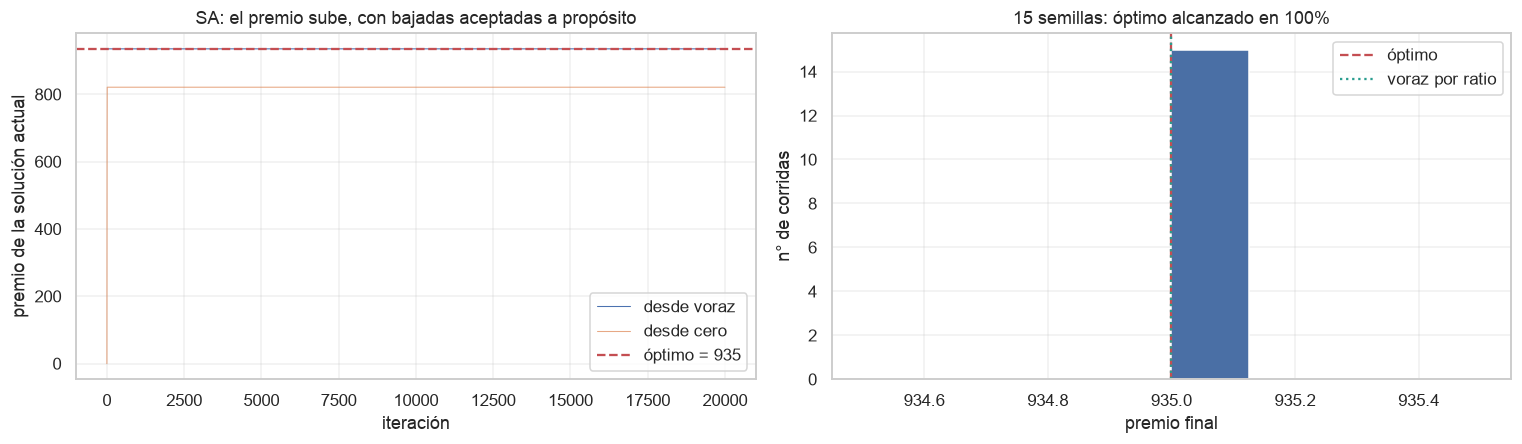


  Lo que hay que reportar, y casi nadie reporta: el histograma. Una heurística
  estocástica no tiene UN resultado, tiene una DISTRIBUCIÓN. Decir "nuestro
  algoritmo encontró el óptimo" tras una corrida afortunada es un error de
  método. Lo correcto es "alcanza el óptimo en el X % de 15 corridas".


In [54]:
# --- Búsqueda local con simulated annealing sobre el itinerario (§7.3 Parte I) ---
def sa_itinerario(ruta0, T_total=TIEMPO_DISPONIBLE, iters=20_000,
                  T0=2.0, T_end=0.01, seed=0):
    """Tres movimientos: AGREGAR un stand, QUITAR uno, INTERCAMBIAR posiciones.

    Agregar es el que sube el premio; quitar es el que libera tiempo para que
    agregar vuelva a ser posible. Sin 'quitar', el vecindario se cierra en
    cuanto la ruta se llena y la búsqueda se congela.
    """
    rng = np.random.default_rng(seed)
    actual = list(ruta0); p_actual = premio_ruta(actual)
    mejor, p_mejor = list(actual), p_actual
    hist = []
    for it in range(iters):
        T = T0 * (T_end / T0) ** (it / iters)             # enfriamiento geométrico
        fuera = [s for s in STANDS if s not in actual]
        mov = rng.random()
        cand = list(actual)
        if mov < 0.45 and fuera:                          # AGREGAR en posición al azar
            cand.insert(int(rng.integers(0, len(cand) + 1)), str(rng.choice(fuera)))
        elif mov < 0.65 and len(cand) > 1:                # QUITAR
            cand.pop(int(rng.integers(0, len(cand))))
        elif len(cand) > 1:                               # INTERCAMBIAR dos posiciones
            i, j = rng.integers(0, len(cand), 2)
            cand[i], cand[j] = cand[j], cand[i]
        if not factible(cand, T_total):
            hist.append(p_actual); continue
        p_cand = premio_ruta(cand)
        delta = p_cand - p_actual                          # MAXIMIZAMOS: delta>0 es mejor
        if delta >= 0 or rng.random() < math.exp(delta / max(T, 1e-12)):
            actual, p_actual = cand, p_cand
            if p_actual > p_mejor:
                mejor, p_mejor = list(actual), p_actual
        hist.append(p_actual)
    return mejor, p_mejor, hist

sa_ruta, sa_p, hist = sa_itinerario(voraz_ratio)
print(f"SA desde la solución voraz: premio={sa_p:.0f}  tiempo={tiempo_ruta(sa_ruta):.1f} min")
print(f"   {' → '.join(sa_ruta)}")
print(f"   {sa_p / opt_p:.1%} del óptimo")

# ¿Importa el punto de partida? Comparación contra arranque vacío.
sa_vacio, sa_pv, hist_v = sa_itinerario([], seed=1)
print(f"\nSA desde cero             : premio={sa_pv:.0f}  ({sa_pv / opt_p:.1%} del óptimo)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(hist, lw=.7, label="desde voraz")
axes[0].plot(hist_v, lw=.7, alpha=.7, label="desde cero")
axes[0].axhline(opt_p, c="r", ls="--", label=f"óptimo = {opt_p:.0f}")
axes[0].set(xlabel="iteración", ylabel="premio de la solución actual",
            title="SA: el premio sube, con bajadas aceptadas a propósito")
axes[0].legend(); axes[0].grid(alpha=.3)

# Consistencia: ¿depende de la semilla? Una corrida afortunada no es un resultado.
premios = [sa_itinerario(voraz_ratio, seed=s)[1] for s in range(15)]
axes[1].hist(premios, bins=8, color="#4a6fa5", edgecolor="white")
axes[1].axvline(opt_p, c="r", ls="--", label="óptimo")
axes[1].axvline(premio_ruta(voraz_ratio), c="#2a9d8f", ls=":", label="voraz por ratio")
axes[1].set(xlabel="premio final", ylabel="n° de corridas",
            title=f"15 semillas: óptimo alcanzado en {np.mean(np.array(premios) >= opt_p - 1e-9):.0%}")
axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("""
  Lo que hay que reportar, y casi nadie reporta: el histograma. Una heurística
  estocástica no tiene UN resultado, tiene una DISTRIBUCIÓN. Decir "nuestro
  algoritmo encontró el óptimo" tras una corrida afortunada es un error de
  método. Lo correcto es "alcanza el óptimo en el X % de 15 corridas".""")

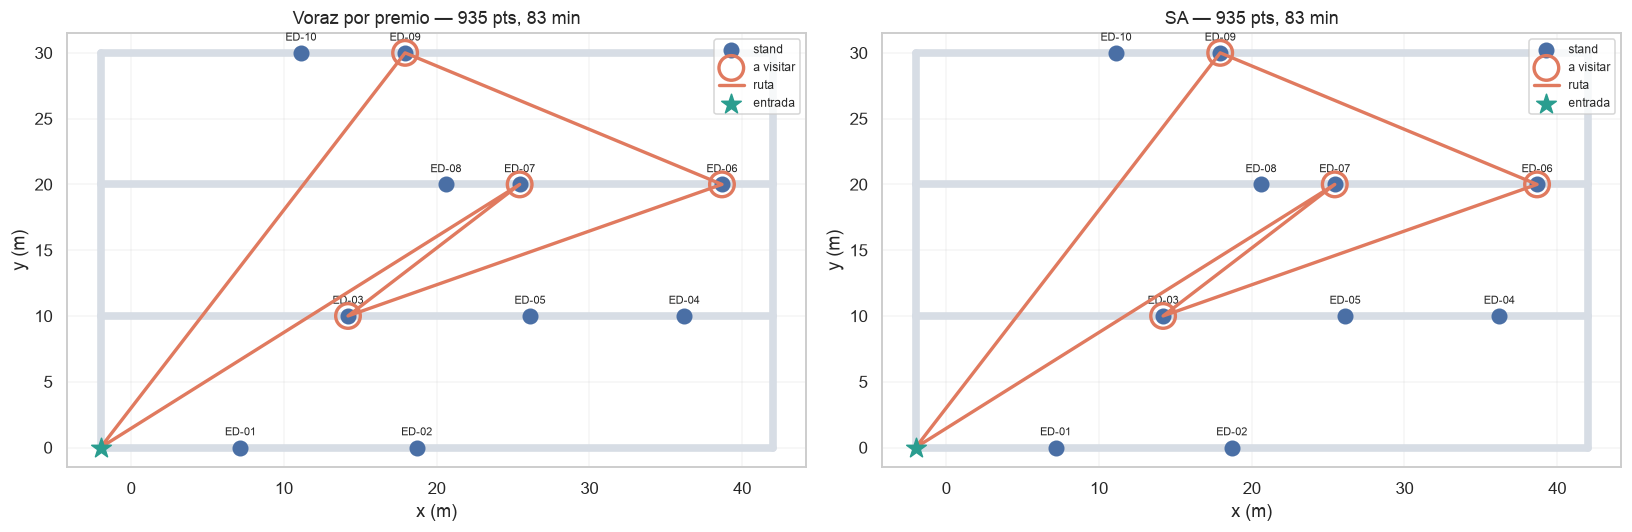

  Reparto del tiempo (caminar vs. permanecer en el stand):
    voraz por premio:   3.2 min caminando +  80.0 min en stands
    SA              :   3.2 min caminando +  80.0 min en stands

  Ahí está la métrica que de verdad distingue dos itinerarios con el mismo
  premio: cuánto tiempo se va CAMINANDO. Caminar no da puntos; es puro costo.
  Una ruta que visita los mismos stands pero camina 0.0 min menos deja
  ese tiempo libre para un stand más — y esa holgura es la que explota SA
  cuando la instancia es lo bastante grande para que haya algo que explotar.


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dibujar_feria(axes[0], ruta=[ENTRADA] + voraz_premio + [ENTRADA], destacados=voraz_premio,
              titulo=f"Voraz por premio — {premio_ruta(voraz_premio):.0f} pts, "
                     f"{tiempo_ruta(voraz_premio):.0f} min")
dibujar_feria(axes[1], ruta=[ENTRADA] + sa_ruta + [ENTRADA], destacados=sa_ruta,
              titulo=f"SA — {sa_p:.0f} pts, {tiempo_ruta(sa_ruta):.0f} min")
plt.tight_layout(); plt.show()

cam_v = tiempo_ruta(voraz_premio) - sum(VISITA[s] for s in voraz_premio)
cam_s = tiempo_ruta(sa_ruta) - sum(VISITA[s] for s in sa_ruta)
print(f"  Reparto del tiempo (caminar vs. permanecer en el stand):")
print(f"    voraz por premio: {cam_v:5.1f} min caminando + "
      f"{sum(VISITA[s] for s in voraz_premio):5.1f} min en stands")
print(f"    SA              : {cam_s:5.1f} min caminando + "
      f"{sum(VISITA[s] for s in sa_ruta):5.1f} min en stands")
print(f"""
  Ahí está la métrica que de verdad distingue dos itinerarios con el mismo
  premio: cuánto tiempo se va CAMINANDO. Caminar no da puntos; es puro costo.
  Una ruta que visita los mismos stands pero camina {abs(cam_v - cam_s):.1f} min menos deja
  ese tiempo libre para un stand más — y esa holgura es la que explota SA
  cuando la instancia es lo bastante grande para que haya algo que explotar.""")

### 15.4 ¿A partir de qué tamaño hace falta la búsqueda local?

La sección anterior dejó un resultado incómodo: con 10 stands, una heurística voraz de
tres líneas alcanza el óptimo exacto. Entonces, **¿para qué sirve el *simulated
annealing*?**

La respuesta es: para instancias en las que la voraz **no** alcanza el óptimo. Y la
pregunta de ingeniería —la que vale puntos en una defensa— es *dónde está esa
frontera*. No se contesta opinando: se contesta midiendo.

Vamos a generar ferias sintéticas de tamaño creciente (20, 40, 80 stands), donde la
fuerza bruta ya es imposible, y comparar voraz contra SA. Como no tendremos el óptimo,
usaremos como referencia **la mejor solución encontrada por cualquier método**, que es
exactamente lo que se hace en la literatura cuando el óptimo es inalcanzable.

In [56]:
def feria_sintetica(n_stands, seed=0, n_pasillos=6, largo=60.0):
    """Una feria más grande, con la misma estructura de pasillos."""
    rg = np.random.default_rng(seed)
    ys = {chr(65 + i): 10.0 * i for i in range(n_pasillos)}
    st = pd.DataFrame([{"_id": f"S-{i:03d}", "pasillo": chr(65 + i % n_pasillos),
                        "x": float(rg.uniform(0, largo)),
                        "y": ys[chr(65 + i % n_pasillos)]} for i in range(n_stands)])
    g, pos = {}, {}
    X_I, X_D = -2.0, largo + 2
    for p, y in ys.items():
        pos[f"c_{p}_i"] = (X_I, y); pos[f"c_{p}_d"] = (X_D, y)
    for _, s in st.iterrows():
        pos[s["_id"]] = (s["x"], s["y"])
    def ar(u, v):
        d = (abs(pos[u][0] - pos[v][0]) + abs(pos[u][1] - pos[v][1])) / VELOCIDAD
        g.setdefault(u, {})[v] = d; g.setdefault(v, {})[u] = d
    for p, y in ys.items():
        fila = sorted([n for n, (_, yy) in pos.items() if yy == y], key=lambda n: pos[n][0])
        for u, v in zip(fila, fila[1:]): ar(u, v)
    orden = sorted(ys, key=lambda p: ys[p])
    for p, q in zip(orden, orden[1:]):
        ar(f"c_{p}_i", f"c_{q}_i"); ar(f"c_{p}_d", f"c_{q}_d")
    premios = {s: float(rg.gamma(2.0, 30.0)) for s in st["_id"]}
    visitas = {s: float(rg.choice([5, 8, 10, 12, 15])) for s in st["_id"]}
    return g, pos, list(st["_id"]), premios, visitas, f"c_{orden[0]}_i"


def resolver(g, pos, stands, premios, visitas, entrada, T, semillas=8):
    """Devuelve (premio_voraz, mejor_premio_SA, premios_SA, segundos)."""
    nodos = [entrada] + stands
    idx = {n: i for i, n in enumerate(nodos)}
    n = len(nodos)
    Dm = np.zeros((n, n))
    for i, u in enumerate(nodos):                    # Dijkstra desde cada nodo: O(n·E log V)
        dist = {u: 0.0}; pq = [(0.0, u)]
        while pq:
            d0, x = heapq.heappop(pq)
            if d0 > dist.get(x, math.inf): continue
            for y, c in g[x].items():
                if d0 + c < dist.get(y, math.inf):
                    dist[y] = d0 + c; heapq.heappush(pq, (d0 + c, y))
        for j, v in enumerate(nodos): Dm[i, j] = dist.get(v, math.inf)
    Dm /= 60.0

    t_ruta = lambda r: (Dm[0, idx[r[0]]] + sum(Dm[idx[a], idx[b]] for a, b in zip(r, r[1:]))
                        + sum(visitas[s] for s in r) + Dm[idx[r[-1]], 0]) if r else 0.0
    p_ruta = lambda r: sum(premios[s] for s in r)
    fact = lambda r: t_ruta(r) <= T + 1e-9

    # voraz por ratio
    ruta, restantes, actual = [], set(stands), entrada
    while restantes:
        viables = [s for s in restantes if fact(ruta + [s])]
        if not viables: break
        e = max(viables, key=lambda s: premios[s] / max(Dm[idx[actual], idx[s]] + visitas[s], 1e-9))
        ruta.append(e); restantes.discard(e); actual = e
    p_voraz = p_ruta(ruta)

    t0 = time.perf_counter(); resultados = []
    for sd in range(semillas):
        rg = np.random.default_rng(sd)
        act = list(ruta); pa = p_voraz; mp = pa
        for it in range(25_000):
            Temp = 3.0 * (0.01 / 3.0) ** (it / 25_000)
            fuera = [s for s in stands if s not in act]
            cand = list(act); r = rg.random()
            if r < 0.45 and fuera:
                cand.insert(int(rg.integers(0, len(cand) + 1)), str(rg.choice(fuera)))
            elif r < 0.65 and len(cand) > 1: cand.pop(int(rg.integers(0, len(cand))))
            elif len(cand) > 1:
                i2, j2 = rg.integers(0, len(cand), 2); cand[i2], cand[j2] = cand[j2], cand[i2]
            if not cand or not fact(cand): continue
            pc = p_ruta(cand); d = pc - pa
            if d >= 0 or rg.random() < math.exp(d / max(Temp, 1e-12)):
                act, pa = cand, pc; mp = max(mp, pa)
        resultados.append(mp)
    return p_voraz, max(resultados), resultados, time.perf_counter() - t0


filas = []
for n_st, T in [(10, 90), (20, 120), (40, 150), (80, 180)]:
    g2, pos2, st2, pr2, vi2, ent2 = feria_sintetica(n_st, seed=7)
    pv, psa, todos, segs = resolver(g2, pos2, st2, pr2, vi2, ent2, T)
    filas.append({"stands": n_st, "presupuesto (min)": T,
                  "voraz por ratio": round(pv, 1), "mejor SA": round(psa, 1),
                  "mejora de SA": f"{psa / pv - 1:+.1%}",
                  "SA (media de 8)": round(float(np.mean(todos)), 1),
                  "seg.": round(segs, 1)})
display(pd.DataFrame(filas))
print("""
  Así se lee esta tabla, que es la que responde "¿necesitamos SA?":

  · Con pocos stands la mejora de SA es nula o mínima: la voraz ya exprime casi
    todo lo que hay. Implementar un metaheurístico ahí es complejidad gratis.
  · A medida que crece el número de stands, crece el número de combinaciones
    que la voraz no explora, y la mejora de SA se vuelve real.
  · Mira también la columna de segundos: SA cuesta tiempo de cómputo. Si tu
    sistema tiene que responder mientras el asistente espera en la entrada,
    ese costo es parte de la decisión, no un detalle.

  Para tu informe: corre esta tabla con EL TAMAÑO DE TU FERIA y decide con el
  número delante. "Elegimos una heurística voraz porque con nuestros N stands
  SA no mejora el resultado y responde en 2 ms" es una frase que se defiende
  sola. "Usamos simulated annealing porque es más avanzado" no.""")

,stands,presupuesto (min),voraz por ratio,mejor SA,mejora de SA,SA (media de 8),seg.
0,10,90,350.1,350.1,+0.0%,350.1,3.4
1,20,120,843.5,843.5,+0.0%,843.5,2.2
2,40,150,1542.4,1559.1,+1.1%,1545.2,3.3
3,80,180,1980.6,2019.9,+2.0%,1994.0,5.5



  Así se lee esta tabla, que es la que responde "¿necesitamos SA?":

  · Con pocos stands la mejora de SA es nula o mínima: la voraz ya exprime casi
    todo lo que hay. Implementar un metaheurístico ahí es complejidad gratis.
  · A medida que crece el número de stands, crece el número de combinaciones
    que la voraz no explora, y la mejora de SA se vuelve real.
  · Mira también la columna de segundos: SA cuesta tiempo de cómputo. Si tu
    sistema tiene que responder mientras el asistente espera en la entrada,
    ese costo es parte de la decisión, no un detalle.

  Para tu informe: corre esta tabla con EL TAMAÑO DE TU FERIA y decide con el
  número delante. "Elegimos una heurística voraz porque con nuestros N stands
  SA no mejora el resultado y responde en 2 ms" es una frase que se defiende
  sola. "Usamos simulated annealing porque es más avanzado" no.


---

## 16. Charlas con horario: ventanas de tiempo

### 16.1 Lo que cambia cuando aparece un horario

Hasta aquí un stand se podía visitar en cualquier momento. Una **charla**, no: empieza
a las 11:30 y se acabó. Eso parte el problema en dos:

| | Stand | Charla |
|---|---|---|
| Disponibilidad | todo el día | ventana $[\text{inicio}, \text{fin}]$ |
| Si llegas tarde | da igual | **la perdiste** |
| Si llegas temprano | entras | **esperas** (y gastas tiempo) |

El estado deja de ser "dónde estoy" y pasa a ser **"dónde estoy *y a qué hora*"**.

> **Esto es lo que más se equivoca al modelar.** Si tu estado no incluye el tiempo, no
> puedes representar "llegué a las 11:45 y la charla era 11:30" — y entonces tu
> algoritmo produce itinerarios que en la feria real no se pueden ejecutar.

Las consecuencias técnicas son dos, y conviene nombrarlas:

1. **El orden deja de ser libre.** Sin ventanas, cualquier permutación de un conjunto
   factible sigue siendo factible (por eso en `optimo_exacto` podía cortar en el primer
   orden que cupiera). Con ventanas, **el orden decide la factibilidad**, y esa poda
   deja de ser válida.
2. **Aparece el tiempo de espera**, que no es tiempo caminando ni visitando: es tiempo
   perdido que igual consume el presupuesto. Una buena solución a veces **prefiere un
   camino más largo** si eso evita esperar.

In [57]:
HORA_APERTURA = 10 * 60          # la feria abre a las 10:00; los minutos son absolutos

charlas = FERIA["charlas"].copy()
charlas["inicio_abs"] = HORA_APERTURA + charlas["inicio_min"]
charlas["fin_abs"] = HORA_APERTURA + charlas["fin_min"]
# el premio de una charla: el del stand que la da, con un bono por ser evento único
charlas["premio"] = charlas["stand_id"].map(PREMIO) * 1.5

def hhmm(m): return f"{int(m) // 60:02d}:{int(m) % 60:02d}"

print("Charlas con premio > 0 para este asistente:")
vista = charlas[charlas["premio"] > 0].sort_values("inicio_abs")
display(vista.assign(horario=vista.apply(lambda r: f"{hhmm(r.inicio_abs)}–{hhmm(r.fin_abs)}", axis=1))
        [["_id", "stand_id", "escenario", "horario", "duracion_min", "premio"]].head(8))


def simular_itinerario(plan: list[tuple], inicio_abs=HORA_APERTURA):
    """Ejecuta un plan y devuelve (bitácora, factible, premio, hora_fin).

    plan: lista de (tipo, id) con tipo ∈ {'stand', 'charla'}.
    Esta función es el CONTRATO del problema: decide qué es ejecutable y qué no.
    Escribirla ANTES que el optimizador es lo que evita optimizar una fantasía.
    """
    t, pos_actual, bitacora, premio, ok = inicio_abs, ENTRADA, [], 0.0, True
    for tipo, ident in plan:
        destino = ident if tipo == "stand" else charlas.set_index("_id").loc[ident, "stand_id"]
        viaje = D[idx_de[pos_actual], idx_de[destino]]
        t_llegada = t + viaje
        if tipo == "stand":
            dur, espera, perdida = VISITA[destino], 0.0, False
            p = PREMIO[destino]
        else:
            ch = charlas.set_index("_id").loc[ident]
            espera = max(0.0, ch["inicio_abs"] - t_llegada)
            perdida = t_llegada > ch["inicio_abs"] + 1e-9        # llegó tarde: la perdió
            dur = ch["duracion_min"]
            p = 0.0 if perdida else ch["premio"]
            if perdida: ok = False
        bitacora.append({"tipo": tipo, "id": ident, "destino": destino,
                         "llega": hhmm(t_llegada), "espera_min": round(espera, 1),
                         "dur_min": dur, "sale": hhmm(t_llegada + espera + dur),
                         "premio": p, "perdida": perdida})
        t = t_llegada + espera + dur
        pos_actual = destino
        premio += p
    return pd.DataFrame(bitacora), ok, premio, t


# Un plan que NO funciona: la charla queda fuera de alcance
ch_objetivo = vista.iloc[2]["_id"]
plan_malo = [("stand", "ED-10"), ("stand", "ED-02"), ("charla", ch_objetivo)]
bit, ok, p, fin = simular_itinerario(plan_malo)
print(f"\nPlan ingenuo — ¿ejecutable? {ok} | premio {p:.0f} | termina {hhmm(fin)}")
display(bit)

Charlas con premio > 0 para este asistente:


,_id,stand_id,escenario,horario,duracion_min,premio
21,CH-021,ED-05,E1,10:00–11:00,60,240.0
20,CH-020,ED-09,E3,10:00–11:00,60,400.5
1,CH-001,ED-06,E3,11:00–11:30,30,382.5
18,CH-018,ED-09,E2,11:00–12:00,60,400.5
16,CH-016,ED-06,E2,11:00–12:00,60,382.5
2,CH-002,ED-09,E3,11:30–12:15,45,400.5
19,CH-019,ED-01,E3,11:30–12:00,30,213.0
0,CH-000,ED-06,E1,12:30–13:30,60,382.5



Plan ingenuo — ¿ejecutable? True | premio 656 | termina 11:30


,tipo,id,destino,llega,espera_min,dur_min,sale,premio,perdida
0,stand,ED-10,ED-10,10:00,0.0,20.0,10:20,146.0,False
1,stand,ED-02,ED-02,10:21,0.0,20.0,10:41,128.0,False
2,charla,CH-001,ED-06,10:42,17.9,30.0,11:30,382.5,False


In [58]:
def planificar_con_charlas(T_total=TIEMPO_DISPONIBLE, inicio_abs=HORA_APERTURA, seed=0,
                           iters=15_000):
    """Búsqueda local sobre planes MIXTOS (stands + charlas con horario).

    Diferencia clave con sa_itinerario: aquí la factibilidad la decide el
    SIMULADOR, no una suma de tiempos. Con ventanas, el orden importa, así que
    el movimiento 'intercambiar' puede romper un plan que era válido.
    """
    rng = np.random.default_rng(seed)
    charlas_utiles = list(vista["_id"])
    limite = inicio_abs + T_total

    def evaluar(plan):
        _, ok, premio, fin = simular_itinerario(plan, inicio_abs)
        return (premio, fin) if (ok and fin <= limite) else (-1.0, fin)

    actual, (p_actual, _) = [], (0.0, inicio_abs)
    mejor, p_mejor = [], 0.0
    for it in range(iters):
        T = 2.0 * (0.01 / 2.0) ** (it / iters)
        cand = list(actual)
        r = rng.random()
        en_plan = {i for _, i in cand}
        if r < 0.40:                                           # agregar stand
            libres = [s for s in STANDS if s not in en_plan]
            if libres: cand.insert(int(rng.integers(0, len(cand) + 1)),
                                   ("stand", str(rng.choice(libres))))
        elif r < 0.65:                                         # agregar charla
            libres = [c for c in charlas_utiles if c not in en_plan]
            if libres: cand.insert(int(rng.integers(0, len(cand) + 1)),
                                   ("charla", str(rng.choice(libres))))
        elif r < 0.82 and cand:                                # quitar
            cand.pop(int(rng.integers(0, len(cand))))
        elif len(cand) > 1:                                    # reordenar
            i, j = rng.integers(0, len(cand), 2)
            cand[i], cand[j] = cand[j], cand[i]
        p_cand, _ = evaluar(cand)
        if p_cand < 0:
            continue                                           # inejecutable: se descarta
        delta = p_cand - p_actual
        if delta >= 0 or rng.random() < math.exp(delta / max(T, 1e-12)):
            actual, p_actual = cand, p_cand
            if p_actual > p_mejor:
                mejor, p_mejor = list(actual), p_actual
    return mejor, p_mejor

# Con 90 minutos, una charla de 45 min más la espera previa casi nunca compensa:
# el planificador las descartaría todas y no veríamos funcionar las ventanas de
# tiempo. Le damos una jornada completa, que es además el caso realista de quien
# va a una feria a ver charlas.
T_JORNADA = 240.0

plan, p_plan = planificar_con_charlas(T_total=T_JORNADA)
bit, ok, premio, fin = simular_itinerario(plan)
n_charlas = int((bit["tipo"] == "charla").sum()) if len(bit) else 0
espera = float(bit["espera_min"].sum()) if len(bit) else 0.0

print(f"ITINERARIO · asistente {asistente['_id']} · {sorted(gustos)}")
print(f"Entra {hhmm(HORA_APERTURA)}, dispone de {T_JORNADA:.0f} min "
      f"(hasta {hhmm(HORA_APERTURA + T_JORNADA)})")
print(f"¿Ejecutable? {ok} | premio total {premio:.0f} | termina {hhmm(fin)} "
      f"| {n_charlas} charlas | espera acumulada {espera:.0f} min\n")
display(bit)

# Control: ¿cuánto se consigue con la MISMA jornada pero sin charlas?
solo_st, p_solo, _ = sa_itinerario([], T_total=T_JORNADA, seed=0)
print(f"\nMismo presupuesto ({T_JORNADA:.0f} min), SOLO stands : premio {p_solo:.0f}")
print(f"Mismo presupuesto, stands + charlas             : premio {premio:.0f}  "
      f"({premio / max(p_solo, 1e-9) - 1:+.0%})")
print(f"""
  Lo que muestran estos números:

  · El plan incluye {n_charlas} charla(s) y acumula {espera:.0f} min de espera. Esperar no
    da puntos: es tiempo que se paga a cambio del bono ×1.5 de la charla.
    El planificador acepta ese trueque solo cuando sale a cuenta, y lo decide
    solo, porque el simulador le cobra la espera.
  · Compara con el experimento anterior: con 90 minutos NO entraba ninguna
    charla. La misma feria, el mismo asistente y el mismo algoritmo dan
    respuestas cualitativamente distintas según el presupuesto. Eso no es un
    defecto: es la señal de que el modelo está capturando la restricción real.

  La perilla que tienes que decidir TÚ es el bono de las charlas (aquí ×1.5):
  cuánto vale, en tu feria, un evento único frente a un stand que está siempre
  disponible. Súbelo y el itinerario girará en torno a los escenarios; bájalo y
  las charlas desaparecerán. No hay un valor correcto; hay uno que puedes
  justificar.""")

ITINERARIO · asistente AS-0000 · ['diseno', 'ensayo', 'fantasia', 'juvenil', 'programacion']
Entra 10:00, dispone de 240 min (hasta 14:00)
¿Ejecutable? True | premio total 1930 | termina 13:42 | 1 charlas | espera acumulada 7 min



,tipo,id,destino,llega,espera_min,dur_min,sale,premio,perdida
0,stand,ED-02,ED-02,10:00,0.0,20.0,10:20,128.0,False
1,stand,ED-09,ED-09,10:21,0.0,20.0,10:41,267.0,False
2,stand,ED-04,ED-04,10:41,0.0,20.0,11:01,166.0,False
3,stand,ED-05,ED-05,11:02,0.0,20.0,11:22,160.0,False
4,charla,CH-019,ED-01,11:22,7.2,30.0,12:00,213.0,False
5,stand,ED-01,ED-01,12:00,0.0,20.0,12:20,142.0,False
6,stand,ED-07,ED-07,12:20,0.0,20.0,12:40,202.0,False
7,stand,ED-03,ED-03,12:41,0.0,20.0,13:01,211.0,False
8,stand,ED-06,ED-06,13:02,0.0,20.0,13:22,255.0,False
9,stand,ED-08,ED-08,13:22,0.0,20.0,13:42,186.0,False



Mismo presupuesto (240 min), SOLO stands : premio 1863
Mismo presupuesto, stands + charlas             : premio 1930  (+4%)

  Lo que muestran estos números:

  · El plan incluye 1 charla(s) y acumula 7 min de espera. Esperar no
    da puntos: es tiempo que se paga a cambio del bono ×1.5 de la charla.
    El planificador acepta ese trueque solo cuando sale a cuenta, y lo decide
    solo, porque el simulador le cobra la espera.
  · Compara con el experimento anterior: con 90 minutos NO entraba ninguna
    charla. La misma feria, el mismo asistente y el mismo algoritmo dan
    respuestas cualitativamente distintas según el presupuesto. Eso no es un
    defecto: es la señal de que el modelo está capturando la restricción real.

  La perilla que tienes que decidir TÚ es el bono de las charlas (aquí ×1.5):
  cuánto vale, en tu feria, un evento único frente a un stand que está siempre
  disponible. Súbelo y el itinerario girará en torno a los escenarios; bájalo y
  las charlas desaparecerán

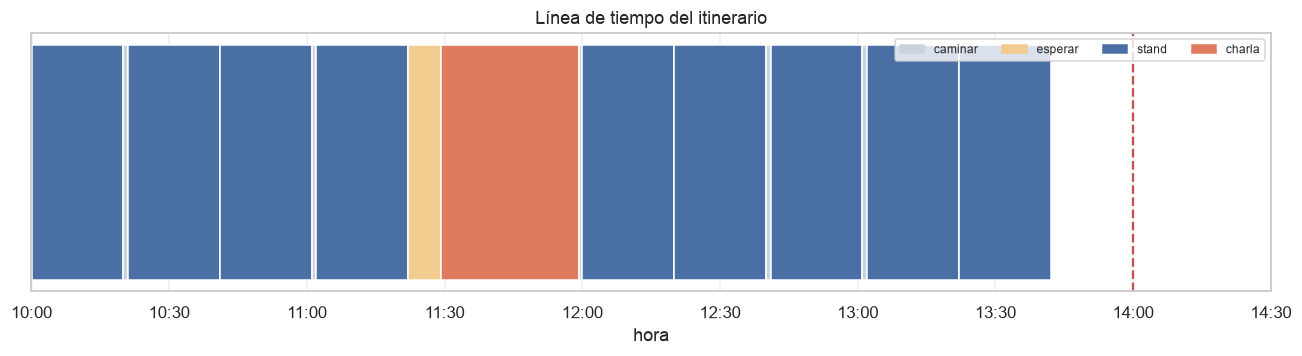

In [59]:
fig, ax = plt.subplots(figsize=(12, 3.4))
t = HORA_APERTURA
colores = {"stand": "#4a6fa5", "charla": "#e07a5f", "camina": "#c9d2dd", "espera": "#f2cc8f"}
for _, fila in bit.iterrows():
    llega = int(fila["llega"][:2]) * 60 + int(fila["llega"][3:])
    ax.barh(0, llega - t, left=t, color=colores["camina"], height=.5)       # caminata
    if fila["espera_min"] > 0:
        ax.barh(0, fila["espera_min"], left=llega, color=colores["espera"], height=.5)
    ini = llega + fila["espera_min"]
    ax.barh(0, fila["dur_min"], left=ini, color=colores[fila["tipo"]], height=.5)
    ax.annotate(fila["destino"], (ini + fila["dur_min"] / 2, .32), ha="center", fontsize=7,
                rotation=45)
    t = ini + fila["dur_min"]
ax.axvline(HORA_APERTURA + T_JORNADA, c="r", ls="--", label="límite de tiempo")
ticks = np.arange(HORA_APERTURA, HORA_APERTURA + T_JORNADA + 31, 30)
ax.set(yticks=[], xticks=ticks, xlabel="hora", title="Línea de tiempo del itinerario")
ax.set_xticklabels([hhmm(x) for x in ticks])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in
                   [("caminar", colores["camina"]), ("esperar", colores["espera"]),
                    ("stand", colores["stand"]), ("charla", colores["charla"])]],
          loc="upper right", ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

---

## 17. Cierre: el sistema completo

### 17.1 Las piezas, y de dónde salió cada una

```
  gustos del asistente
          │
          ▼
  ┌───────────────────┐
  │ NB-02 §16         │  pipeline de afinidad en MongoDB
  │ NB-03 §13-16      │  similitud: TF-IDF, coseno, (LSH si hace falta)
  └─────────┬─────────┘
            │  puntaje por obra  ──agregado por stand──►  PREMIO[stand]
            ▼
  ┌───────────────────┐
  │ NB-04 §14         │  A* sobre el plano  ──►  matriz de tiempos D
  │ NB-04 §15         │  orienteering: qué visitar con T minutos
  │ NB-04 §16         │  ventanas de tiempo: charlas con horario
  └─────────┬─────────┘
            ▼
     itinerario ejecutable  ──►  dashboard (NB-02 §18)
```

### 17.2 Las decisiones que tomamos, que son las que te van a preguntar

| Decisión | Lo que elegimos | La alternativa, y por qué no |
|---|---|---|
| Unidad de costo | segundos/minutos | metros: no se puede mezclar con horarios |
| Métrica | Manhattan | euclidiana: no respeta que se camina por pasillos |
| Modelo del problema | Orienteering | TSP: obligaría a visitar todos los stands |
| Algoritmo de ruta | A* | Dijkstra sirve, pero expande más sin motivo |
| Algoritmo de selección | SA desde voraz | exacto: imposible sobre 20+ stands |
| Factibilidad con horarios | la decide un **simulador** | una suma de tiempos: no captura la espera |

> **ZONA DE DECISIÓN — tuya.** Para tu feria:
>
> 1. ¿Tienes **plano**? Si no, ¿lo aproximas por pasillos, por zonas, o ignoras la
>    distancia? Ignorarla es una opción legítima **si la declaras**; lo que no se puede
>    es ignorarla sin darse cuenta.
> 2. ¿Cuánto dura una visita a un stand? ¿Fijo, proporcional al interés, o un dato que
>    pides? Esto afecta el resultado más que el algoritmo que elijas.
> 3. ¿Tienes eventos con horario? Si sí, **el tiempo tiene que estar en el estado**, y
>    el simulador va antes que el optimizador.
> 4. ¿El recorrido vuelve a la entrada o termina donde sea? Cambia la matriz de costos.
> 5. ¿Qué pasa si el asistente se desvía? Un itinerario que no se puede **recalcular**
>    en el momento es un PDF, no un sistema. Volver a correr SA desde la posición
>    actual cuesta milisegundos: dilo en la presentación.

### 🔧 Pruébalo tú mismo

**17-1.** Agrega un **aforo** a las charlas: si llegas en los últimos 5 minutos antes
del inicio y el aforo es 40, te quedas fuera. ¿Qué parte del código cambia — el
simulador o el optimizador? ¿Por qué eso es una buena señal del diseño?

**17-2.** Cambia la métrica a euclidiana y vuelve a verificar la admisibilidad. ¿Sigue
siendo admisible? ¿A* expande más o menos nodos? Explica el resultado.

**17-3.** Haz que el recorrido **no** tenga que volver a la entrada (`volver=False`) y
compara el premio óptimo. ¿Cuánto vale, en puntos, el viaje de vuelta?

In [60]:
# ✅ Soluciones — 17-1, 17-2 y 17-3

# --- 17-1 ---
print("""17-1  Cambia SOLO el simulador: es él quien decide qué es ejecutable. El
      optimizador llama a simular_itinerario() y acepta lo que le diga, así que
      no se toca ni una línea.

      Por qué es buena señal: significa que las REGLAS DEL MUNDO y la BÚSQUEDA
      están separadas. Es el mismo principio que la clase Problem del §3 — el
      algoritmo no sabe nada del dominio. Si para agregar una regla tuvieras
      que tocar el optimizador, tendrías los dos acoplados, y cada regla nueva
      sería una oportunidad de romper la búsqueda.""")

# --- 17-2 ---
meta2 = "ED-10"
h_euc = lambda n: math.dist(POS[n], POS[meta2]) / VELOCIDAD
h_man = lambda n: (abs(POS[n][0] - POS[meta2][0]) + abs(POS[n][1] - POS[meta2][1])) / VELOCIDAD
viol_e = sum(1 for n in GRAFO if h_euc(n) > dijkstra(GRAFO, n, meta2)[1] + 1e-9)
print(f"\n17-2  violaciones de admisibilidad con euclidiana: {viol_e}")
print(f"17-2  h media euclidiana: {np.mean([h_euc(n) for n in GRAFO]):.2f} s")
print(f"17-2  h media Manhattan : {np.mean([h_man(n) for n in GRAFO]):.2f} s")

def a_estrella_h(grafo, inicio, meta, h):
    frontera = [(h(inicio), 0.0, inicio)]; alcanzado = {inicio: 0.0}; exp = 0
    while frontera:
        f, g, nodo = heapq.heappop(frontera)
        if nodo == meta: return g, exp
        if g > alcanzado.get(nodo, math.inf): continue
        exp += 1
        for v, c in grafo[nodo].items():
            g2 = g + c
            if g2 < alcanzado.get(v, math.inf):
                alcanzado[v] = g2; heapq.heappush(frontera, (g2 + h(v), g2, v))
    return math.inf, exp

g_e, exp_e = a_estrella_h(GRAFO, ENTRADA, meta2, h_euc)
g_m, exp_m = a_estrella_h(GRAFO, ENTRADA, meta2, h_man)
g_0, exp_0 = a_estrella_h(GRAFO, ENTRADA, meta2, lambda n: 0.0)
print(f"17-2  expandidos — h=0 (Dijkstra): {exp_0} | euclidiana: {exp_e} | Manhattan: {exp_m}")
print(f"17-2  mismo costo óptimo en los tres: {abs(g_e - g_m) < 1e-9 and abs(g_m - g_0) < 1e-9}")
print("""17-2  La euclidiana SIGUE siendo admisible (es ≤ Manhattan, que ya era cota
      inferior), pero está MÁS LEJOS del costo real, o sea informa menos y A*
      expande más. Regla general: entre dos heurísticas admisibles, la MAYOR
      domina a la menor y expande menos nodos. Es el mismo argumento que usaste
      en §6.1 para preferir Manhattan sobre fichas-mal-puestas en el 8-puzzle.""")

# --- 17-3 ---
def optimo_sin_volver(T=TIEMPO_DISPONIBLE):
    mejor_p = -1.0; mejor = []
    for k in range(1, len(STANDS) + 1):
        for sub in itertools.combinations(STANDS, k):
            p = sum(PREMIO[s] for s in sub)
            if p <= mejor_p: continue
            for orden in itertools.permutations(sub):
                if tiempo_ruta(list(orden), volver=False) <= T + 1e-9:
                    mejor, mejor_p = list(orden), p; break
    return mejor, mejor_p

sin_v, p_sin_v = optimo_sin_volver()
print(f"\n17-3  óptimo volviendo a la entrada : {opt_p:.0f} pts ({len(opt)} stands)")
print(f"17-3  óptimo sin volver             : {p_sin_v:.0f} pts ({len(sin_v)} stands)")
print(f"17-3  el viaje de vuelta cuesta     : {p_sin_v - opt_p:.0f} pts")
print(f"""17-3  Decidir si se vuelve o no NO es cosmético: cambia la solución óptima.
      Si tu feria tiene una sola salida, hay que volver y el costo es real. Si
      tiene varias, modelarlo como 'volver' te hace perder {p_sin_v - opt_p:.0f} puntos de
      interés por una restricción que no existe.""")

17-1  Cambia SOLO el simulador: es él quien decide qué es ejecutable. El
      optimizador llama a simular_itinerario() y acepta lo que le diga, así que
      no se toca ni una línea.

      Por qué es buena señal: significa que las REGLAS DEL MUNDO y la BÚSQUEDA
      están separadas. Es el mismo principio que la clase Problem del §3 — el
      algoritmo no sabe nada del dominio. Si para agregar una regla tuvieras
      que tocar el optimizador, tendrías los dos acoplados, y cada regla nueva
      sería una oportunidad de romper la búsqueda.

17-2  violaciones de admisibilidad con euclidiana: 0
17-2  h media euclidiana: 20.16 s
17-2  h media Manhattan : 25.87 s
17-2  expandidos — h=0 (Dijkstra): 9 | euclidiana: 5 | Manhattan: 4
17-2  mismo costo óptimo en los tres: True
17-2  La euclidiana SIGUE siendo admisible (es ≤ Manhattan, que ya era cota
      inferior), pero está MÁS LEJOS del costo real, o sea informa menos y A*
      expande más. Regla general: entre dos heurísticas admisibl

---

## 18. Cheat sheet de la Parte II

### Modelado

| Pregunta | Respuesta aquí |
|---|---|
| Estado | nodo del plano (+ **hora**, si hay ventanas) |
| Acción | recorrer un tramo de pasillo |
| Costo | **segundos** (la unidad escasa) |
| Heurística | Manhattan / velocidad — admisible y consistente |

### Qué problema es cuál

| Problema | Visita todo | Objetivo | Restricción |
|---|---|---|---|
| Camino más corto | no | min distancia | — |
| **TSP** | **sí** | min distancia | — |
| **Orienteering** ← la feria | **no** | **max premio** | **tiempo ≤ T** |
| Mochila | no | max valor | peso ≤ W (sin orden) |
| Orienteering con ventanas | no | max premio | tiempo + horarios |

### Algoritmos y cuándo

```
¿ruta entre 2 puntos?           -> A* con heurística admisible
¿matriz de tiempos?             -> A* por par (clausura métrica)
¿qué visitar, n ≤ 10?           -> fuerza bruta: te da el ÓPTIMO para comparar
¿qué visitar, n grande?         -> voraz por ratio -> SA / búsqueda local
¿hay horarios?                  -> el estado incluye el tiempo; simulador aparte
```

### Trampas

- ⚠ Llamarlo "TSP". No lo es: no hay que visitar todos y se maximiza, no se minimiza.
- ⚠ Heurística Manhattan con movimientos diagonales: **deja de ser admisible**.
- ⚠ Con ventanas de tiempo, dos órdenes del mismo conjunto **no** son equivalentes:
  la poda "cualquier orden factible sirve" se vuelve inválida.
- ⚠ Reportar una sola corrida de un algoritmo estocástico. Reporta la distribución.
- ⚠ Optimizar sin un simulador que defina qué es ejecutable: optimizas una fantasía.
- ⚠ Mezclar unidades (metros con minutos). Todo en la unidad escasa.

---

## 19. Resumen y checklist

### Checklist antes de la Entrega 2 y 3

Marca solo lo que puedas hacer **sin mirar el notebook**:

- [ ] Explicar por qué el recorrido es un Orienteering Problem y no un TSP.
- [ ] Justificar la admisibilidad de una heurística en términos del conjunto de acciones.
- [ ] Distinguir heurística **admisible** de **consistente**, y decir qué garantiza cada una.
- [ ] Explicar por qué, con ventanas de tiempo, el estado debe incluir la hora.
- [ ] Decir por qué la fuerza bruta es útil aunque no sea la solución.
- [ ] Reportar una heurística estocástica como distribución, no como un número.

### Y lo más importante

El itinerario es la pieza que convierte tu proyecto de "un buscador de stands" en
**"un asistente de feria"**. Es también la que mejor se demuestra en vivo: cambiar los
gustos, cambiar los minutos disponibles, y ver el recorrido redibujarse en el plano es
mucho más convincente que cualquier tabla de métricas.

Pero —y esto es lo que quiero que te lleves de toda la Parte II— lo convincente no es
el dibujo: es que puedas responder **por qué** cada pieza está donde está. El dibujo lo
hace cualquiera. La justificación, no.